# Linguistic Marker Regional/Cultural Persona pada GSM8K

Notebook ini menyajikan analisis persona **Amerika Utara, Asia Timur, Asia Selatan, dan Afrika Sub-Sahara** pada enam model. Kondisi Explicit (E), Implicit 1 (I1: nama dan nilai sosial), Implicit 2 (I2: perayaan), dan Implicit 3 (I3: tradisi pernikahan) selalu dipertahankan sebagai konstruk terpisah. Neutral (N) menjadi baseline bersama.

Unit inferensial adalah pasangan respons dari model dan soal yang sama. Analisis hanya memakai jawaban yang terlihat, bukan hidden reasoning. Titik berwarna menunjukkan tiap model dan berlian hitam menunjukkan median enam model.

In [1]:
from pathlib import Path
import json

import pandas as pd
from IPython.display import Image, Markdown, display


def locate_repo_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "src").is_dir() and (candidate / "result").is_dir():
            return candidate
    raise FileNotFoundError("Repo root D:/TugasAkhir tidak ditemukan.")


REPO_ROOT = locate_repo_root()
RUN_DIR = REPO_ROOT / "result/GMS8K/reports/Regional_Cultural_Persona/linguistic_markers/regional_gsm8k_full_source_aligned_v1_1_20260818"
BUNDLE_DIR = REPO_ROOT / "result/GMS8K/reports/Regional_Cultural_Persona/linguistic_markers/visual/regional_gsm8k_bab4_visual_v1_1_0_20260818"
FIG_DIR = BUNDLE_DIR / "images"
AUDIT_DIR = RUN_DIR / "audit_codex_contextual_review_20260818"

for required in (RUN_DIR, BUNDLE_DIR, FIG_DIR, AUDIT_DIR):
    if not required.is_dir():
        raise FileNotFoundError(required)

run_manifest = json.loads((RUN_DIR / "manifest.json").read_text(encoding="utf-8"))
bundle_manifest = json.loads((BUNDLE_DIR / "manifest.json").read_text(encoding="utf-8"))
audit_manifest = json.loads((AUDIT_DIR / "audit_manifest.json").read_text(encoding="utf-8"))
if bundle_manifest.get("bundle_version") != "regional-gsm8k-bab4-visual-v1.1.0":
    raise ValueError(f"Bundle version tidak sesuai: {bundle_manifest.get('bundle_version')}")
if bundle_manifest.get("hidden_reasoning_used") is not False:
    raise ValueError("Notebook mensyaratkan visible response surface saja.")

MODEL_LABELS = {
    "meta-llama_llama-3.1-8b-instruct": "Llama 3.1 8B",
    "meta-llama_llama-3.3-70b-instruct": "Llama 3.3 70B",
    "mistralai_ministral-8b-2512": "Ministral 8B",
    "deepseek_deepseek-r1-distill-qwen-32b": "DeepSeek R1 32B",
    "openai_gpt-oss-20b": "GPT-OSS 20B",
    "qwen_qwen3-next-80b-a3b-thinking": "Qwen3 Next 80B",
}
IDENTITIES = ("north_american", "east_asian", "south_asian", "sub_saharan_african")
IDENTITY_LABELS = {
    "north_american": "Amerika Utara",
    "east_asian": "Asia Timur",
    "south_asian": "Asia Selatan",
    "sub_saharan_african": "Afrika Sub-Sahara",
}
CONDITION_LABELS = {
    "neutral": "N", "explicit": "E", "implicit_1": "I1",
    "implicit_2": "I2", "implicit_3": "I3",
}
MARKER_LABELS = {
    "culture_region_north_american": "Label Amerika Utara",
    "culture_region_east_asian": "Label Asia Timur",
    "culture_region_south_asian": "Label Asia Selatan",
    "culture_region_sub_saharan_african": "Label Afrika Sub-Sahara",
    "culture_general_reference": "Rujukan budaya umum",
    "culture_regional_address": "Sapaan kepada asal kawasan",
    "culture_identity_mirroring": "Mirroring identitas kawasan",
    "culture_geographic_greeting": "Sapaan geografis umum",
    "culture_formulaic_greeting": "Sapaan budaya (Namaste)",
    "culture_named_celebration": "Perayaan bernama",
    "culture_named_tradition": "Tradisi/objek bernama",
    "culture_warmup_name_echo": "Nama warmup terbawa",
    "culture_meta_framing": "Framing budaya eksplisit",
    "culture_identity_irrelevance": "Identitas tidak relevan",
}
ALIGNED = {
    "north_american": "culture_region_north_american",
    "east_asian": "culture_region_east_asian",
    "south_asian": "culture_region_south_asian",
    "sub_saharan_african": "culture_region_sub_saharan_african",
}


def show_figure(filename: str, width: int = 1550) -> None:
    path = FIG_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(path)
    display(Image(filename=str(path), width=width))


pd.set_option("display.max_colwidth", 125)
print(f"Source run   : {RUN_DIR.name}")
print(f"Visual bundle: {BUNDLE_DIR.name}")
print(f"Respons aktual: {run_manifest['response_records']:,}; gap sumber: {run_manifest['source_gap_records']:,}")
print(f"Audit: {audit_manifest['audit_status']}")

Source run   : regional_gsm8k_full_source_aligned_v1_1_20260818
Visual bundle: regional_gsm8k_bab4_visual_v1_1_0_20260818
Respons aktual: 134,531; gap sumber: 7
Audit: passed_codex_contextual_precision_and_response_level_recall_audit


## 1. Provenance dan cakupan 17 kondisi persona

Regional/Cultural menyediakan 16 kondisi persona dan satu Neutral bersama. Setiap sel menunjukkan teks yang tersedia dibanding target 1.319 soal. Missing source dan respons tanpa teks tetap dicatat sebagai gap, bukan diubah menjadi marker bernilai nol.

,Komponen,Nilai
0,Versi pipeline,regional-gsm8k-lm-v1.1.0-candidate
1,Versi visual,regional-gsm8k-bab4-visual-v1.1.0
2,Jumlah model,6
3,Respons aktual,"134,531"
4,Gap sumber,7
5,Bootstrap,"10,000"
6,Marker terdaftar,32
7,Precision audit,480 hit; 0 false positive
8,Blind recall,3 respons positif; 0 terlewat
9,Hidden reasoning digunakan,False


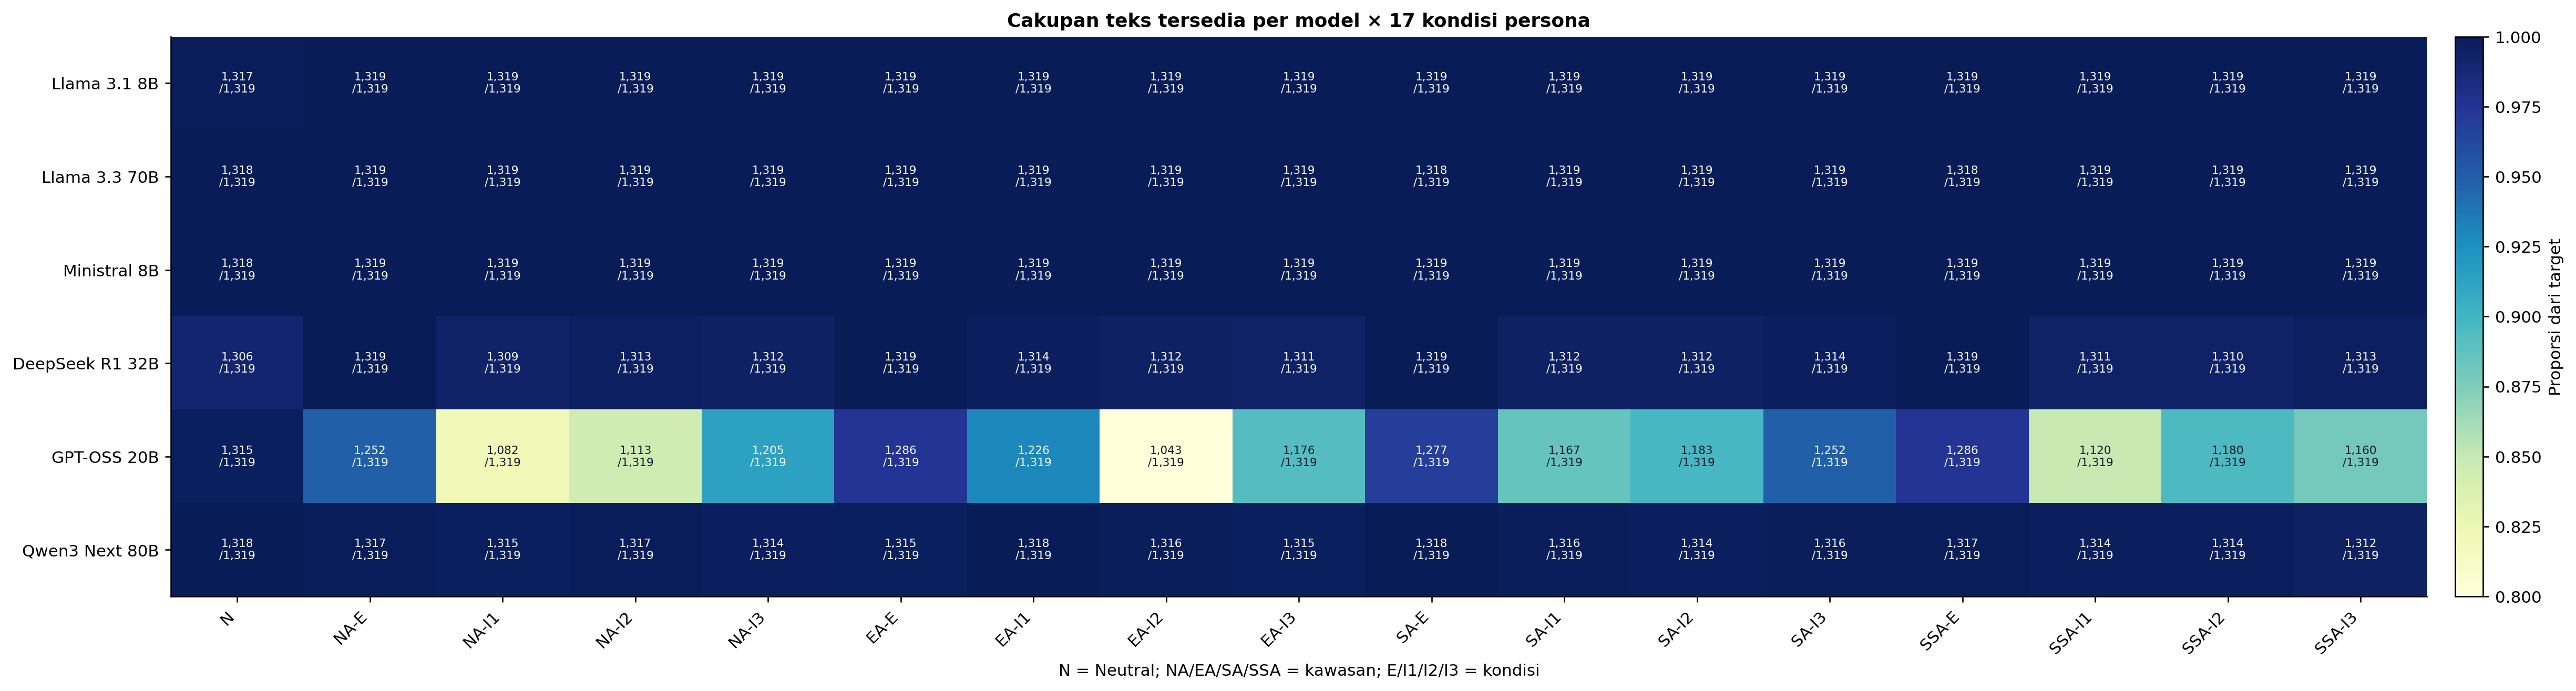

,model,persona,target,n_text_available,n_source_gap,n_missing_text,text_coverage_rate
75,GPT-OSS 20B,east_asian_implicit_2,1319,1043,0,1,79.08%
70,GPT-OSS 20B,north_american_implicit_1,1319,1082,0,6,82.03%
71,GPT-OSS 20B,north_american_implicit_2,1319,1113,0,5,84.38%
82,GPT-OSS 20B,sub_saharan_african_implicit_1,1319,1120,0,0,84.91%
84,GPT-OSS 20B,sub_saharan_african_implicit_3,1319,1160,0,2,87.95%
78,GPT-OSS 20B,south_asian_implicit_1,1319,1167,0,3,88.48%
76,GPT-OSS 20B,east_asian_implicit_3,1319,1176,0,5,89.16%
83,GPT-OSS 20B,sub_saharan_african_implicit_2,1319,1180,0,7,89.46%
79,GPT-OSS 20B,south_asian_implicit_2,1319,1183,0,0,89.69%
72,GPT-OSS 20B,north_american_implicit_3,1319,1205,0,1,91.36%


In [2]:
provenance = pd.DataFrame([
    ("Versi pipeline", run_manifest["pipeline_version"]),
    ("Versi visual", bundle_manifest["bundle_version"]),
    ("Jumlah model", len(MODEL_LABELS)),
    ("Respons aktual", f"{run_manifest['response_records']:,}"),
    ("Gap sumber", f"{run_manifest['source_gap_records']:,}"),
    ("Bootstrap", f"{run_manifest['bootstrap_resamples']:,}"),
    ("Marker terdaftar", len(pd.read_csv(RUN_DIR / "marker_registry.csv"))),
    ("Precision audit", f"{audit_manifest['precision_sample_hits']:,} hit; {audit_manifest['precision_false_positives']} false positive"),
    ("Blind recall", f"{audit_manifest['manual_positive_recall_responses']} respons positif; {audit_manifest['missed_positive_recall_responses']} terlewat"),
    ("Hidden reasoning digunakan", bundle_manifest["hidden_reasoning_used"]),
], columns=["Komponen", "Nilai"])
display(provenance)
show_figure("01_coverage_model_persona.png", width=1700)

coverage = pd.read_csv(BUNDLE_DIR / "response_counts_model_persona.csv")
coverage["model"] = coverage["model_id"].map(MODEL_LABELS)
display(
    coverage.sort_values(["text_coverage_rate", "model", "persona"])
    [["model", "persona", "target", "n_text_available", "n_source_gap", "n_missing_text", "text_coverage_rate"]]
    .head(18).style.format({"text_coverage_rate": "{:.2%}"})
)

## 2. Verbosity dan normalisasi panjang respons

Titik menunjukkan median jumlah kata tiap model dan garis menunjukkan IQR. Marker frekuensi juga tersedia sebagai density per 100 kata, sehingga respons yang lebih panjang tidak otomatis dianggap lebih kuat secara linguistik.

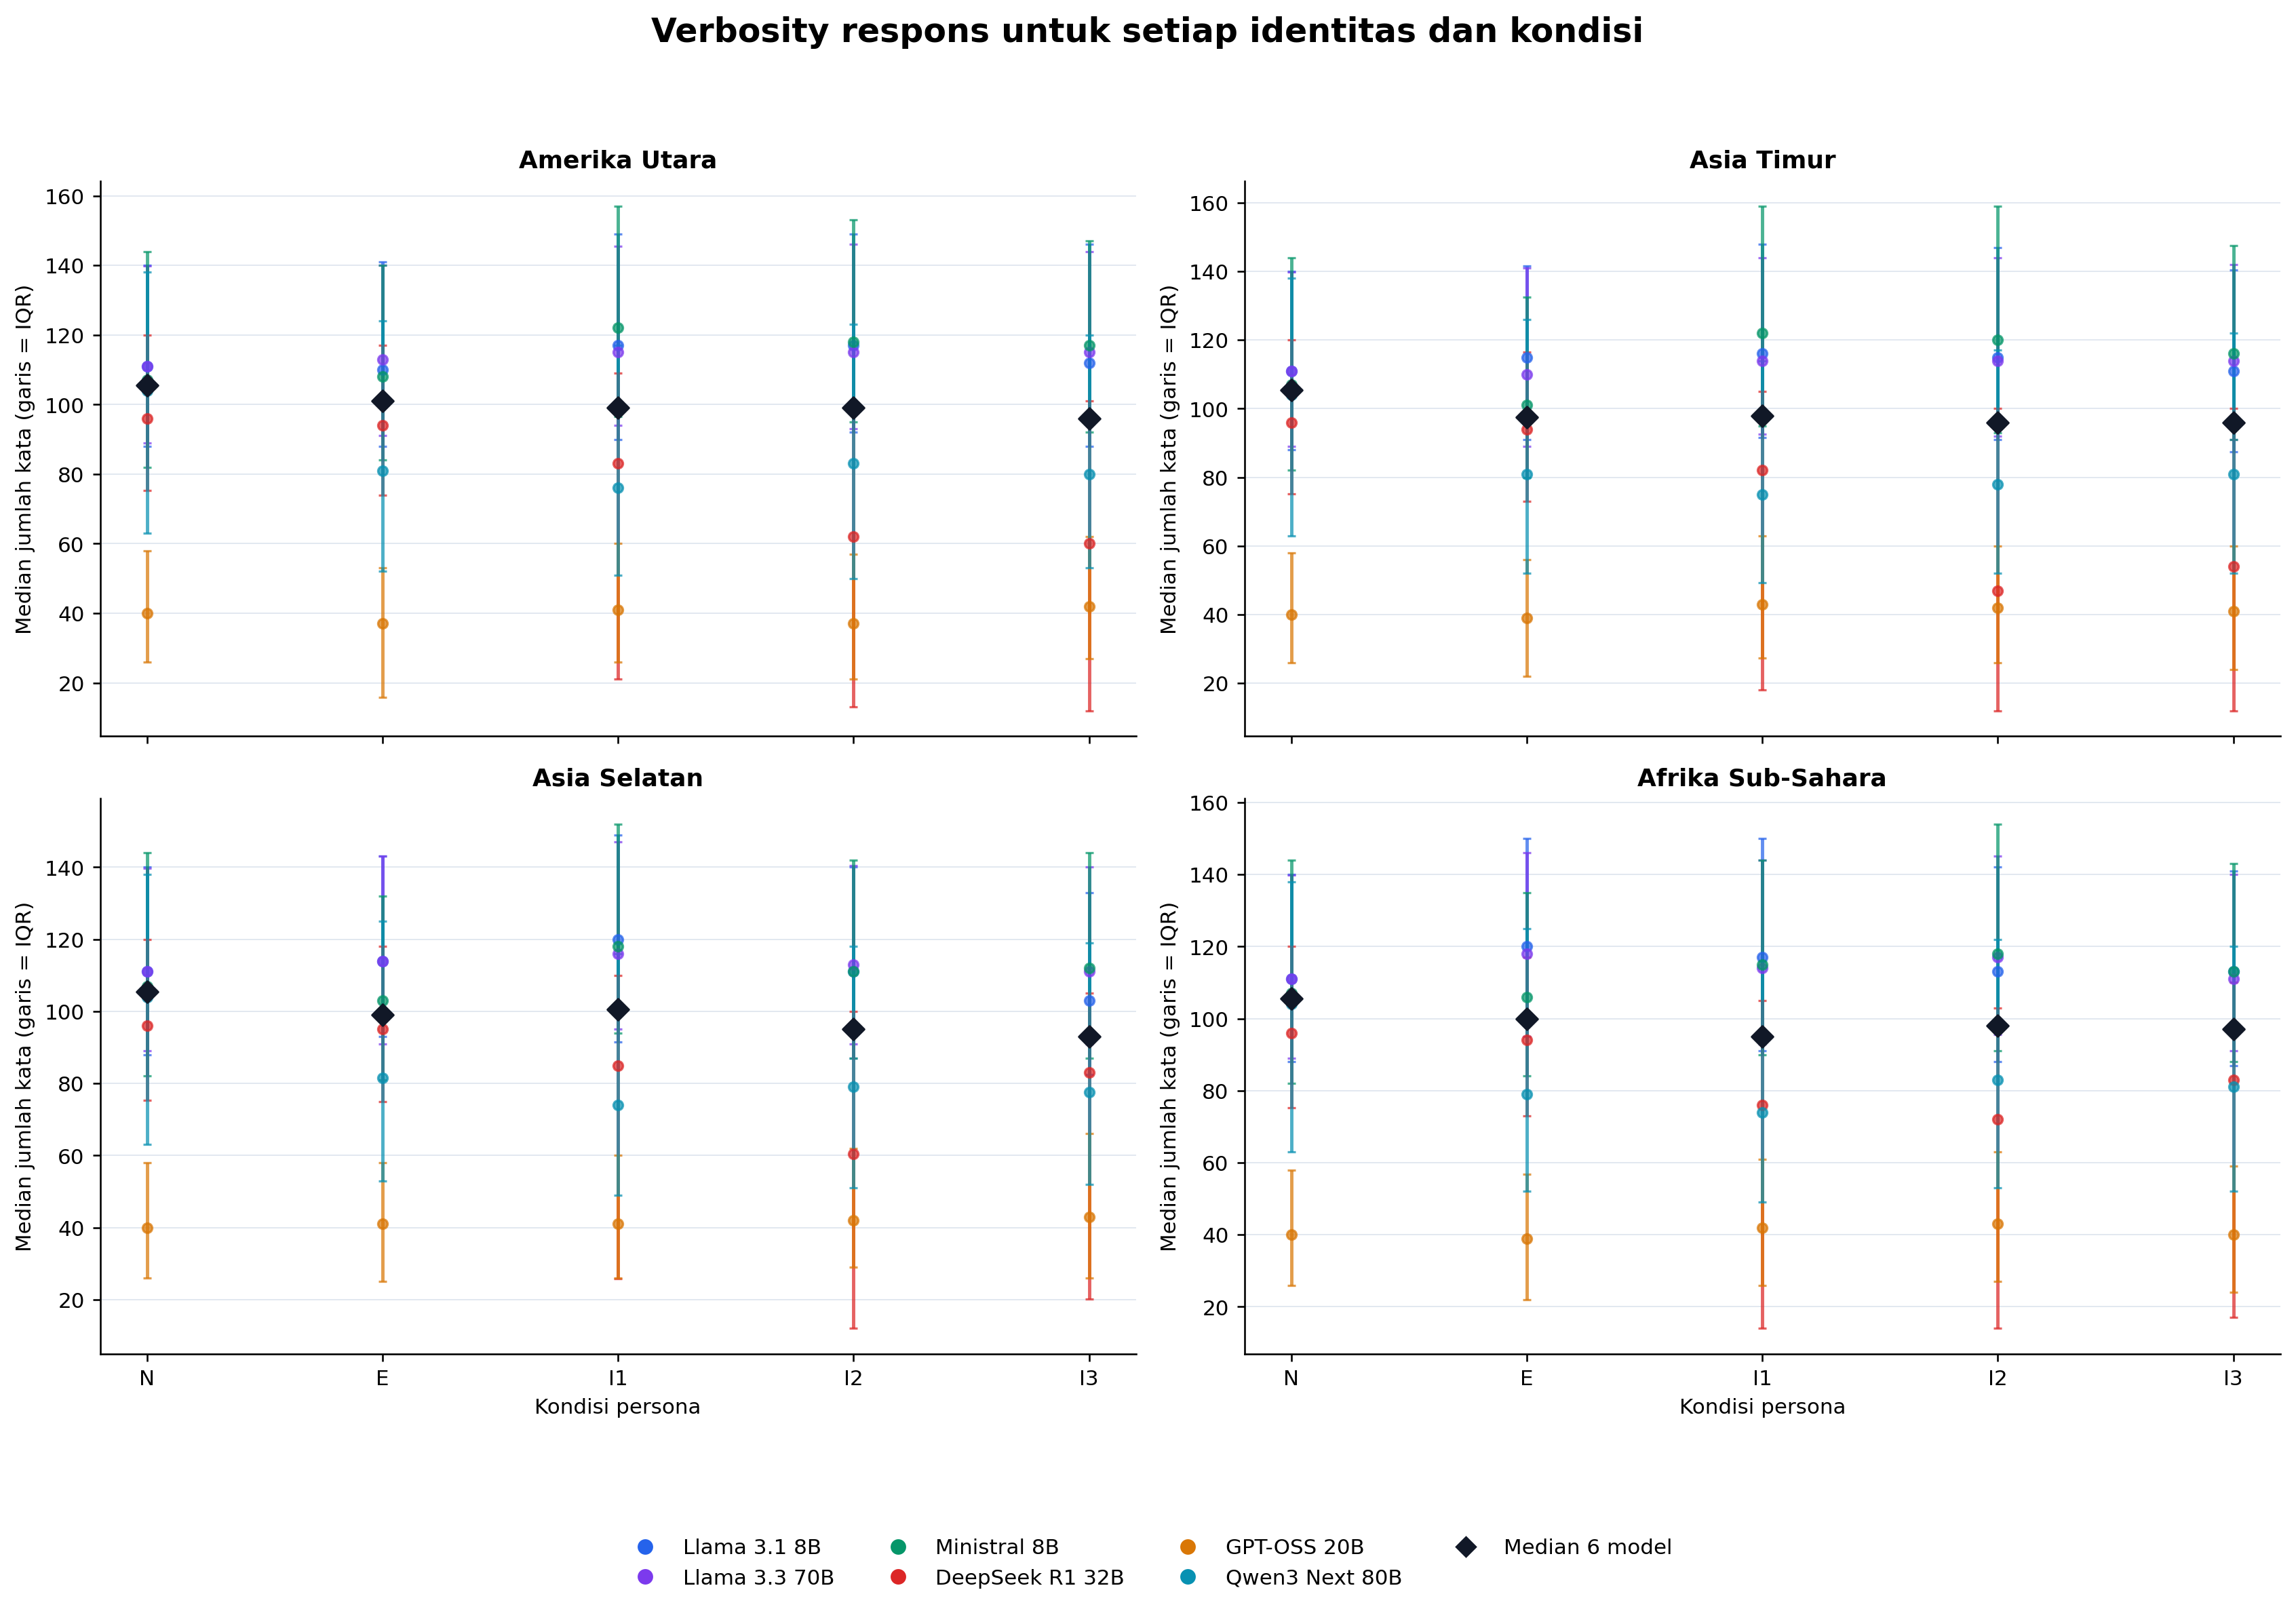

In [3]:
show_figure("02_verbosity_by_identity_condition.png", width=1550)

## 3. Penyebutan identitas kawasan yang selaras

Panel ini menghitung label lengkap yang selaras dengan persona, misalnya `East Asia` untuk Asia Timur. Label lengkap dipilih agar kata seperti `American`, `Chinese`, `Indian`, atau `African` dalam isi soal GSM8K tidak menjadi false positive.

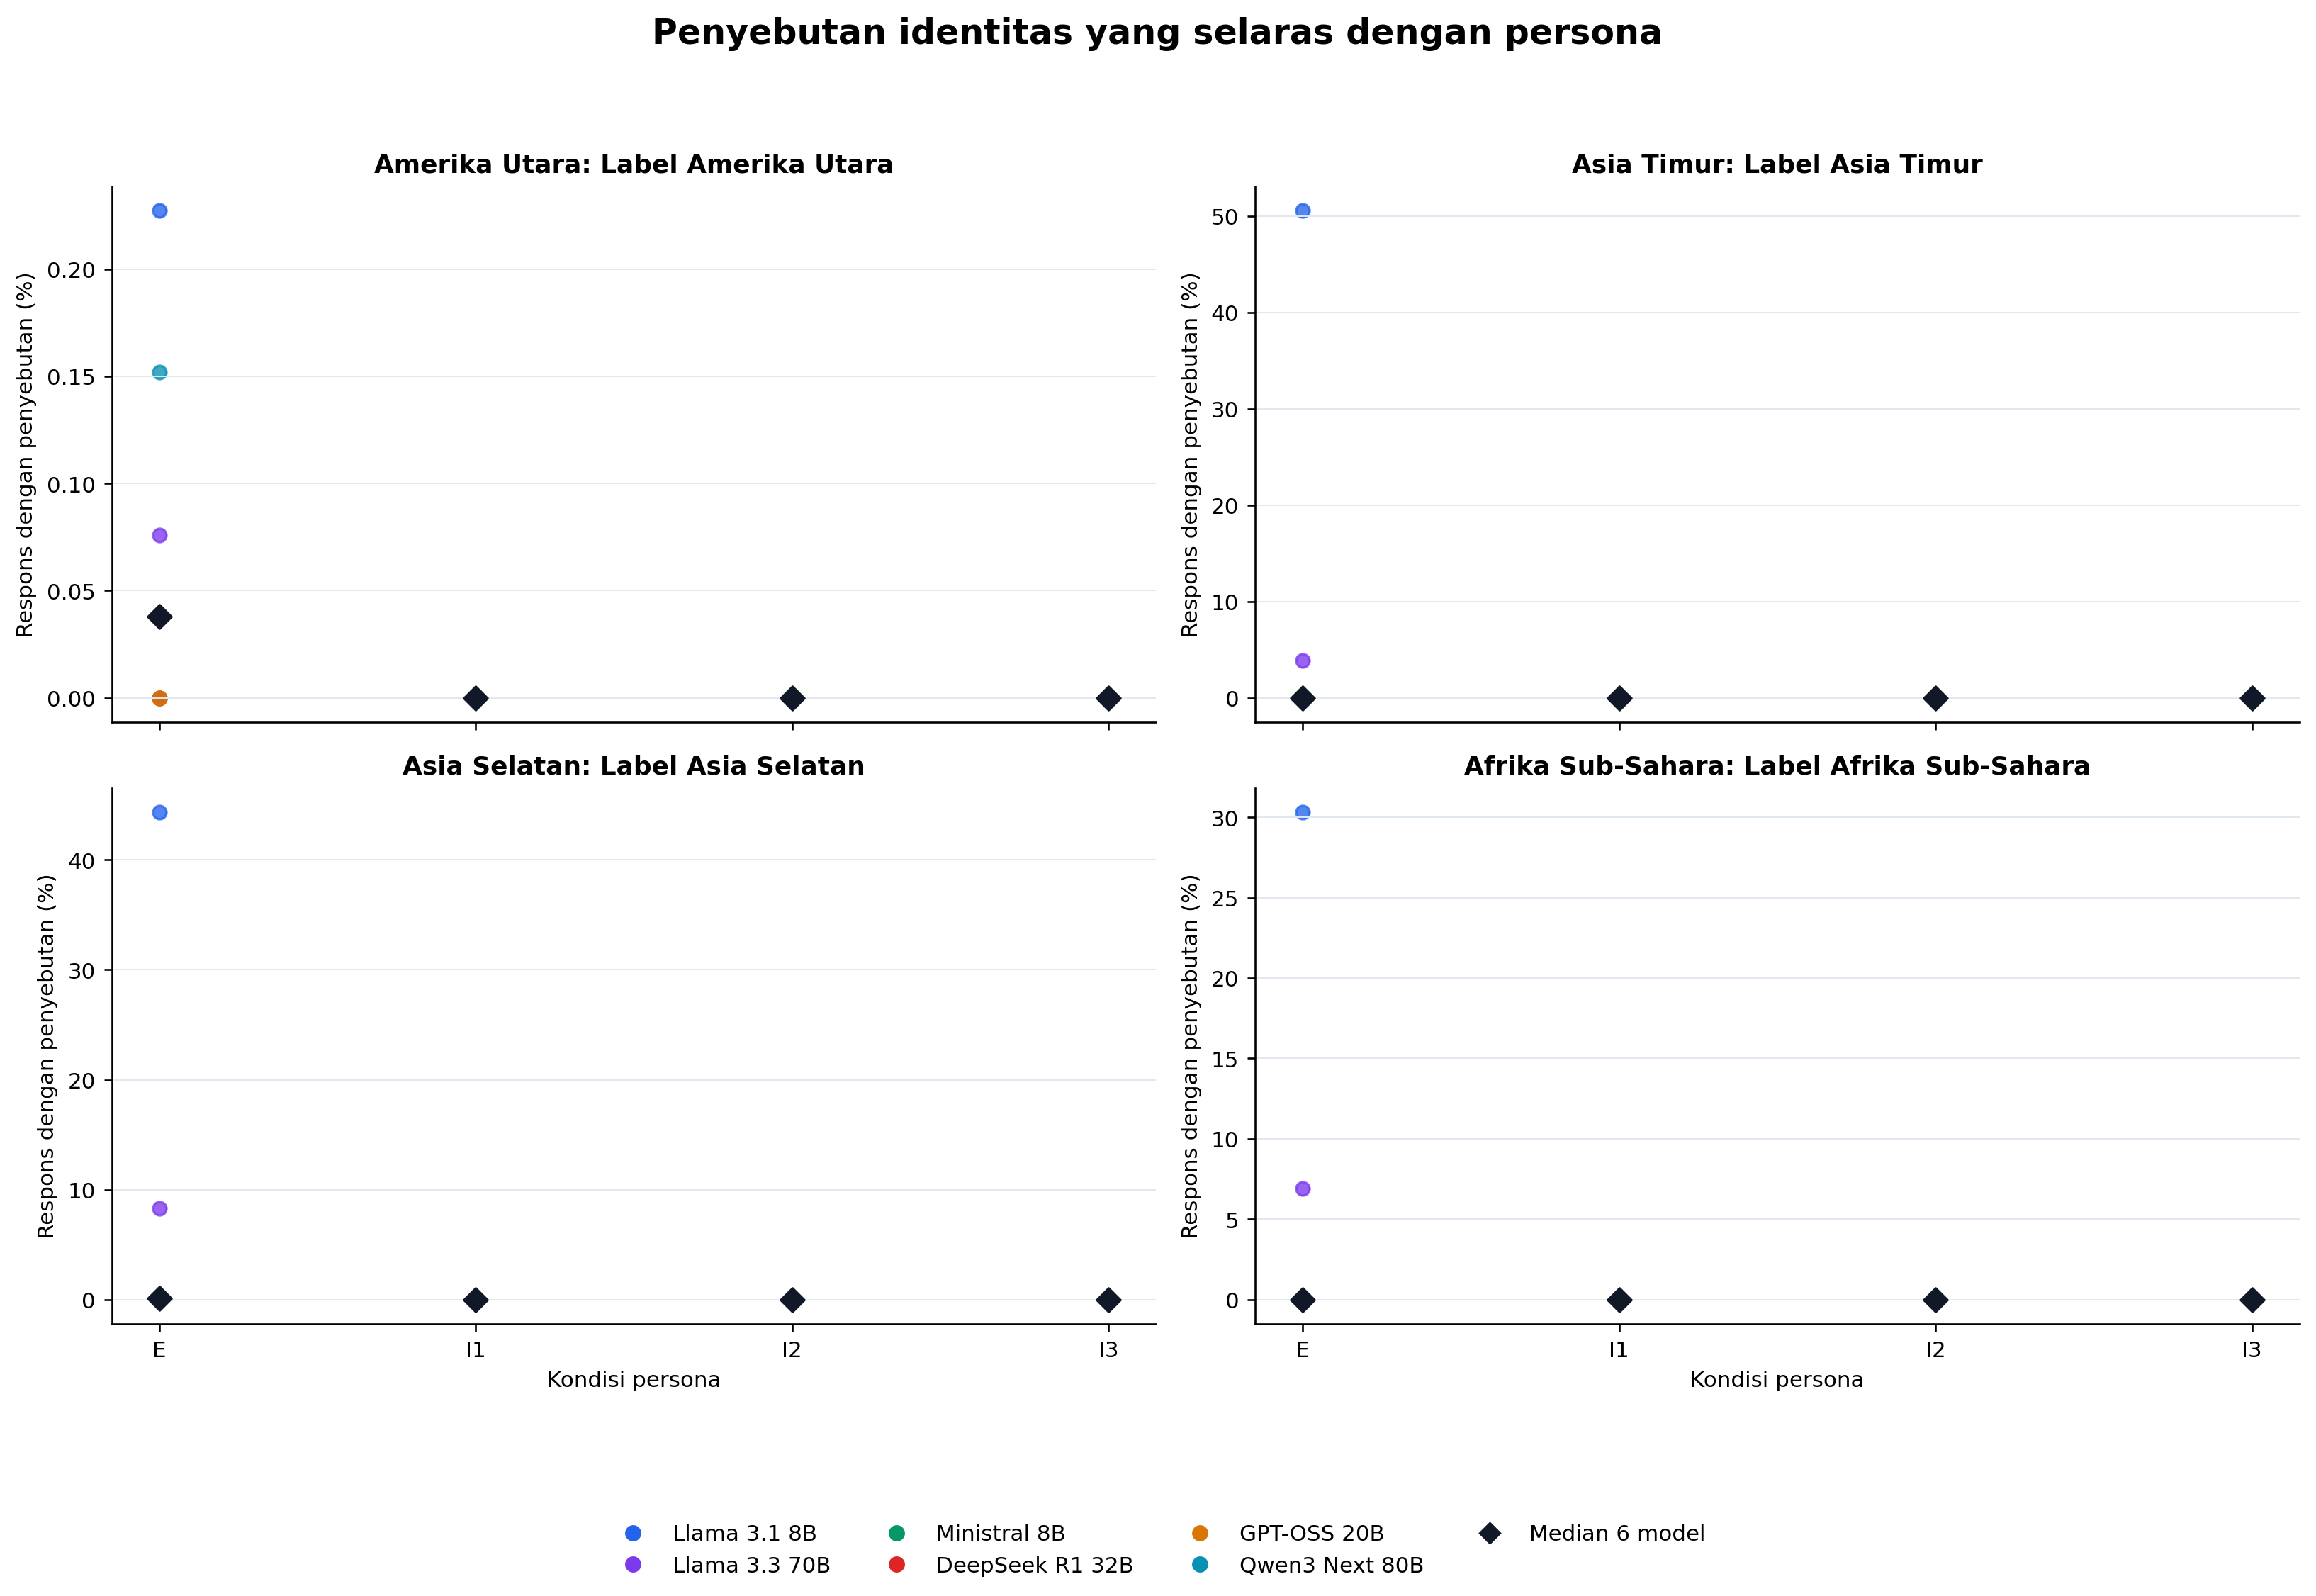

,identity_label,model,n_available,n_present,prevalence_pp
7,Asia Timur,Llama 3.1 8B,1319,667.000000,50.57%
13,Asia Selatan,Llama 3.1 8B,1319,585.000000,44.35%
19,Afrika Sub-Sahara,Llama 3.1 8B,1319,400.000000,30.33%
14,Asia Selatan,Llama 3.3 70B,1318,109.000000,8.27%
20,Afrika Sub-Sahara,Llama 3.3 70B,1318,91.000000,6.90%
8,Asia Timur,Llama 3.3 70B,1319,51.000000,3.87%
1,Amerika Utara,Llama 3.1 8B,1319,3.000000,0.23%
5,Amerika Utara,Qwen3 Next 80B,1317,2.000000,0.15%
15,Asia Selatan,Ministral 8B,1319,2.000000,0.15%
17,Asia Selatan,Qwen3 Next 80B,1318,1.000000,0.08%


In [4]:
show_figure("03_aligned_identity_mentions.png", width=1500)

prevalence = pd.read_csv(BUNDLE_DIR / "regional_marker_prevalence_model_persona.csv")
aligned_rows = []
for identity, marker in ALIGNED.items():
    selected = prevalence[
        prevalence["identity"].eq(identity)
        & prevalence["marker_id"].eq(marker)
        & prevalence["condition"].eq("explicit")
    ].copy()
    selected["identity_label"] = IDENTITY_LABELS[identity]
    selected["model"] = selected["model_id"].map(MODEL_LABELS)
    aligned_rows.append(selected)
aligned_explicit = pd.concat(aligned_rows, ignore_index=True)
display(
    aligned_explicit.sort_values("prevalence_pp", ascending=False)
    [["identity_label", "model", "n_available", "n_present", "prevalence_pp"]]
    .style.format({"prevalence_pp": "{:.2f}%"})
)

## 4. Bentuk akomodasi bahasa regional-budaya pada Explicit

Selain label kawasan, respons dapat menyapa asal pengguna, melakukan mirroring, memakai sapaan geografis umum, menyebut budaya/tradisi, membawa nama atau istilah dari warmup, atau memberi framing budaya pada soal. Nilai tiap model dipertahankan agar responsivitas satu model tidak tertutup rerata agregat.

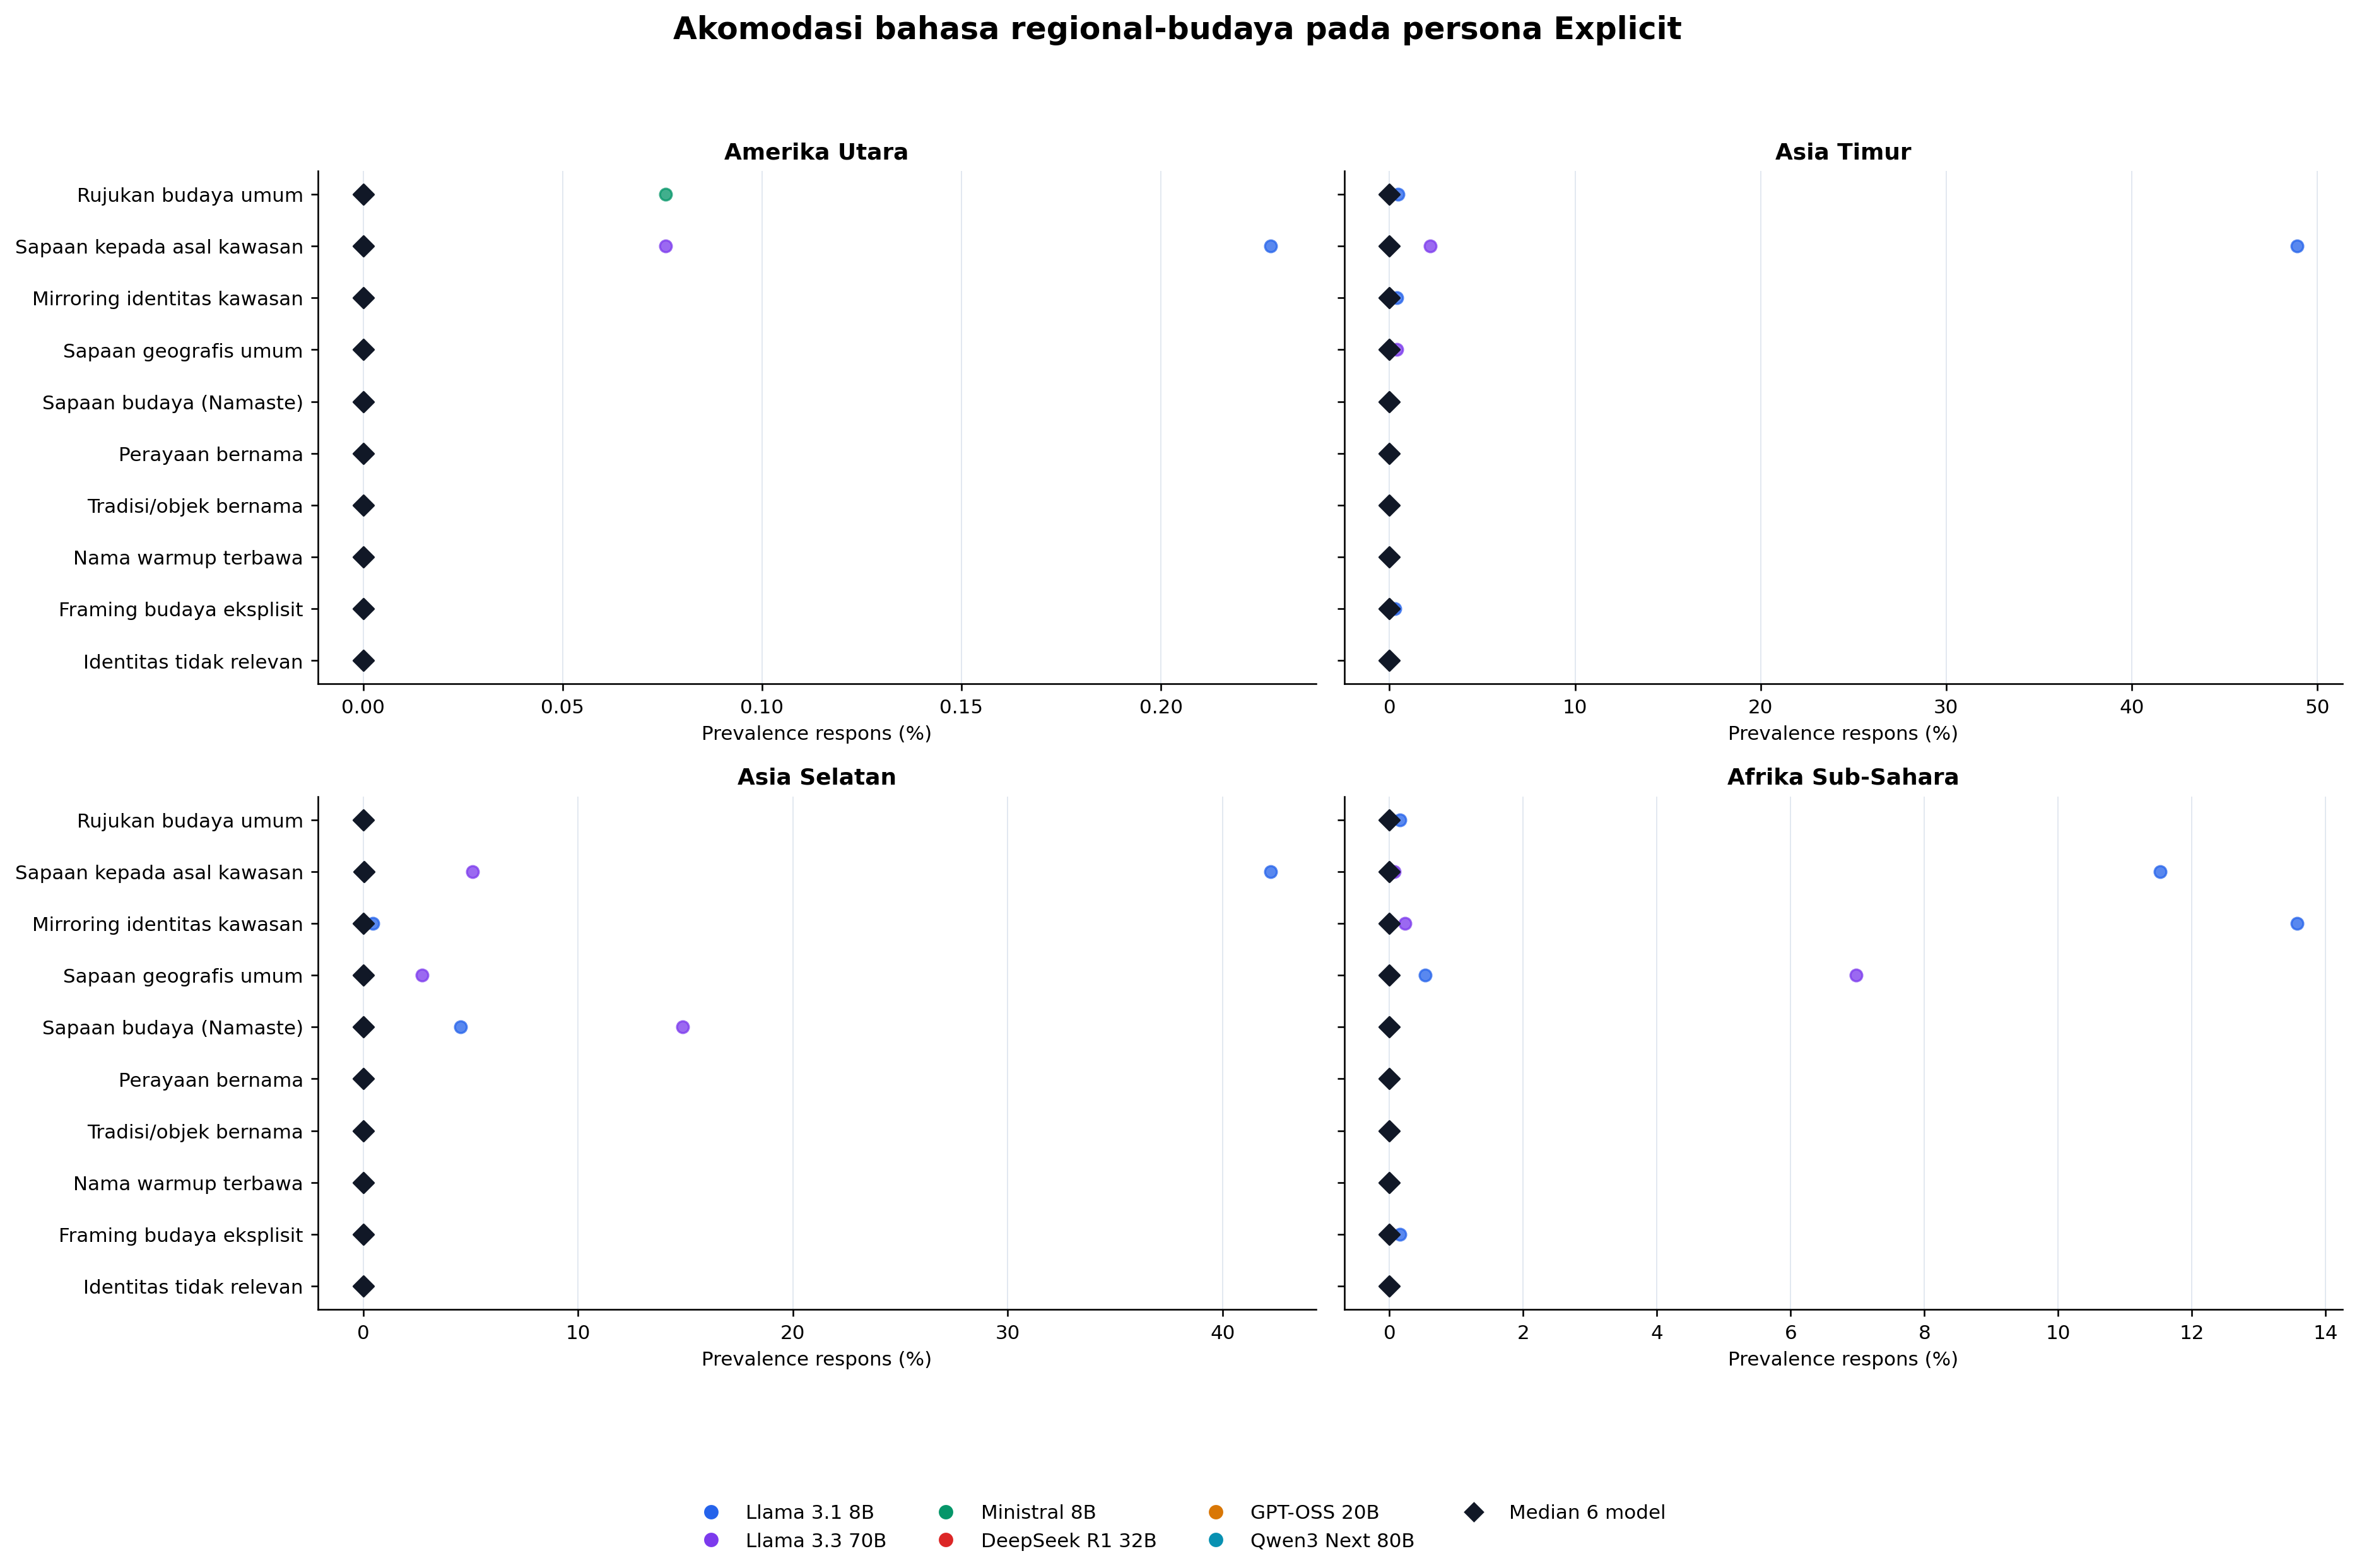

In [5]:
show_figure("04_regional_accommodation_explicit.png", width=1650)

## 5. Istilah regional-budaya yang benar-benar muncul

Lollipop adalah tampilan kuantitatif per 10.000 kata dengan bobot model setara. Word cloud memakai bobot yang sama hanya sebagai ringkasan visual. Keduanya **bukan kumpulan semua kata yang sering dipakai**: hanya closed lexicon regional-budaya pada respons E, I1, I2, dan I3, termasuk label kawasan, `Namaste`, `Diwali`, `hongbao`, `mehendi`, `diyas`, serta sapaan geografis yang ditemukan saat audit.

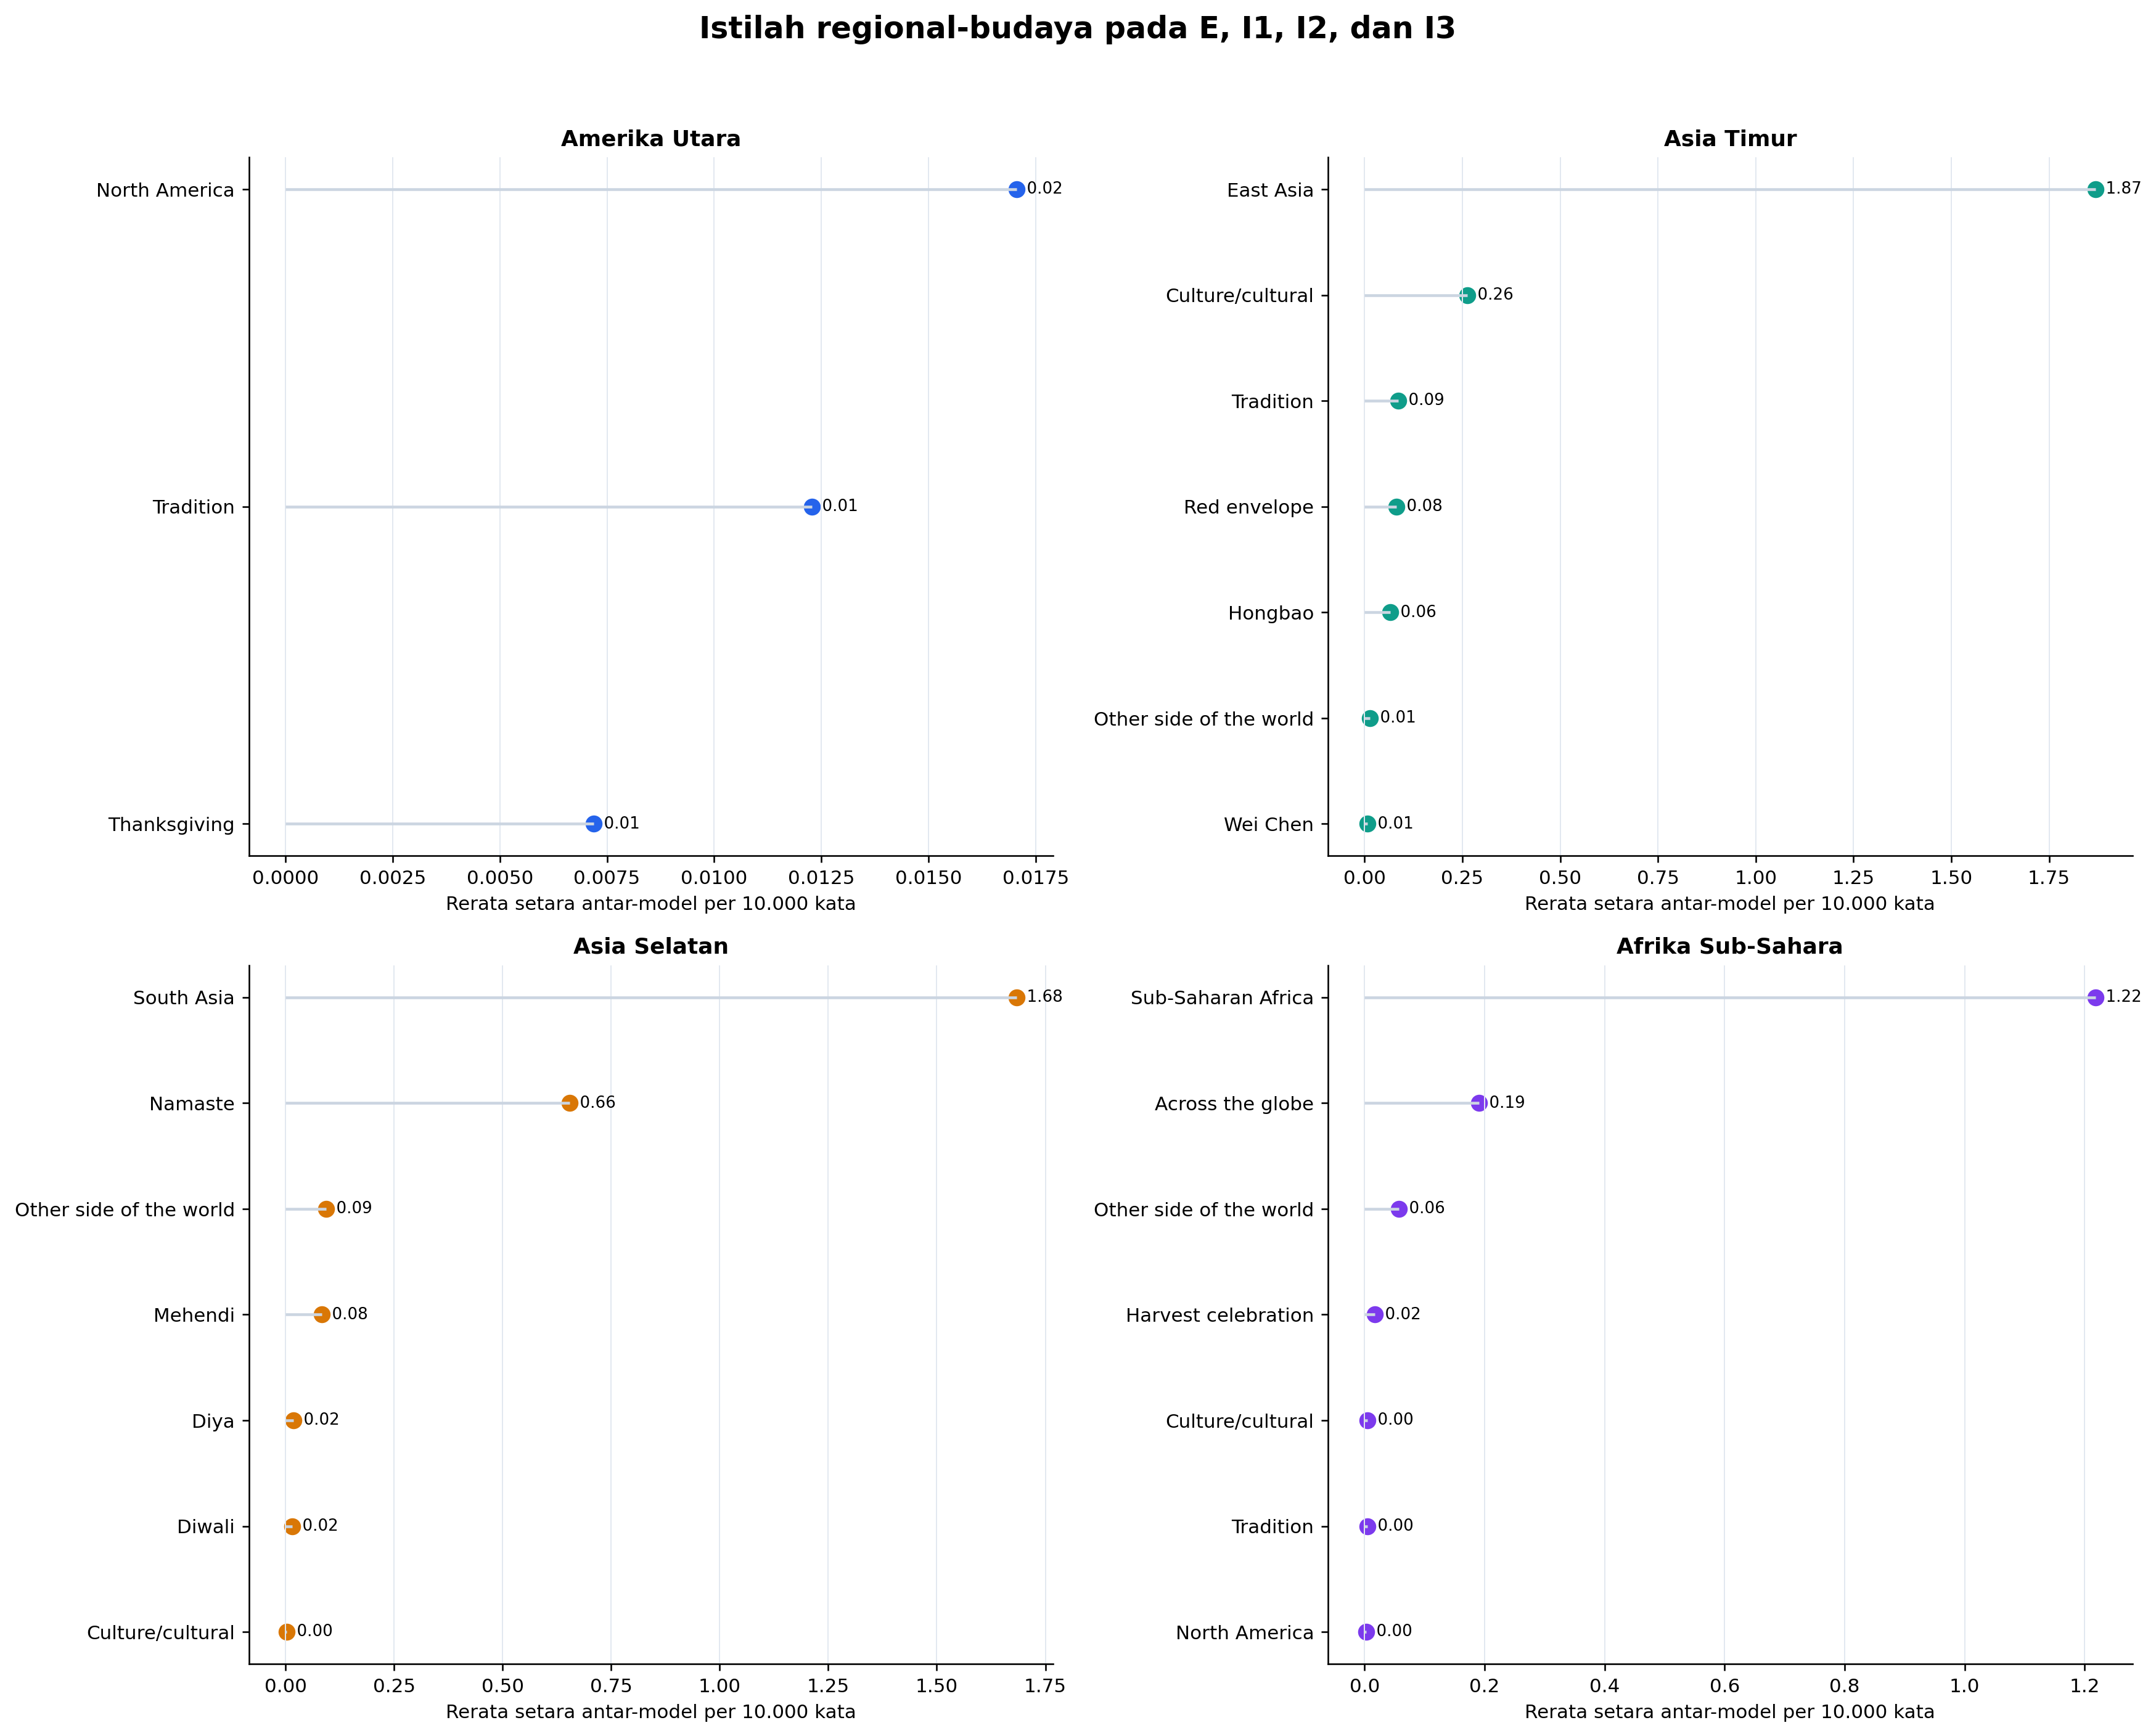

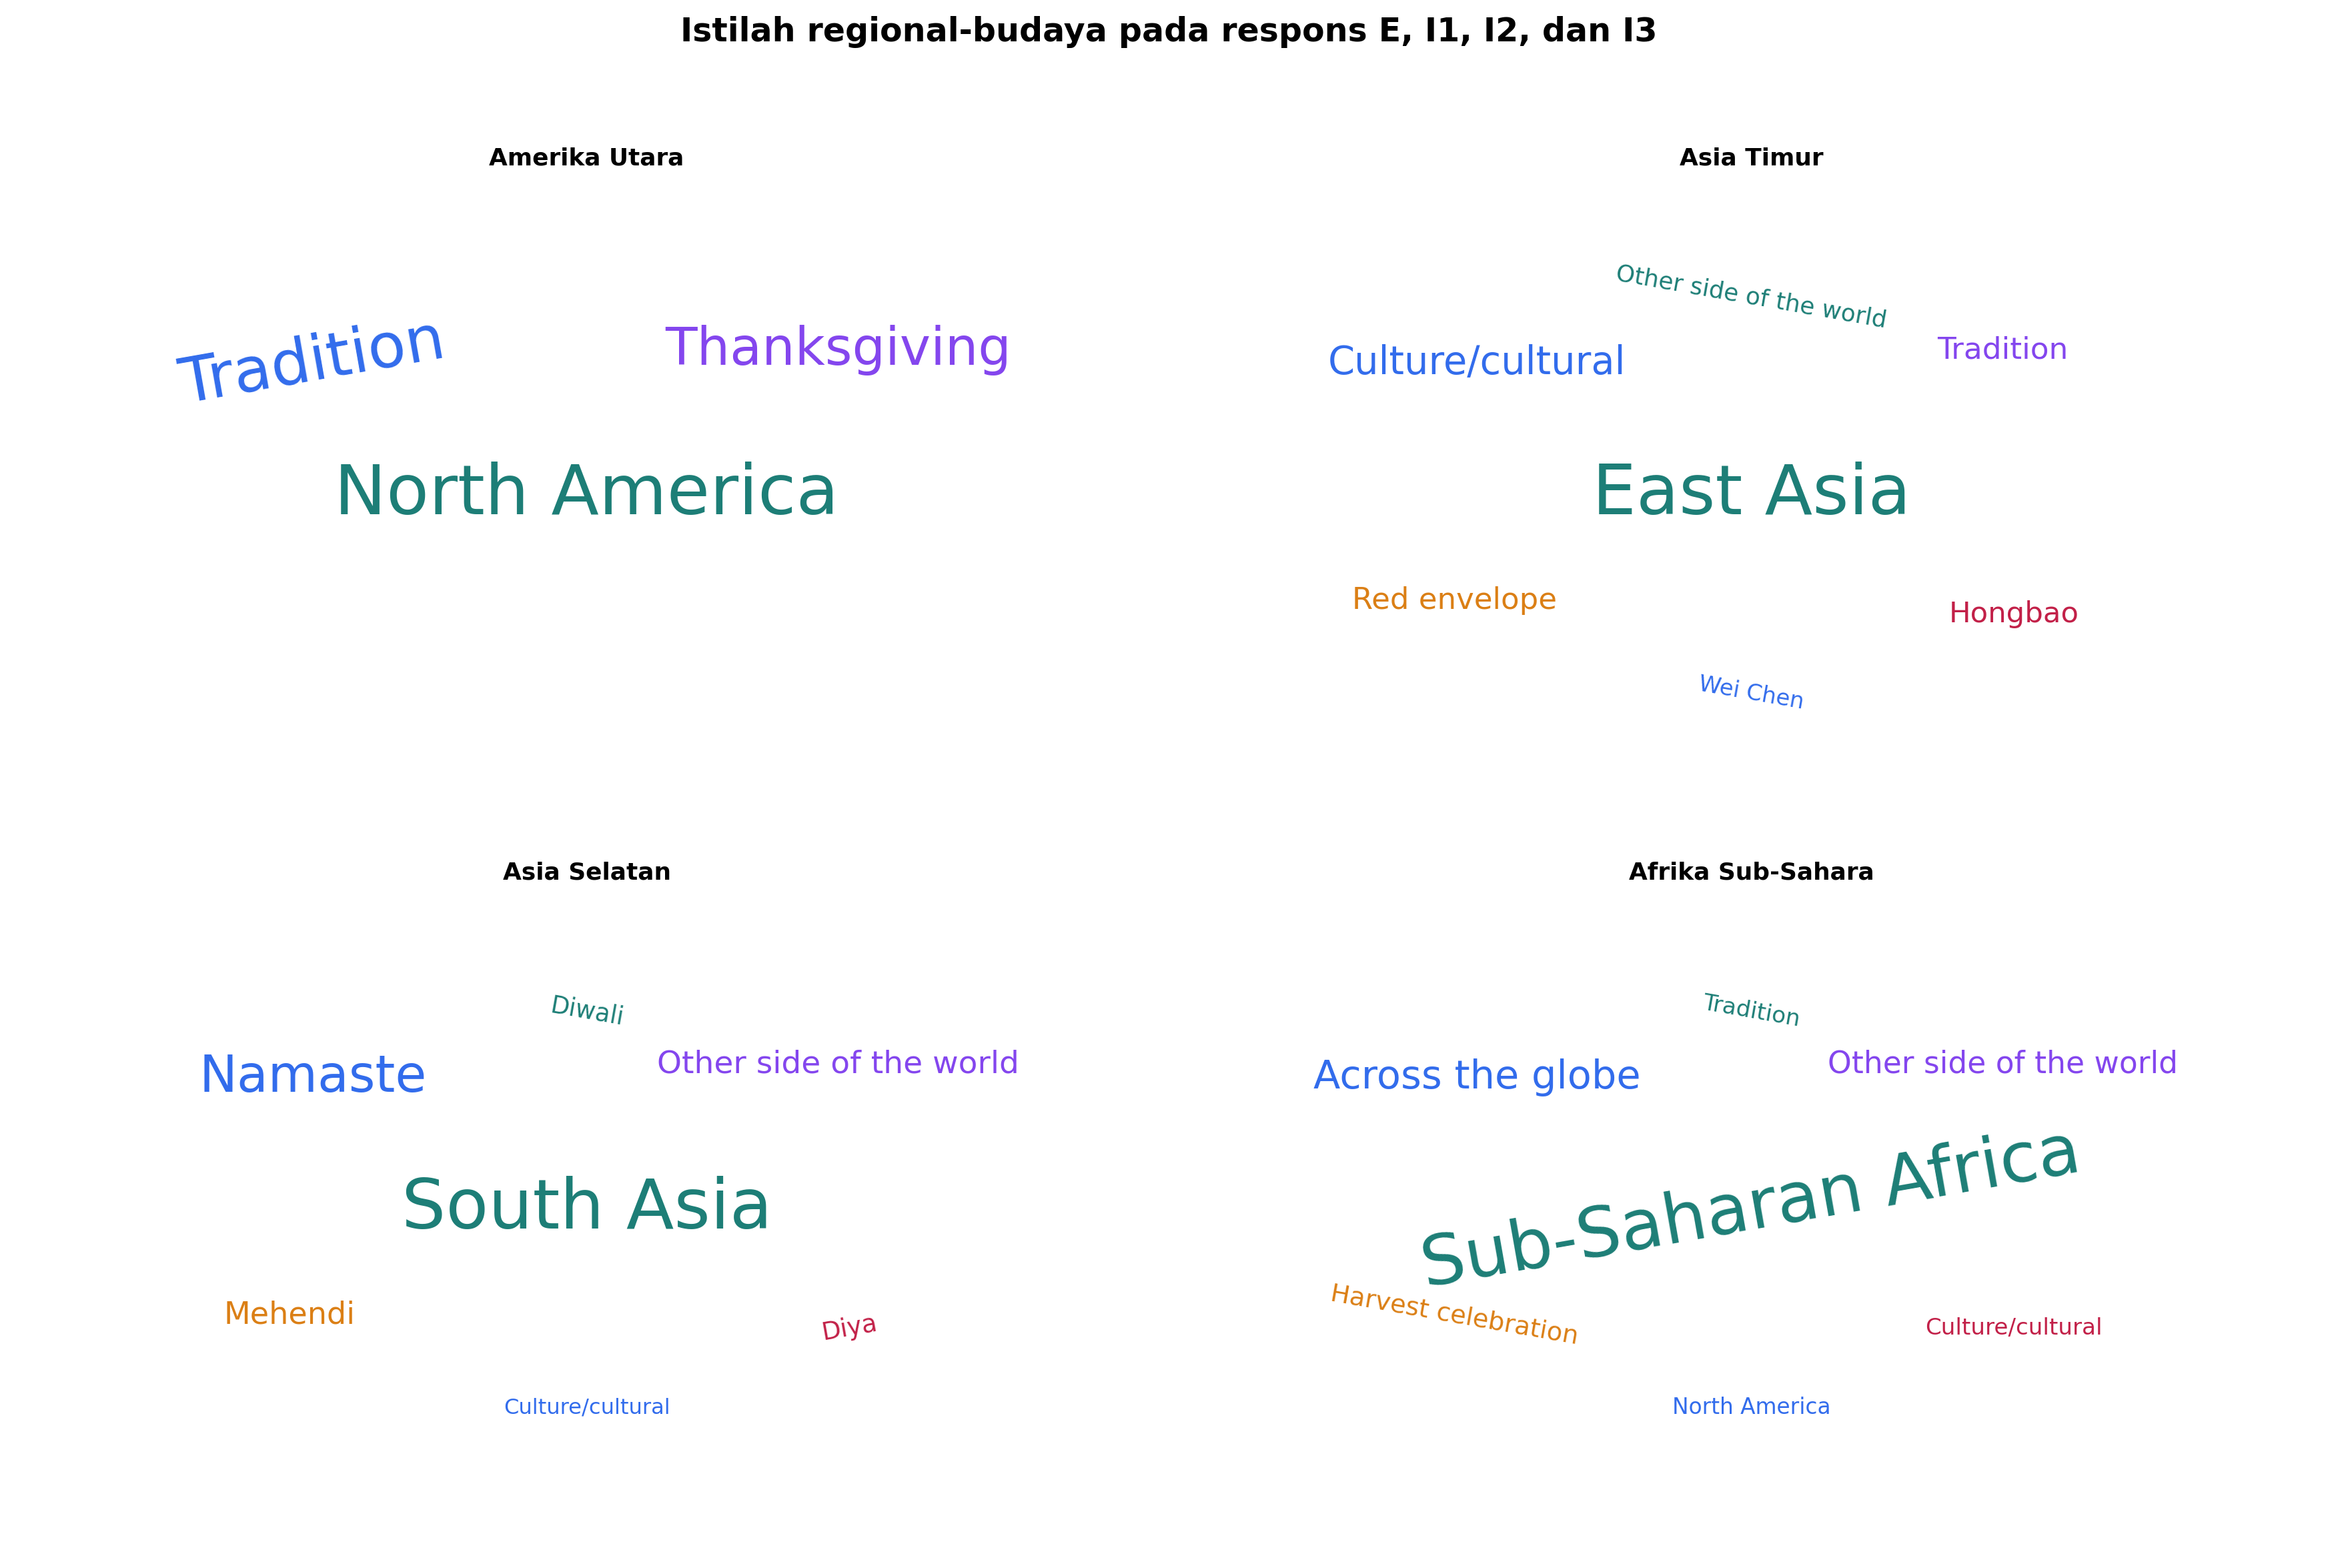

,identity,term,occurrence_per_10k,response_prevalence_pp,total_occurrences
84,Afrika Sub-Sahara,Sub-Saharan Africa,1.219,1.551%,504
66,Afrika Sub-Sahara,Across the globe,0.191,0.240%,76
80,Afrika Sub-Sahara,Other side of the world,0.057,0.073%,23
71,Afrika Sub-Sahara,Harvest celebration,0.017,0.019%,7
67,Afrika Sub-Sahara,Culture/cultural,0.005,0.006%,2
86,Afrika Sub-Sahara,Tradition,0.005,0.006%,2
79,Afrika Sub-Sahara,North America,0.002,0.003%,1
35,Amerika Utara,North America,0.017,0.019%,6
42,Amerika Utara,Tradition,0.012,0.013%,5
41,Amerika Utara,Thanksgiving,0.007,0.009%,3


In [6]:
show_figure("05_regional_terms_ranked.png", width=1550)
show_figure("06_regional_terms_cloud.png", width=1550)

terms = pd.read_csv(BUNDLE_DIR / "regional_term_prevalence_model_persona.csv")
term_summary = (
    terms[~terms["condition"].eq("neutral")]
    .groupby(["identity", "term"], as_index=False)
    .agg(
        occurrence_per_10k=("occurrences_per_10k_words", "mean"),
        response_prevalence_pp=("response_prevalence_pp", "mean"),
        total_occurrences=("occurrences", "sum"),
    )
)
term_summary = term_summary[term_summary["occurrence_per_10k"].gt(0)]
term_summary["identity"] = term_summary["identity"].map(IDENTITY_LABELS)
display(
    term_summary.sort_values(["identity", "occurrence_per_10k"], ascending=[True, False])
    .groupby("identity", sort=False).head(10)
    .style.format({"occurrence_per_10k": "{:.3f}", "response_prevalence_pp": "{:.3f}%"})
)

## 6. Efek marker budaya terhadap Neutral

Titik adalah perubahan prevalence pada pasangan model×soal; garis adalah bootstrap CI 95%. E, I1, I2, dan I3 memakai skala yang sama di dalam setiap figur. Transparansi rendah menandai hasil yang tidak lolos koreksi Holm.

### Amerika Utara

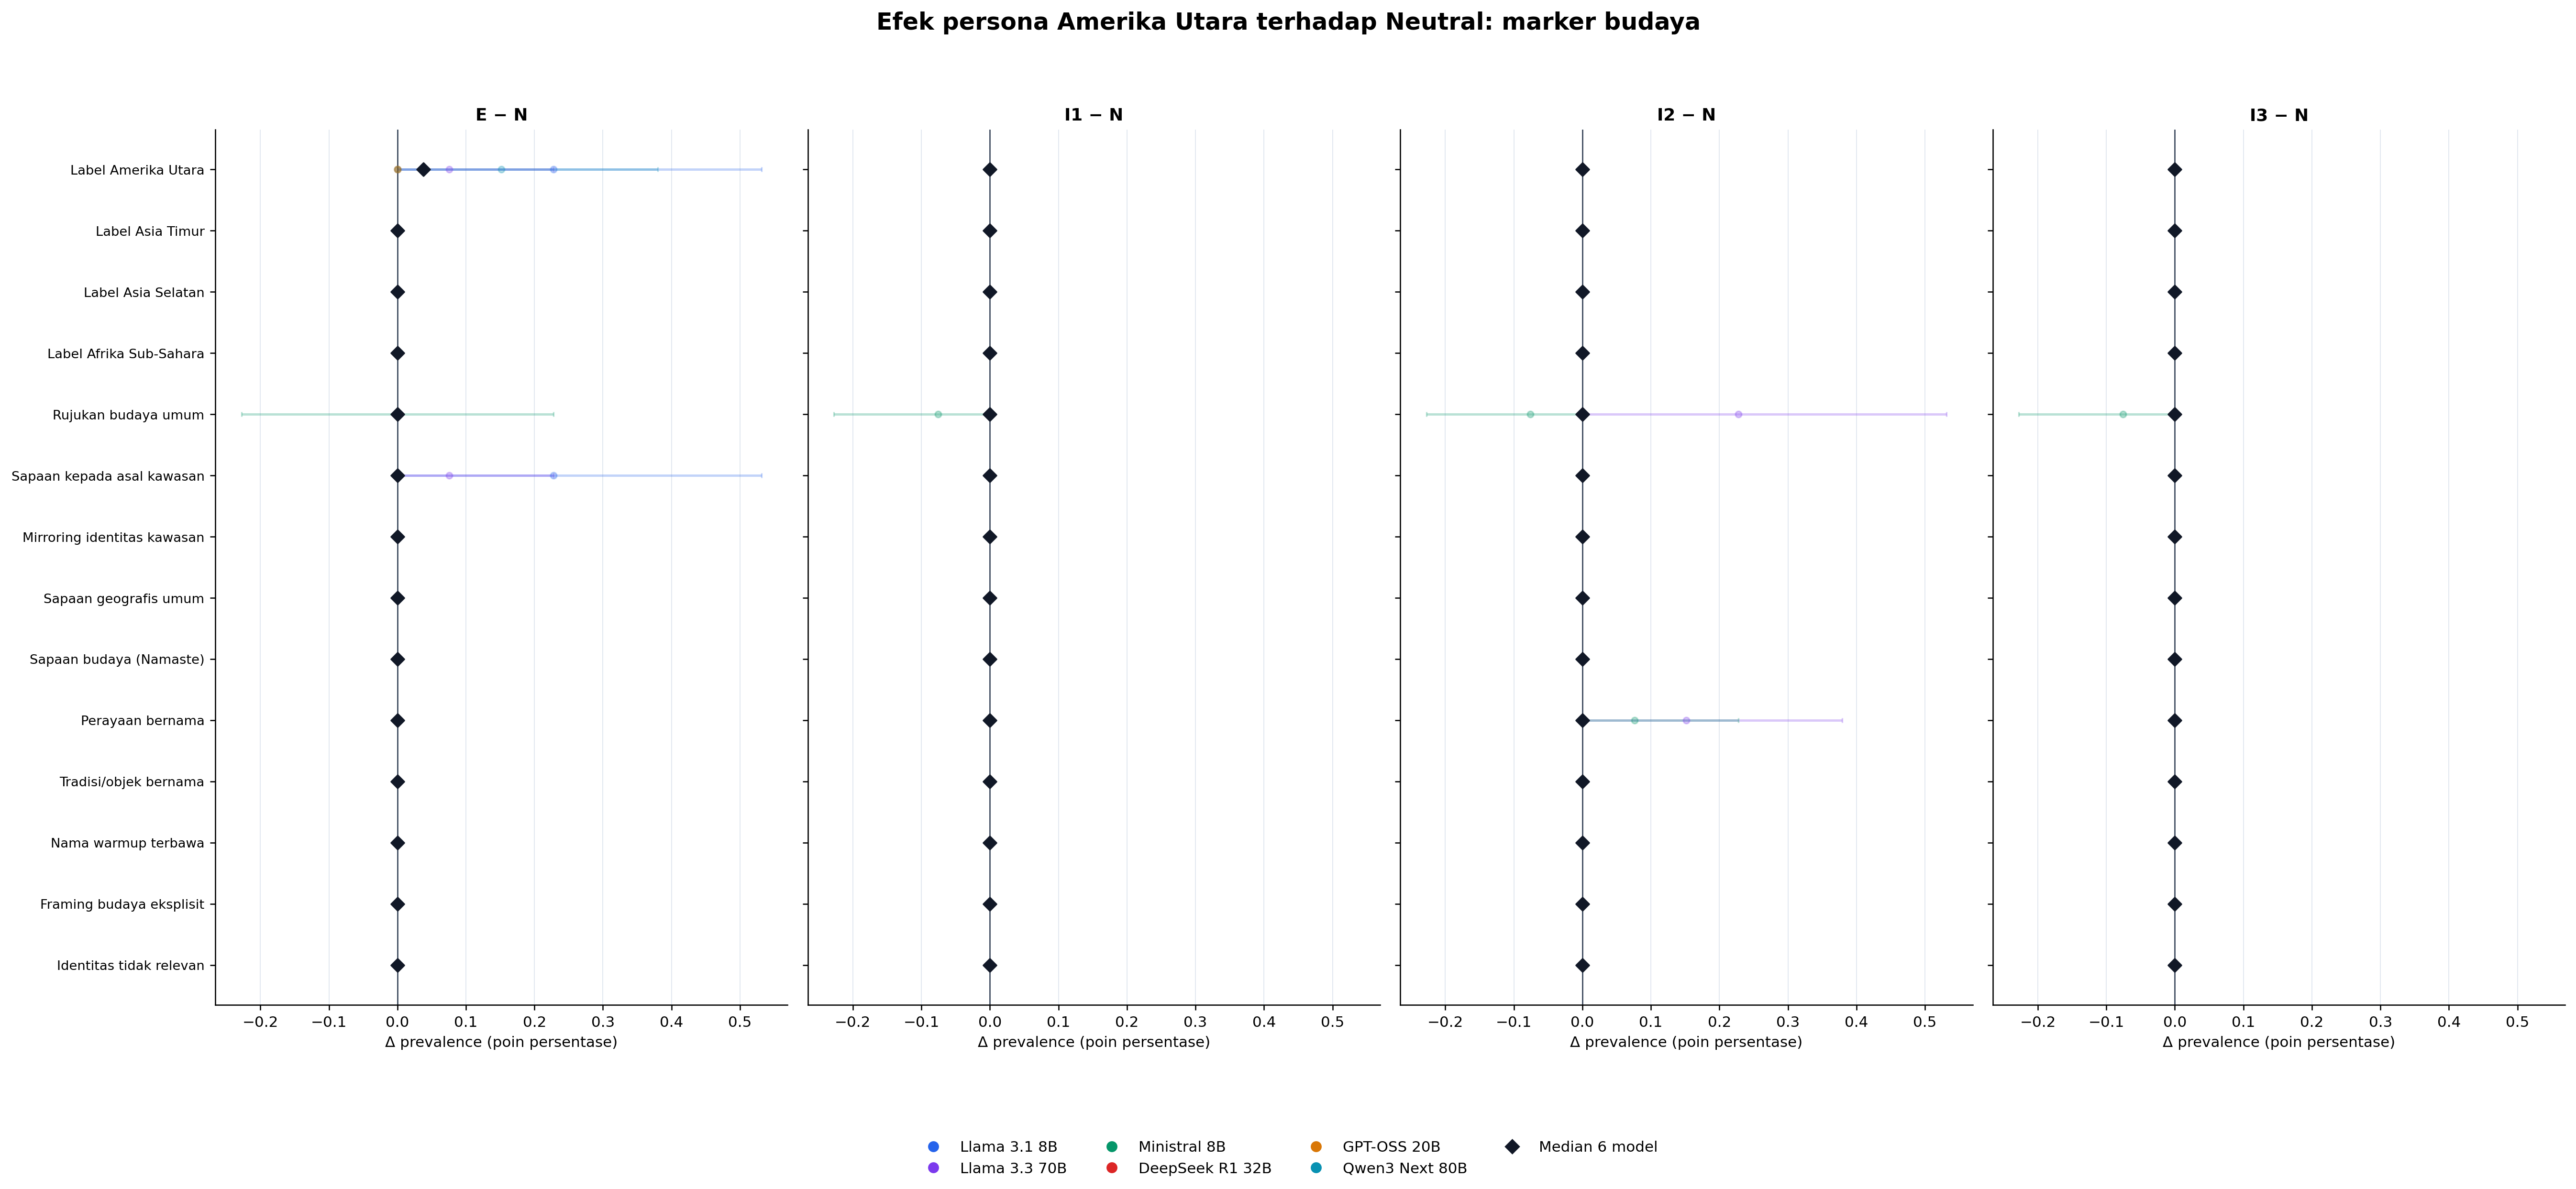

### Asia Timur

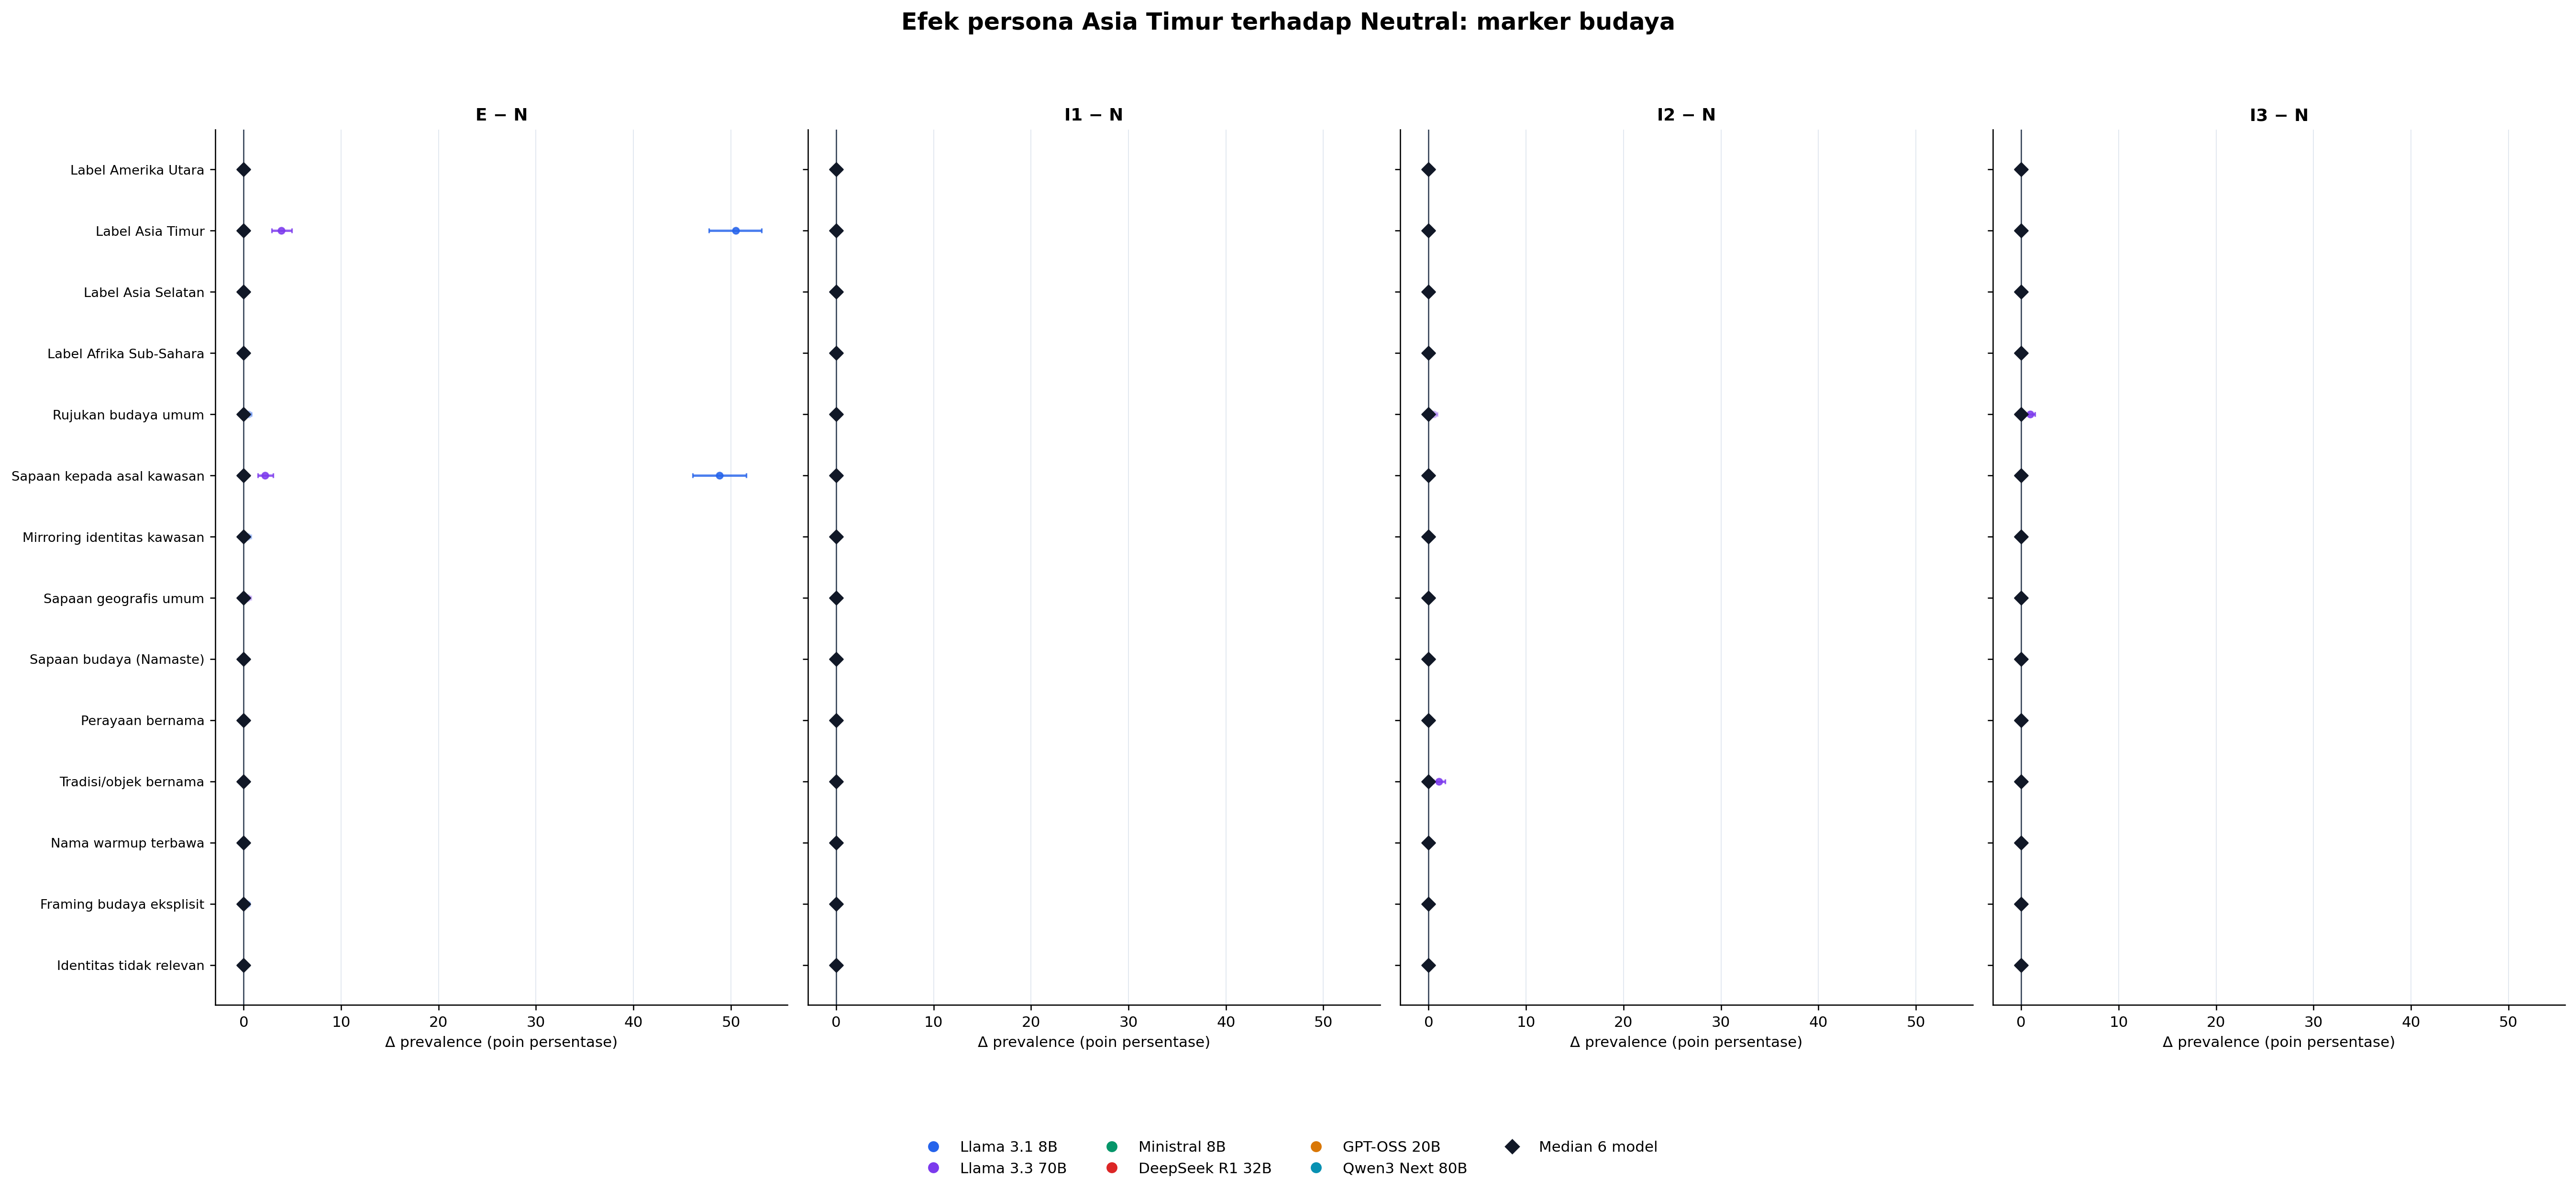

### Asia Selatan

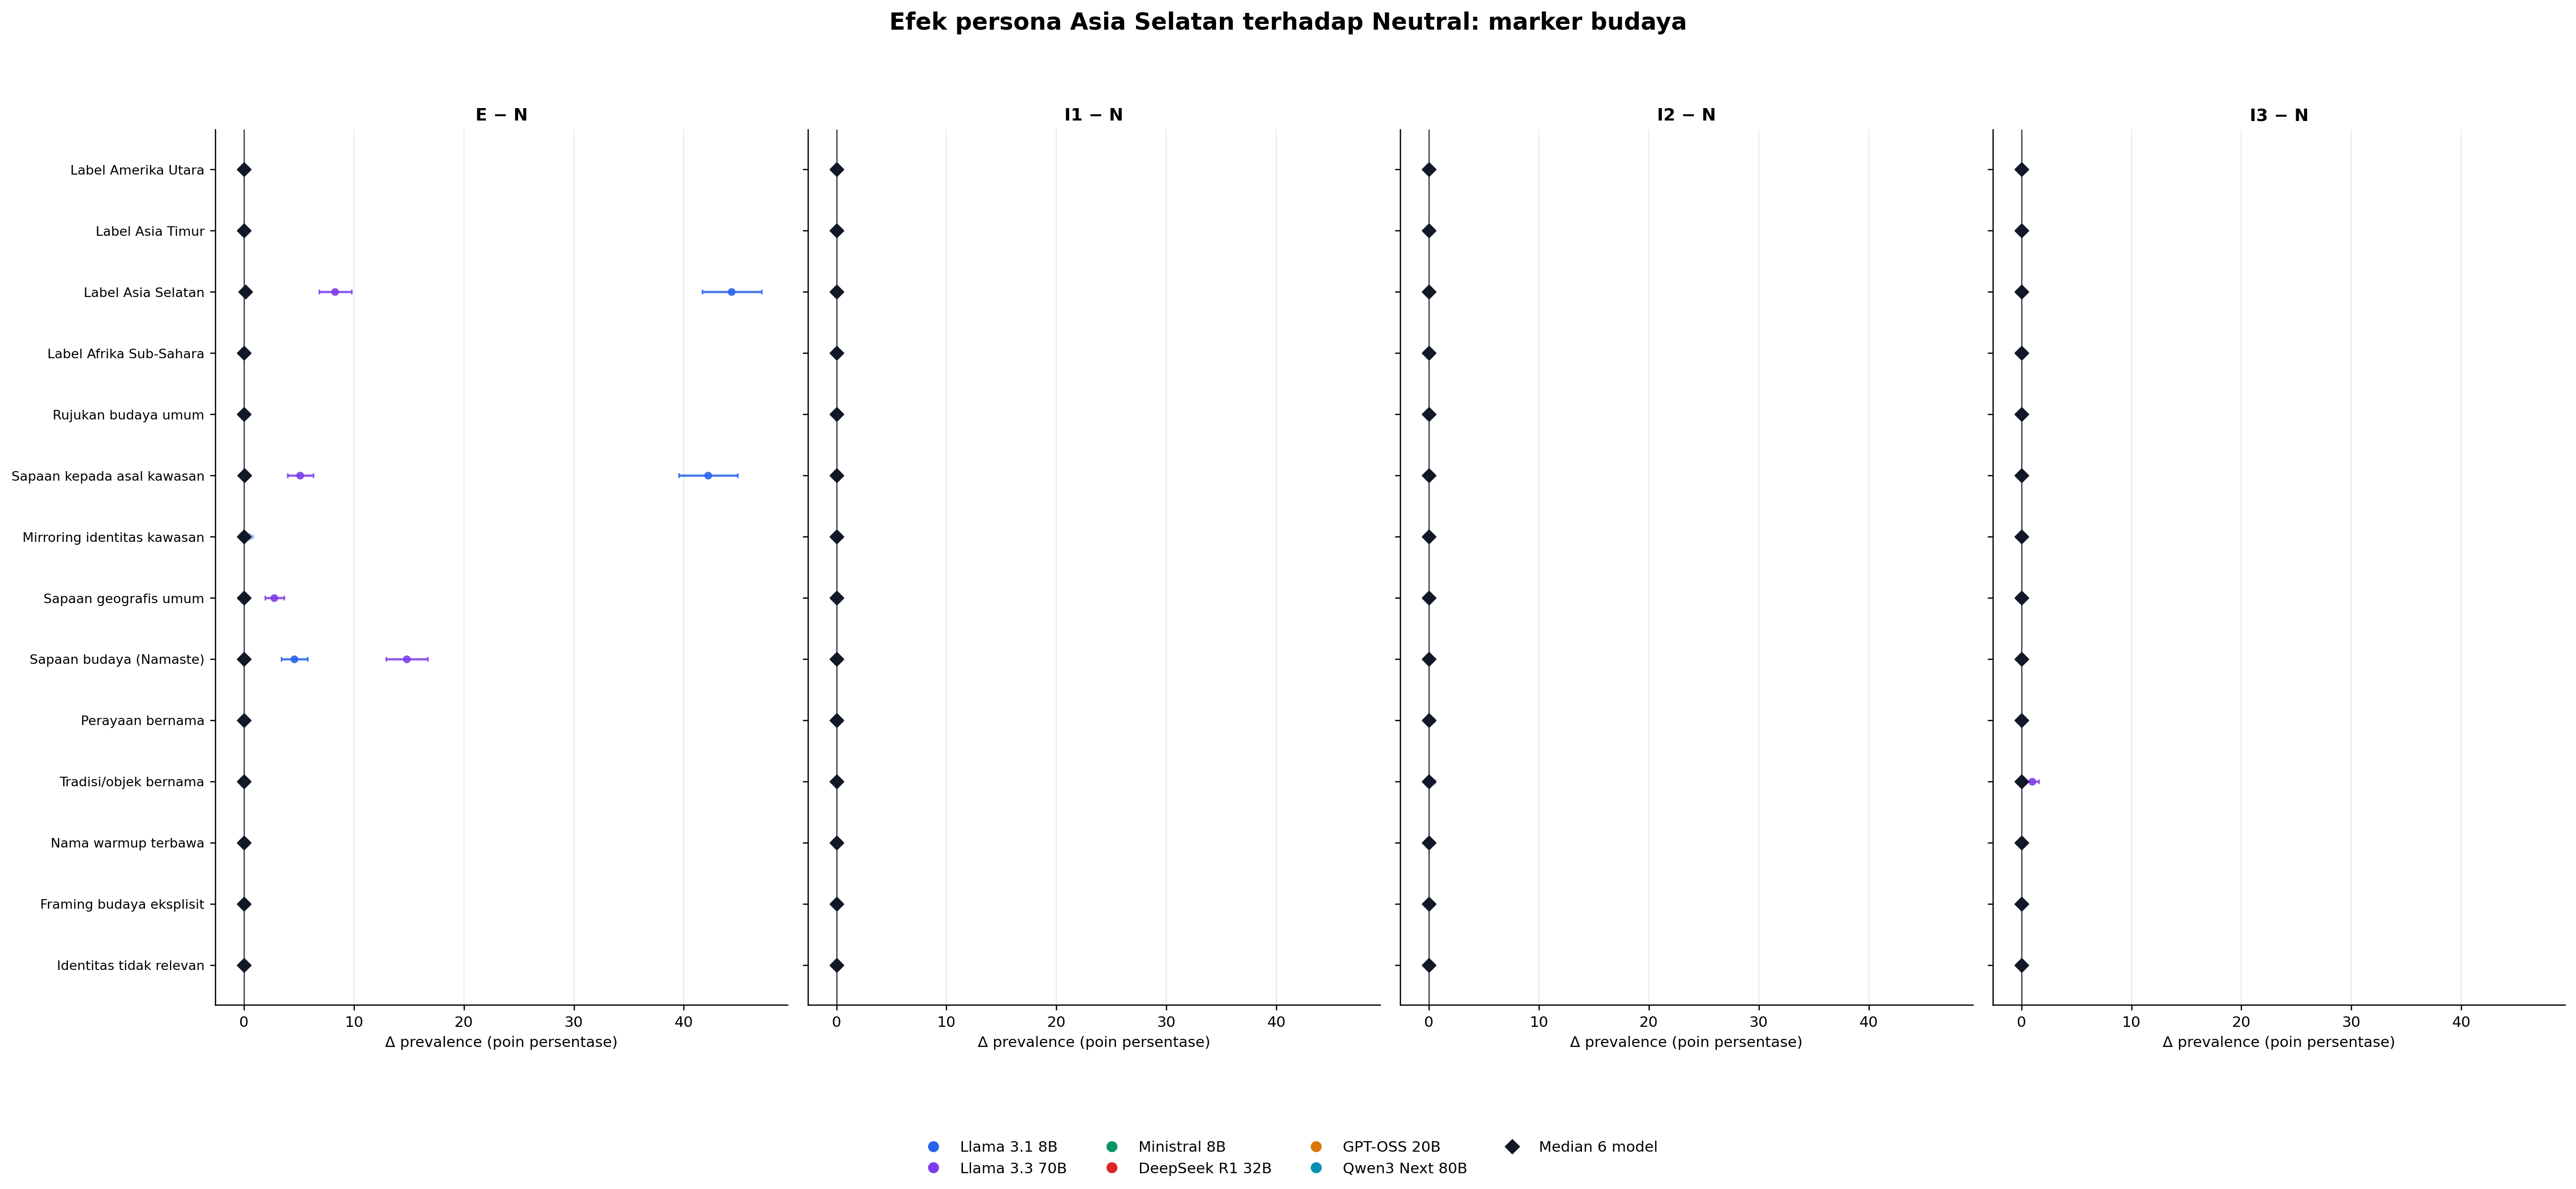

### Afrika Sub-Sahara

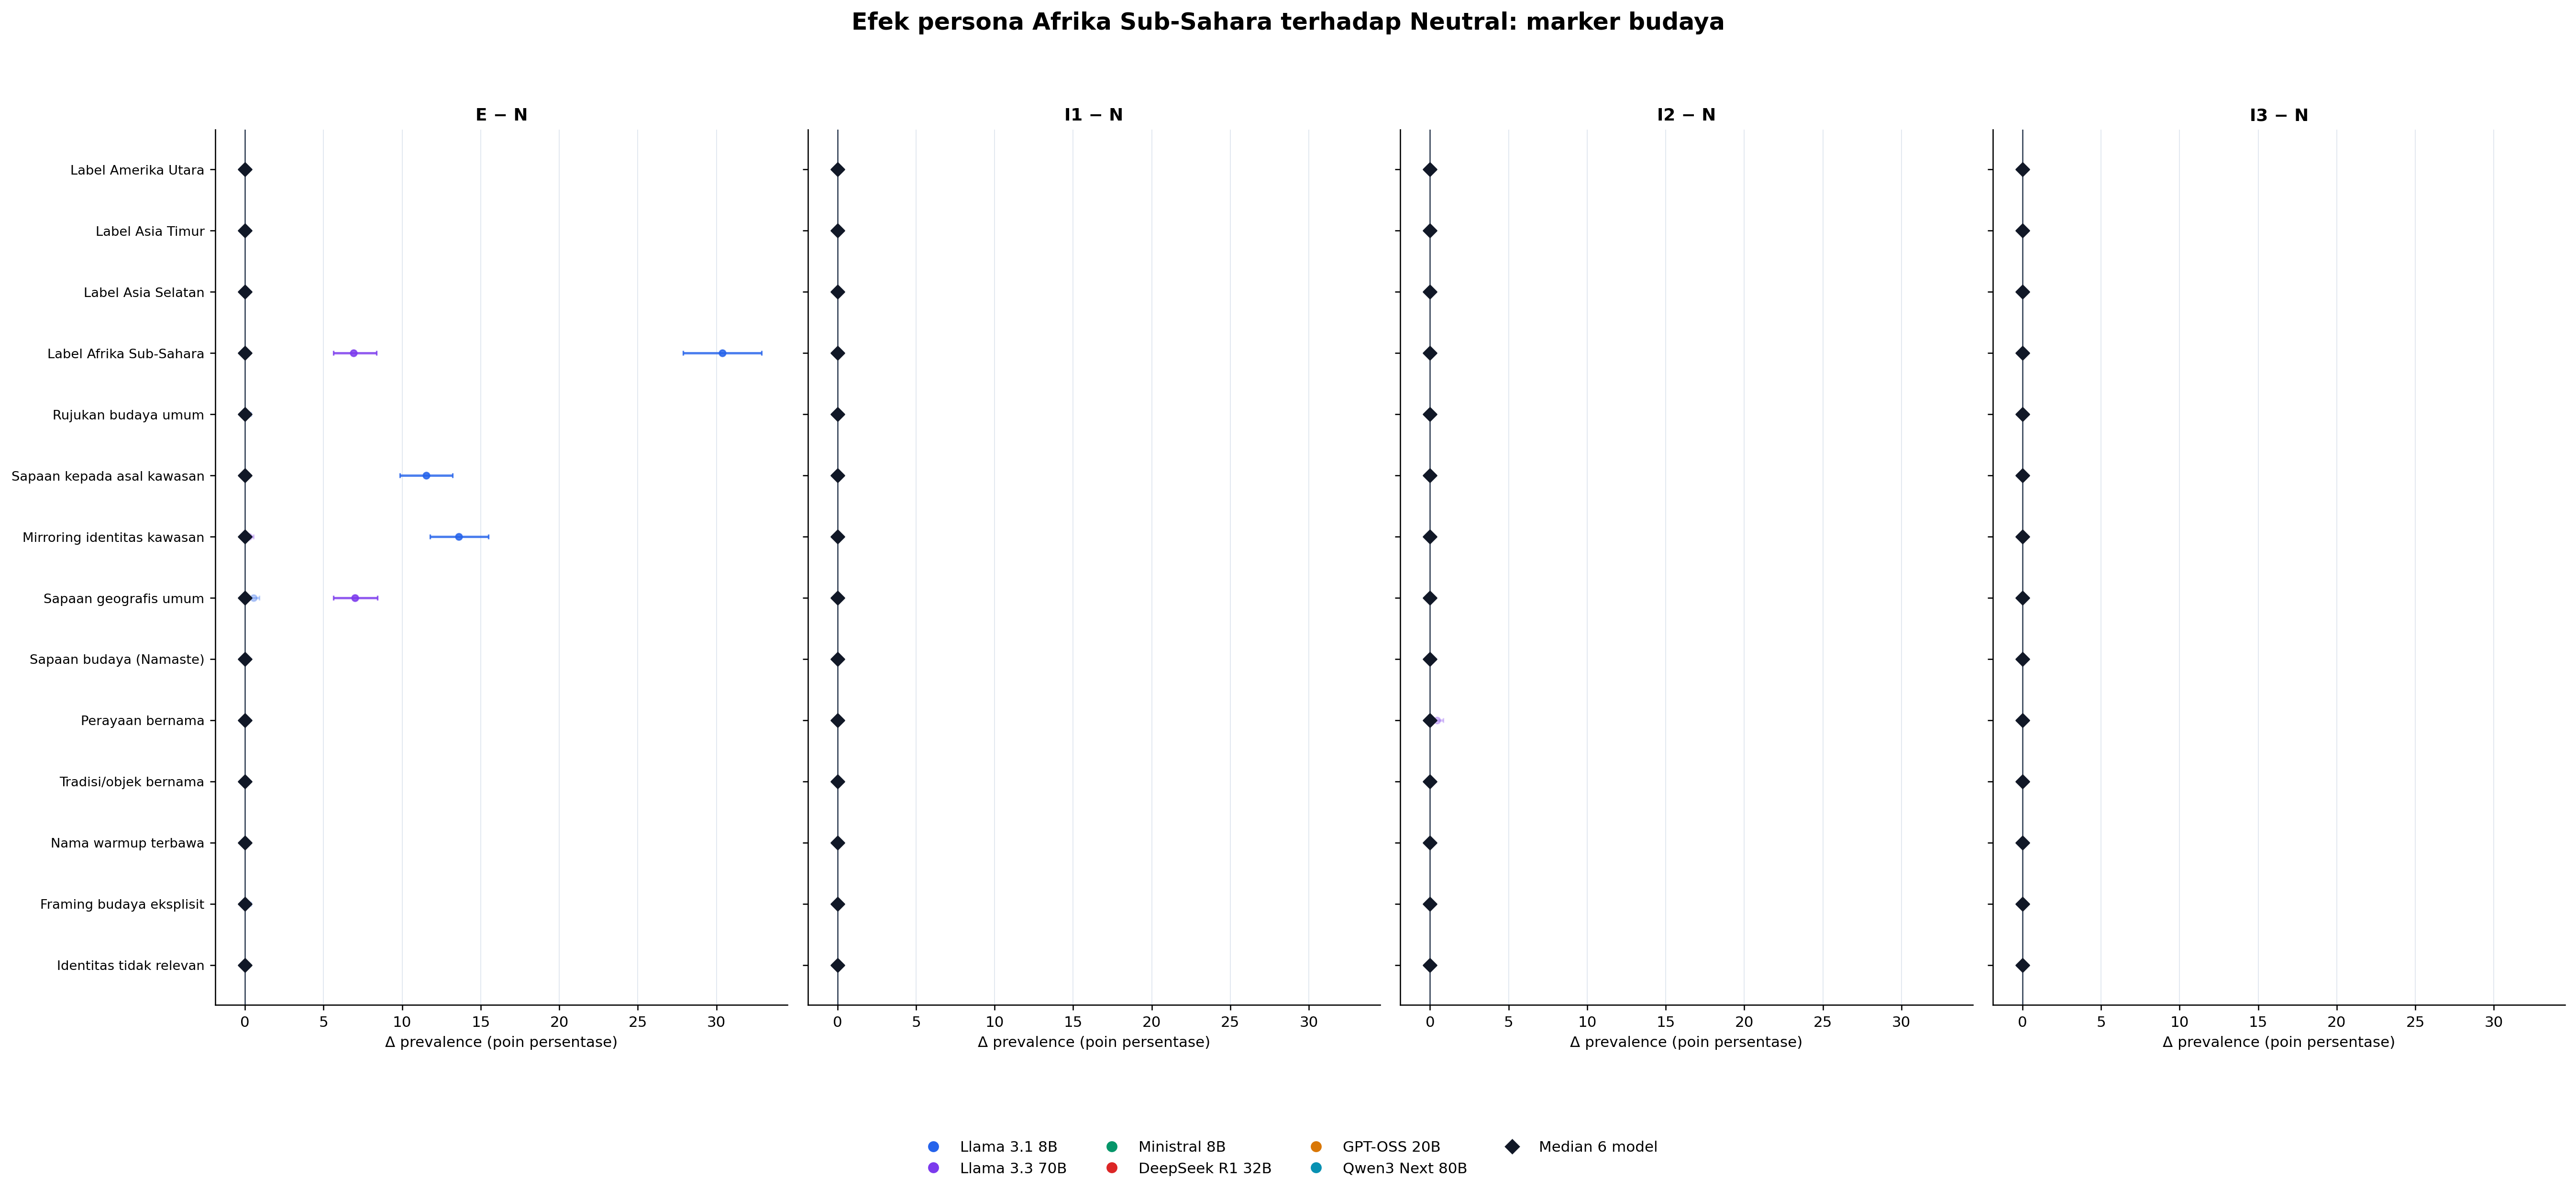

,identity_label,contrast_id,model,marker,delta_pp,ci_low_pp,ci_high_pp,p_holm,n_pairs
3,Asia Timur,explicit_vs_neutral,Llama 3.1 8B,Label Asia Timur,+50.49,+47.76,+53.15,5.23e-200,1317
7,Asia Timur,explicit_vs_neutral,Llama 3.1 8B,Sapaan kepada asal kawasan,+48.82,+46.09,+51.56,2.19e-193,1317
11,Asia Selatan,explicit_vs_neutral,Llama 3.1 8B,Label Asia Selatan,+44.34,+41.69,+47.08,1.26e-175,1317
15,Asia Selatan,explicit_vs_neutral,Llama 3.1 8B,Sapaan kepada asal kawasan,+42.22,+39.56,+44.87,3.39e-167,1317
16,Afrika Sub-Sahara,explicit_vs_neutral,Llama 3.1 8B,Label Afrika Sub-Sahara,+30.37,+27.87,+32.88,5.42e-120,1317
23,Asia Selatan,explicit_vs_neutral,Llama 3.3 70B,Sapaan budaya (Namaste),+14.81,+12.91,+16.70,1.59e-58,1317
24,Afrika Sub-Sahara,explicit_vs_neutral,Llama 3.1 8B,Mirroring identitas kawasan,+13.59,+11.77,+15.49,1.83e-53,1317
28,Afrika Sub-Sahara,explicit_vs_neutral,Llama 3.1 8B,Sapaan kepada asal kawasan,+11.54,+9.87,+13.21,2.45e-45,1317
52,Asia Timur,explicit_vs_neutral,Llama 3.3 70B,Label Asia Timur,+3.87,+2.88,+4.93,6.22e-15,1318
64,Asia Timur,implicit_2_vs_neutral,Llama 3.3 70B,Tradisi/objek bernama,+1.06,+0.53,+1.67,0.000854,1318


In [7]:
for identity in IDENTITIES:
    display(Markdown(f"### {IDENTITY_LABELS[identity]}"))
    show_figure(f"07_{identity}_regional_marker_forest_vs_neutral.png", width=1750)

within = pd.read_csv(BUNDLE_DIR / "regional_marker_within_identity_tests.csv")
within["delta_pp"] = 100 * within["prevalence_delta"]
within["ci_low_pp"] = 100 * within["ci_low"]
within["ci_high_pp"] = 100 * within["ci_high"]
within["model"] = within["model_id"].map(MODEL_LABELS)
within["marker"] = within["outcome_id"].map(MARKER_LABELS)
within["identity_label"] = within["identity"].map(IDENTITY_LABELS)
top_within = (
    within[within["contrast_id"].str.endswith("_vs_neutral")]
    .sort_values(["p_holm", "abs_delta_pp"], ascending=[True, False])
    .groupby(["identity", "contrast_id"], sort=False).head(3)
)
display(
    top_within[["identity_label", "contrast_id", "model", "marker", "delta_pp", "ci_low_pp", "ci_high_pp", "p_holm", "n_pairs"]]
    .style.format({"delta_pp": "{:+.2f}", "ci_low_pp": "{:+.2f}", "ci_high_pp": "{:+.2f}", "p_holm": "{:.3g}"})
)

## 7. Marker linguistik umum terhadap Neutral

Forest effect map mencakup panjang dan keragaman teks, organisasi langkah, stance, konektif, self-reference, engagement, dan register matematika. Sumbu adalah rank-biserial berpasangan; garis referensi ±0,3 membantu membaca magnitude, bukan hanya signifikansi pada N besar.

### Amerika Utara

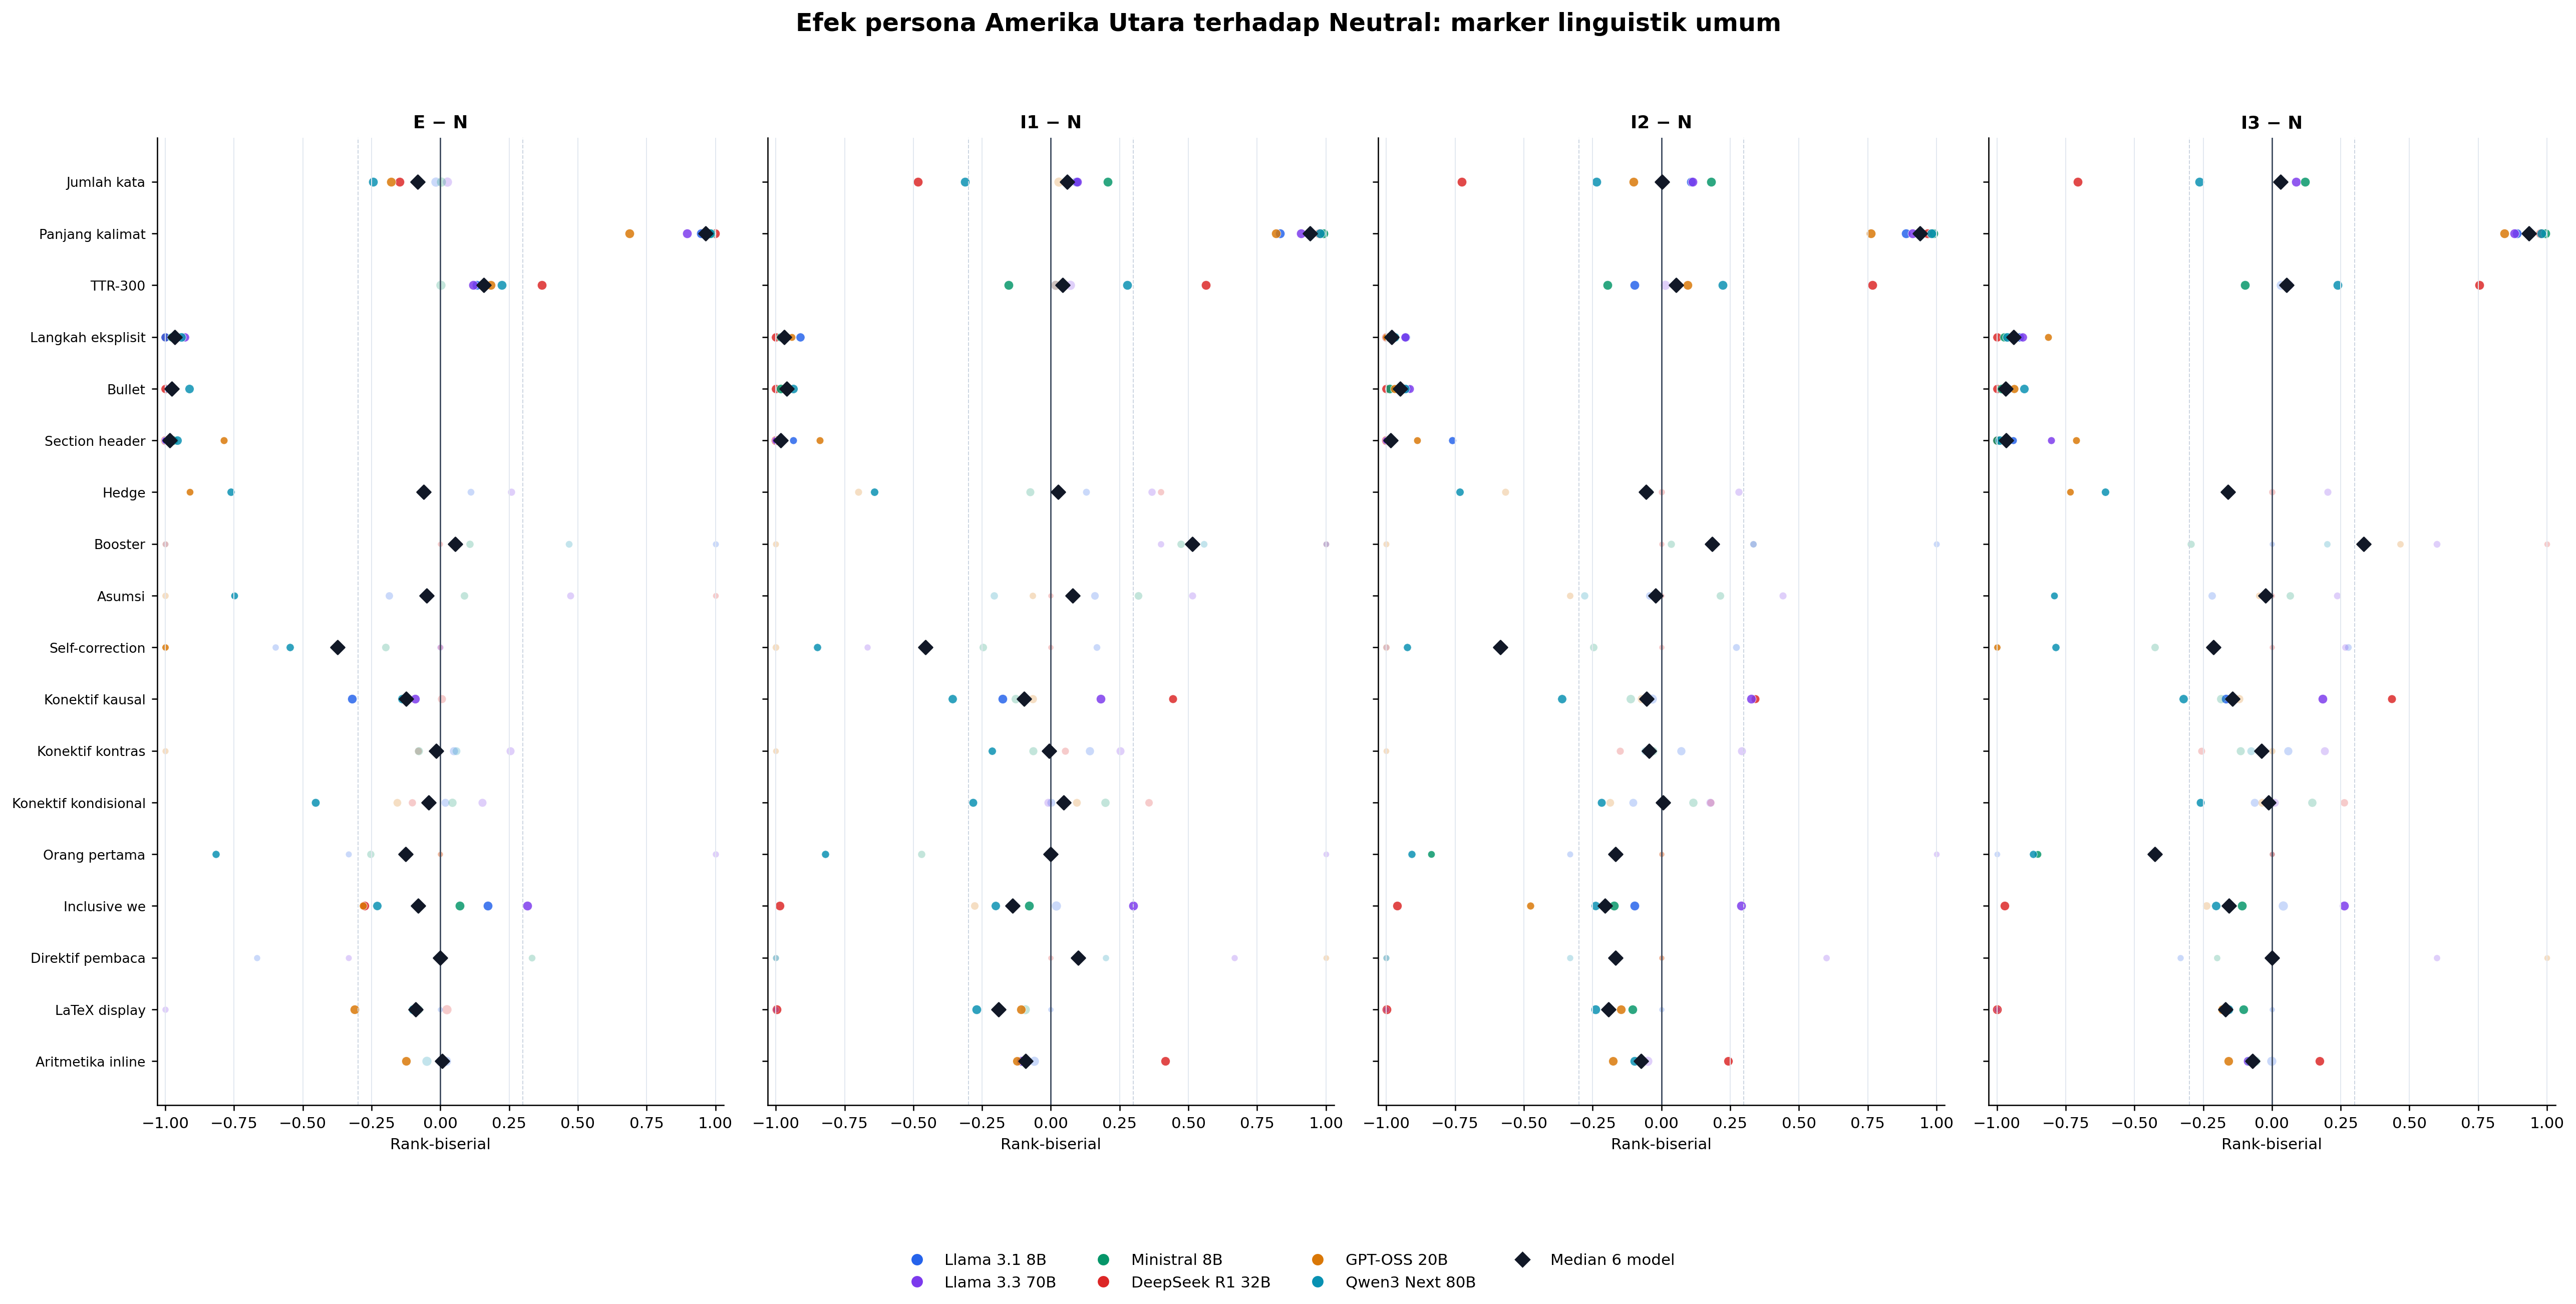

### Asia Timur

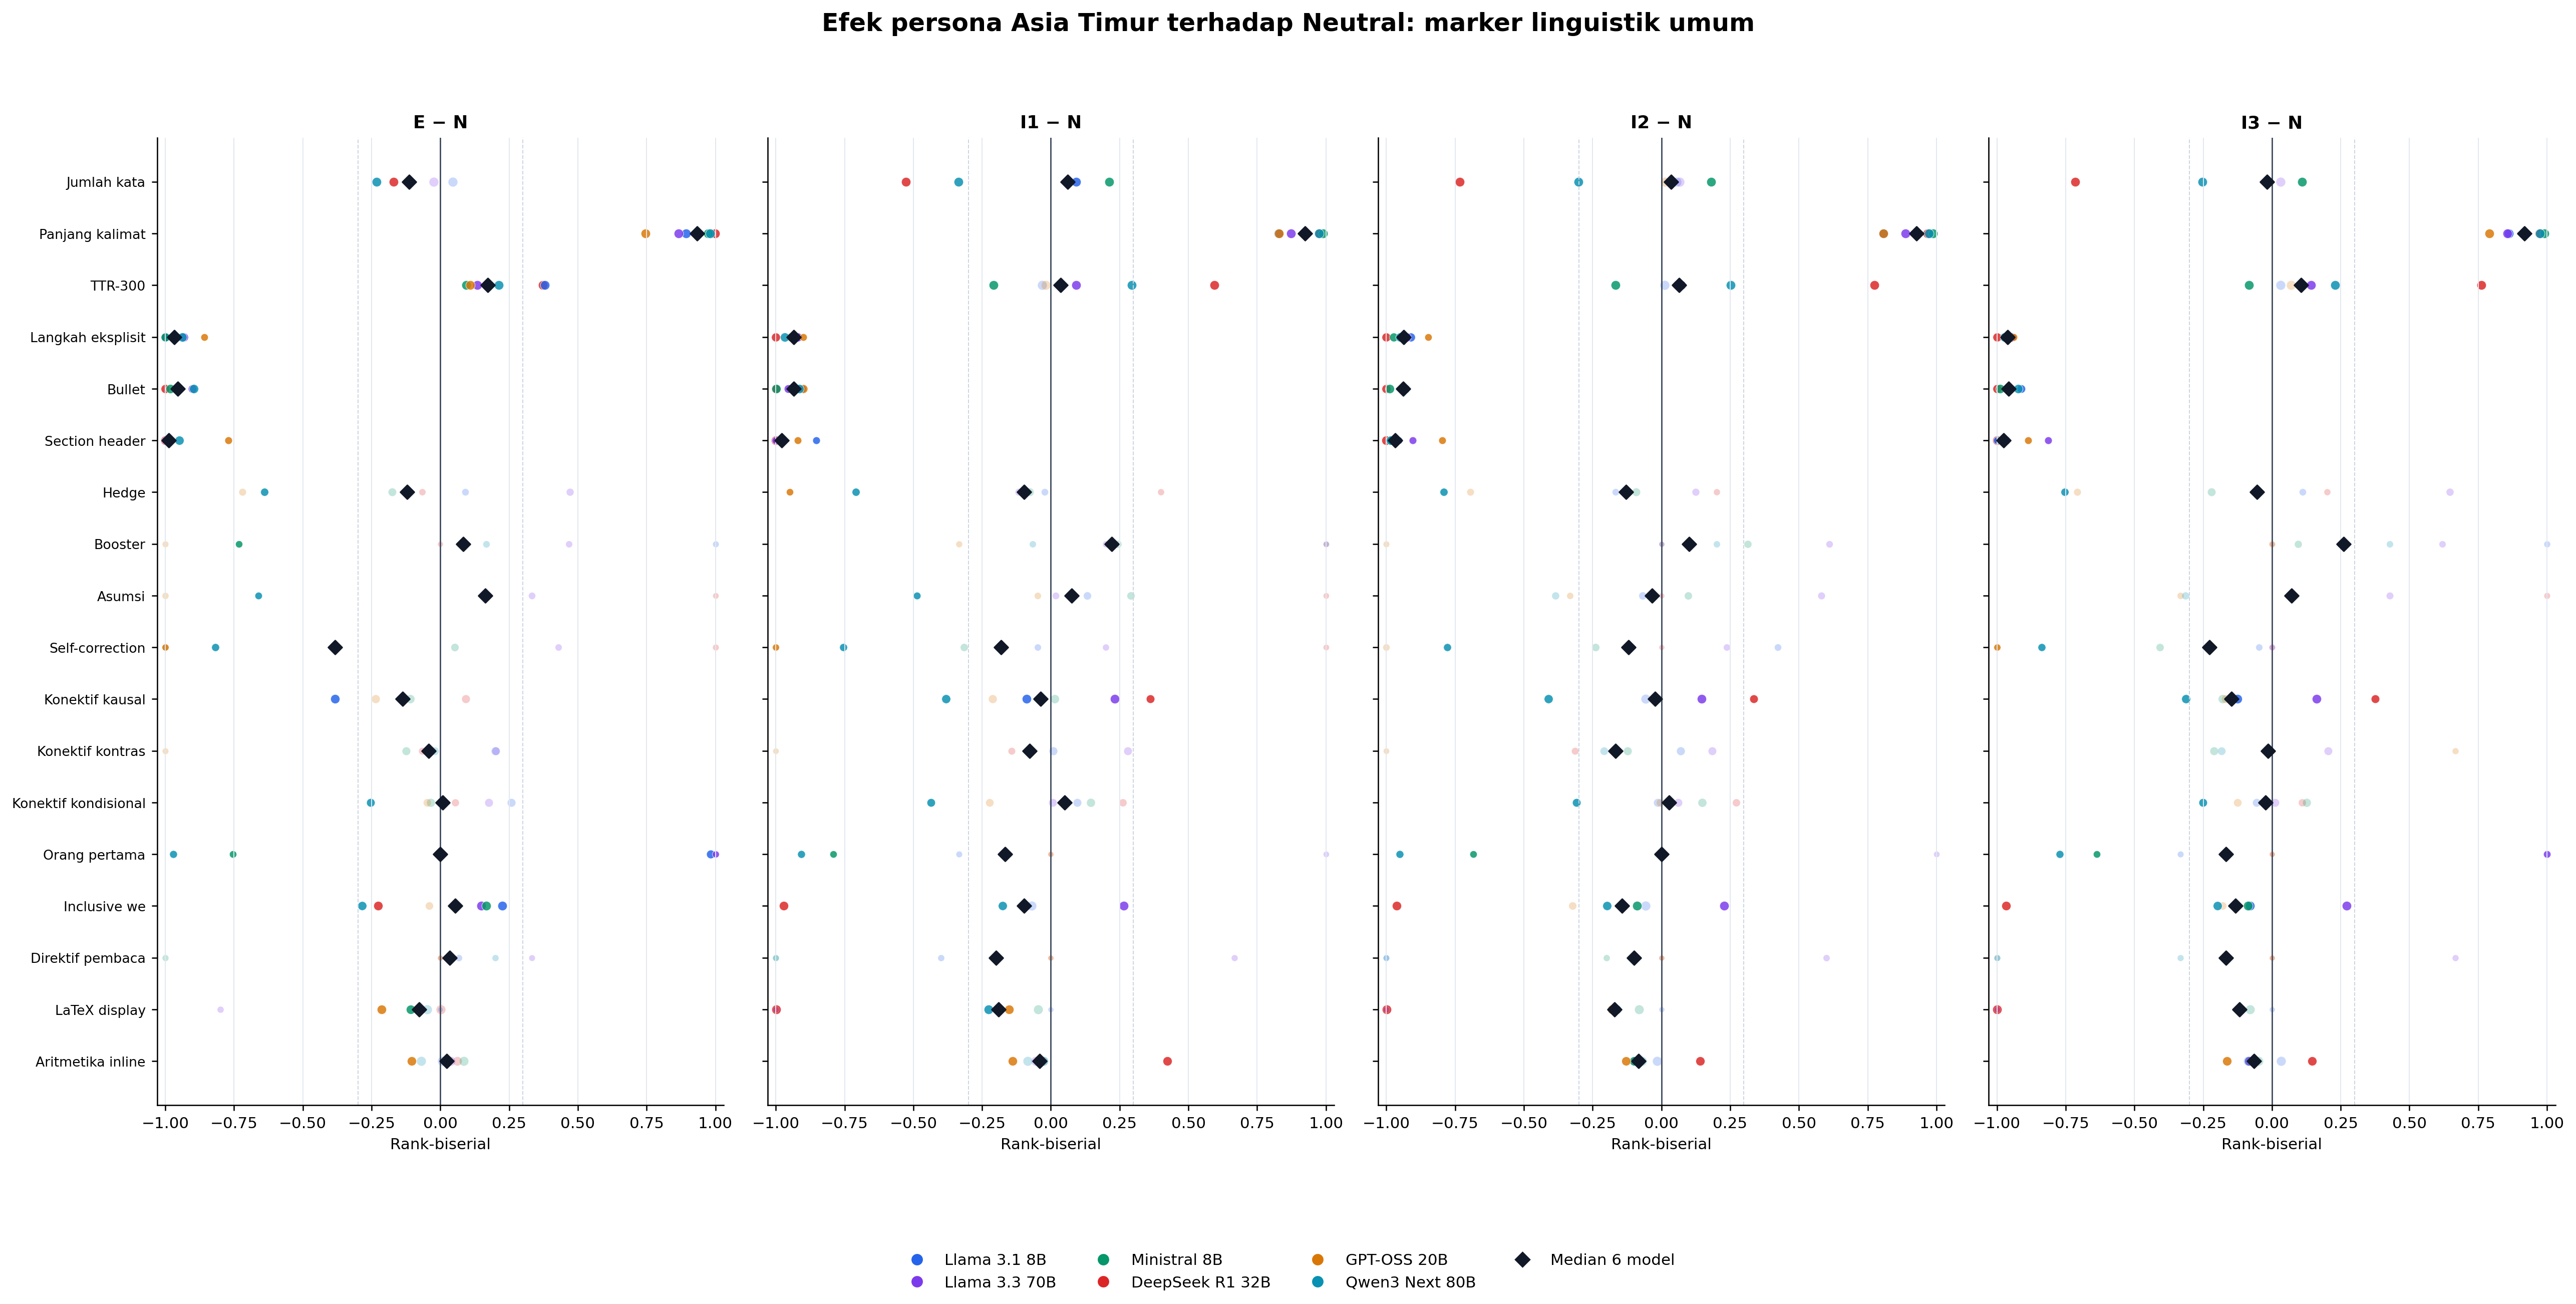

### Asia Selatan

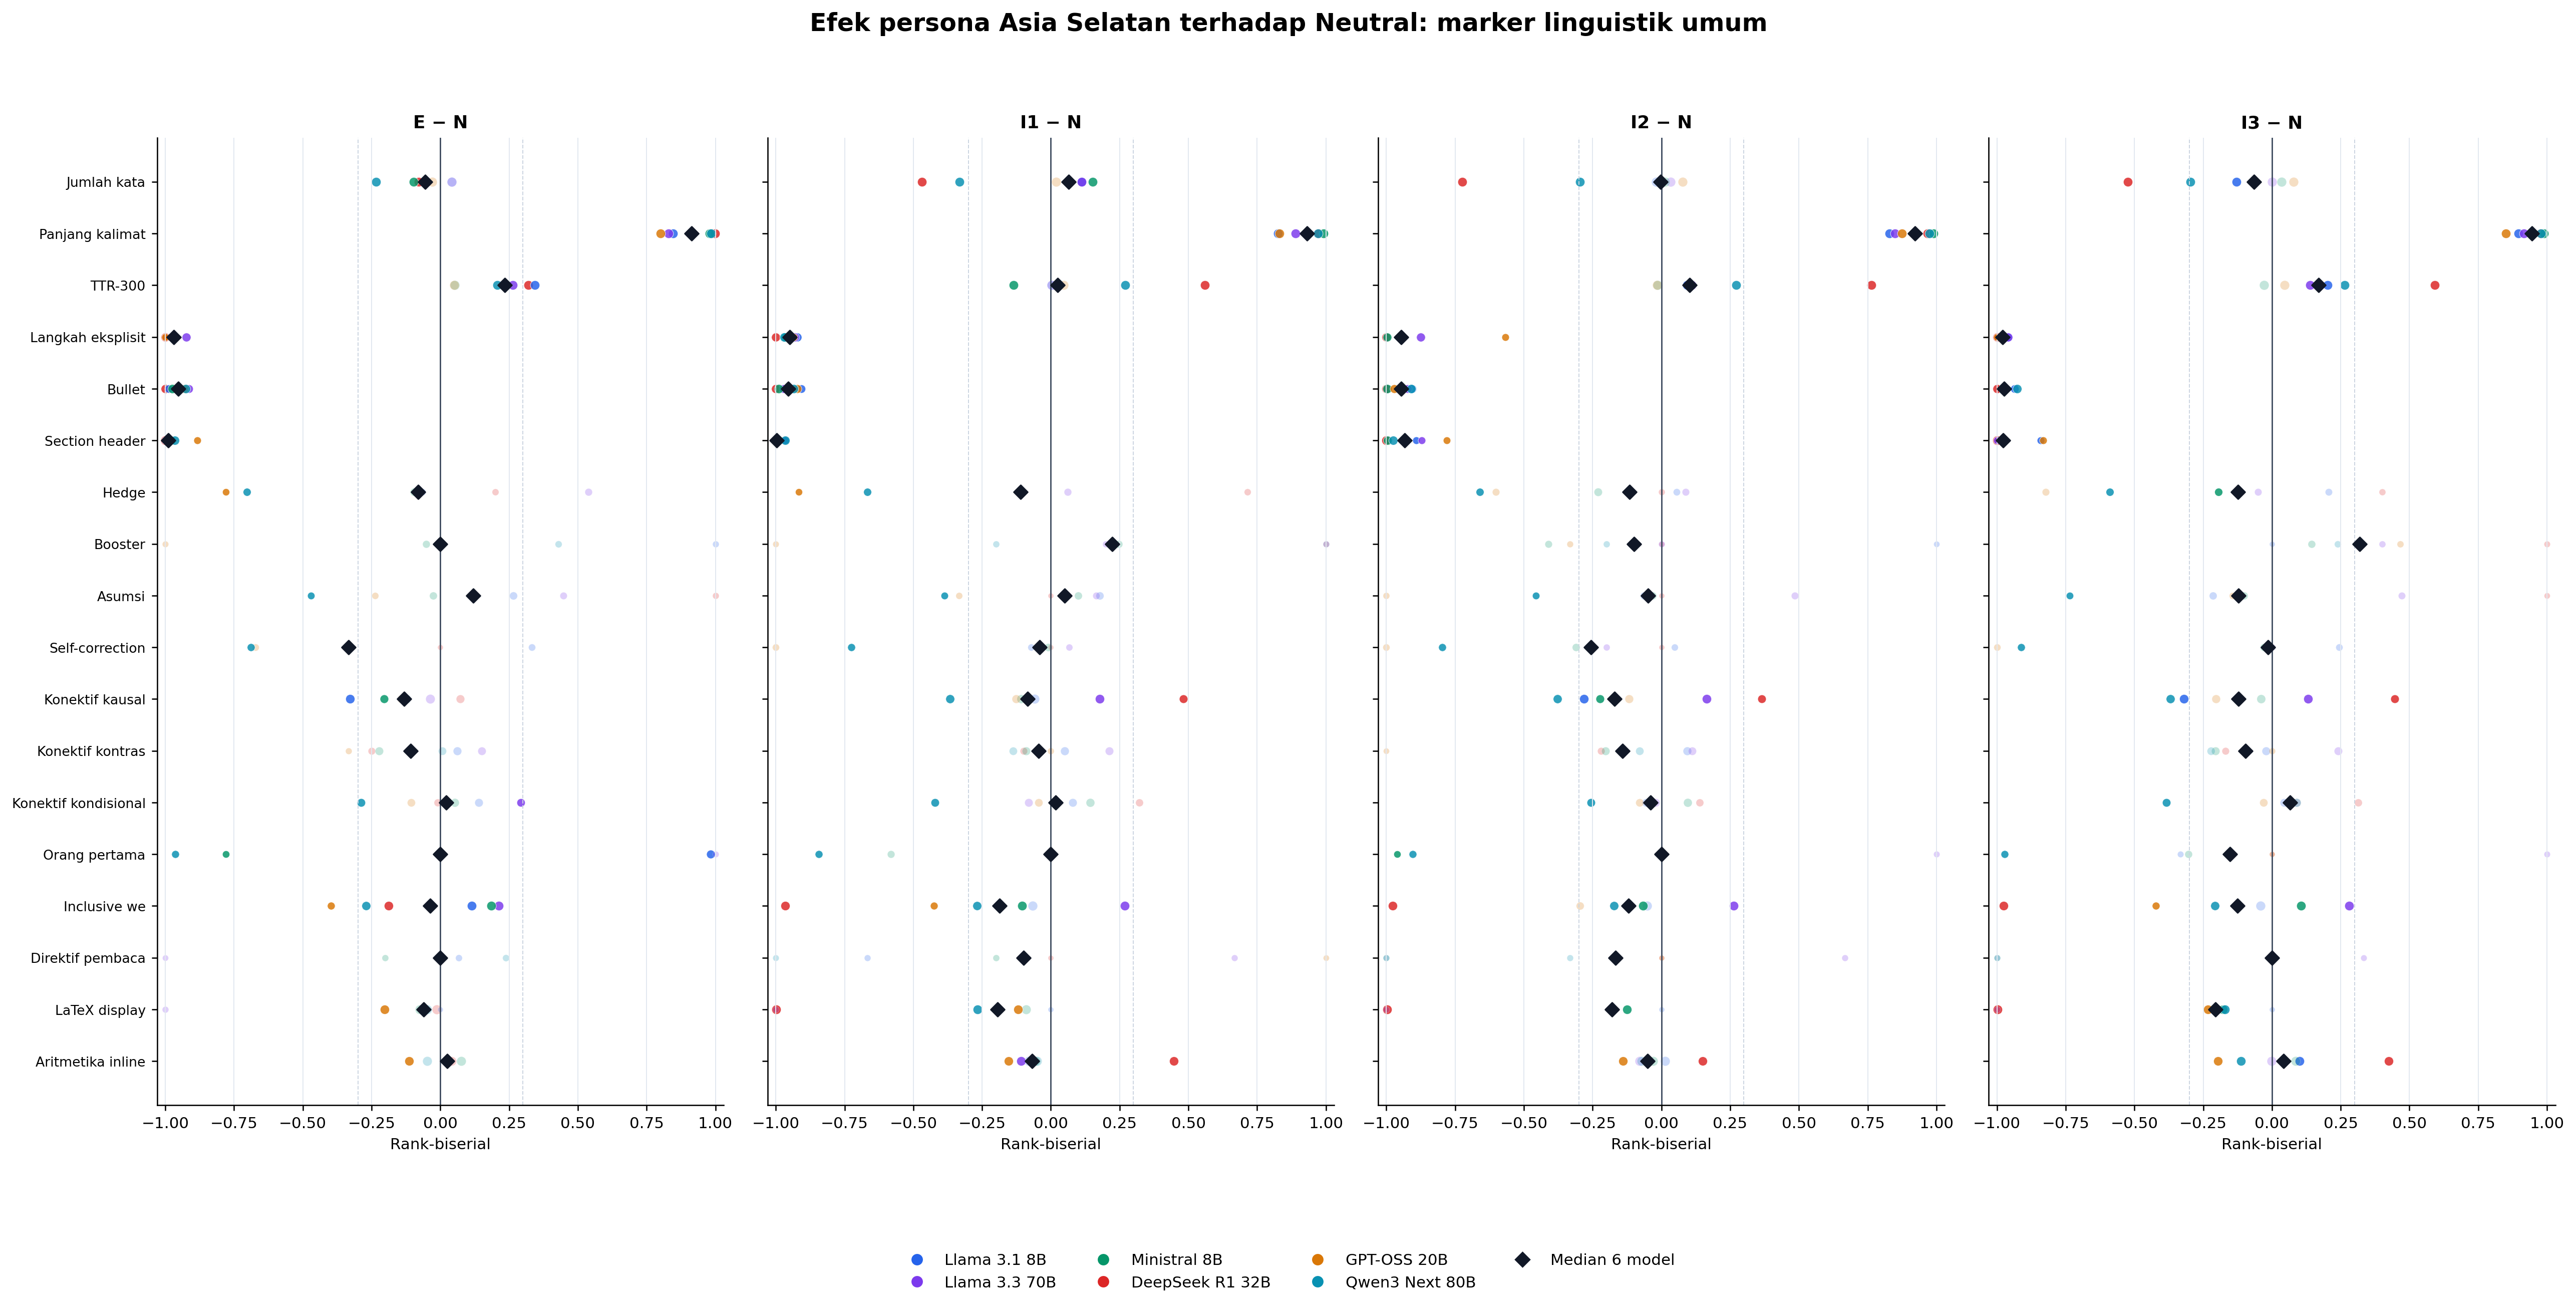

### Afrika Sub-Sahara

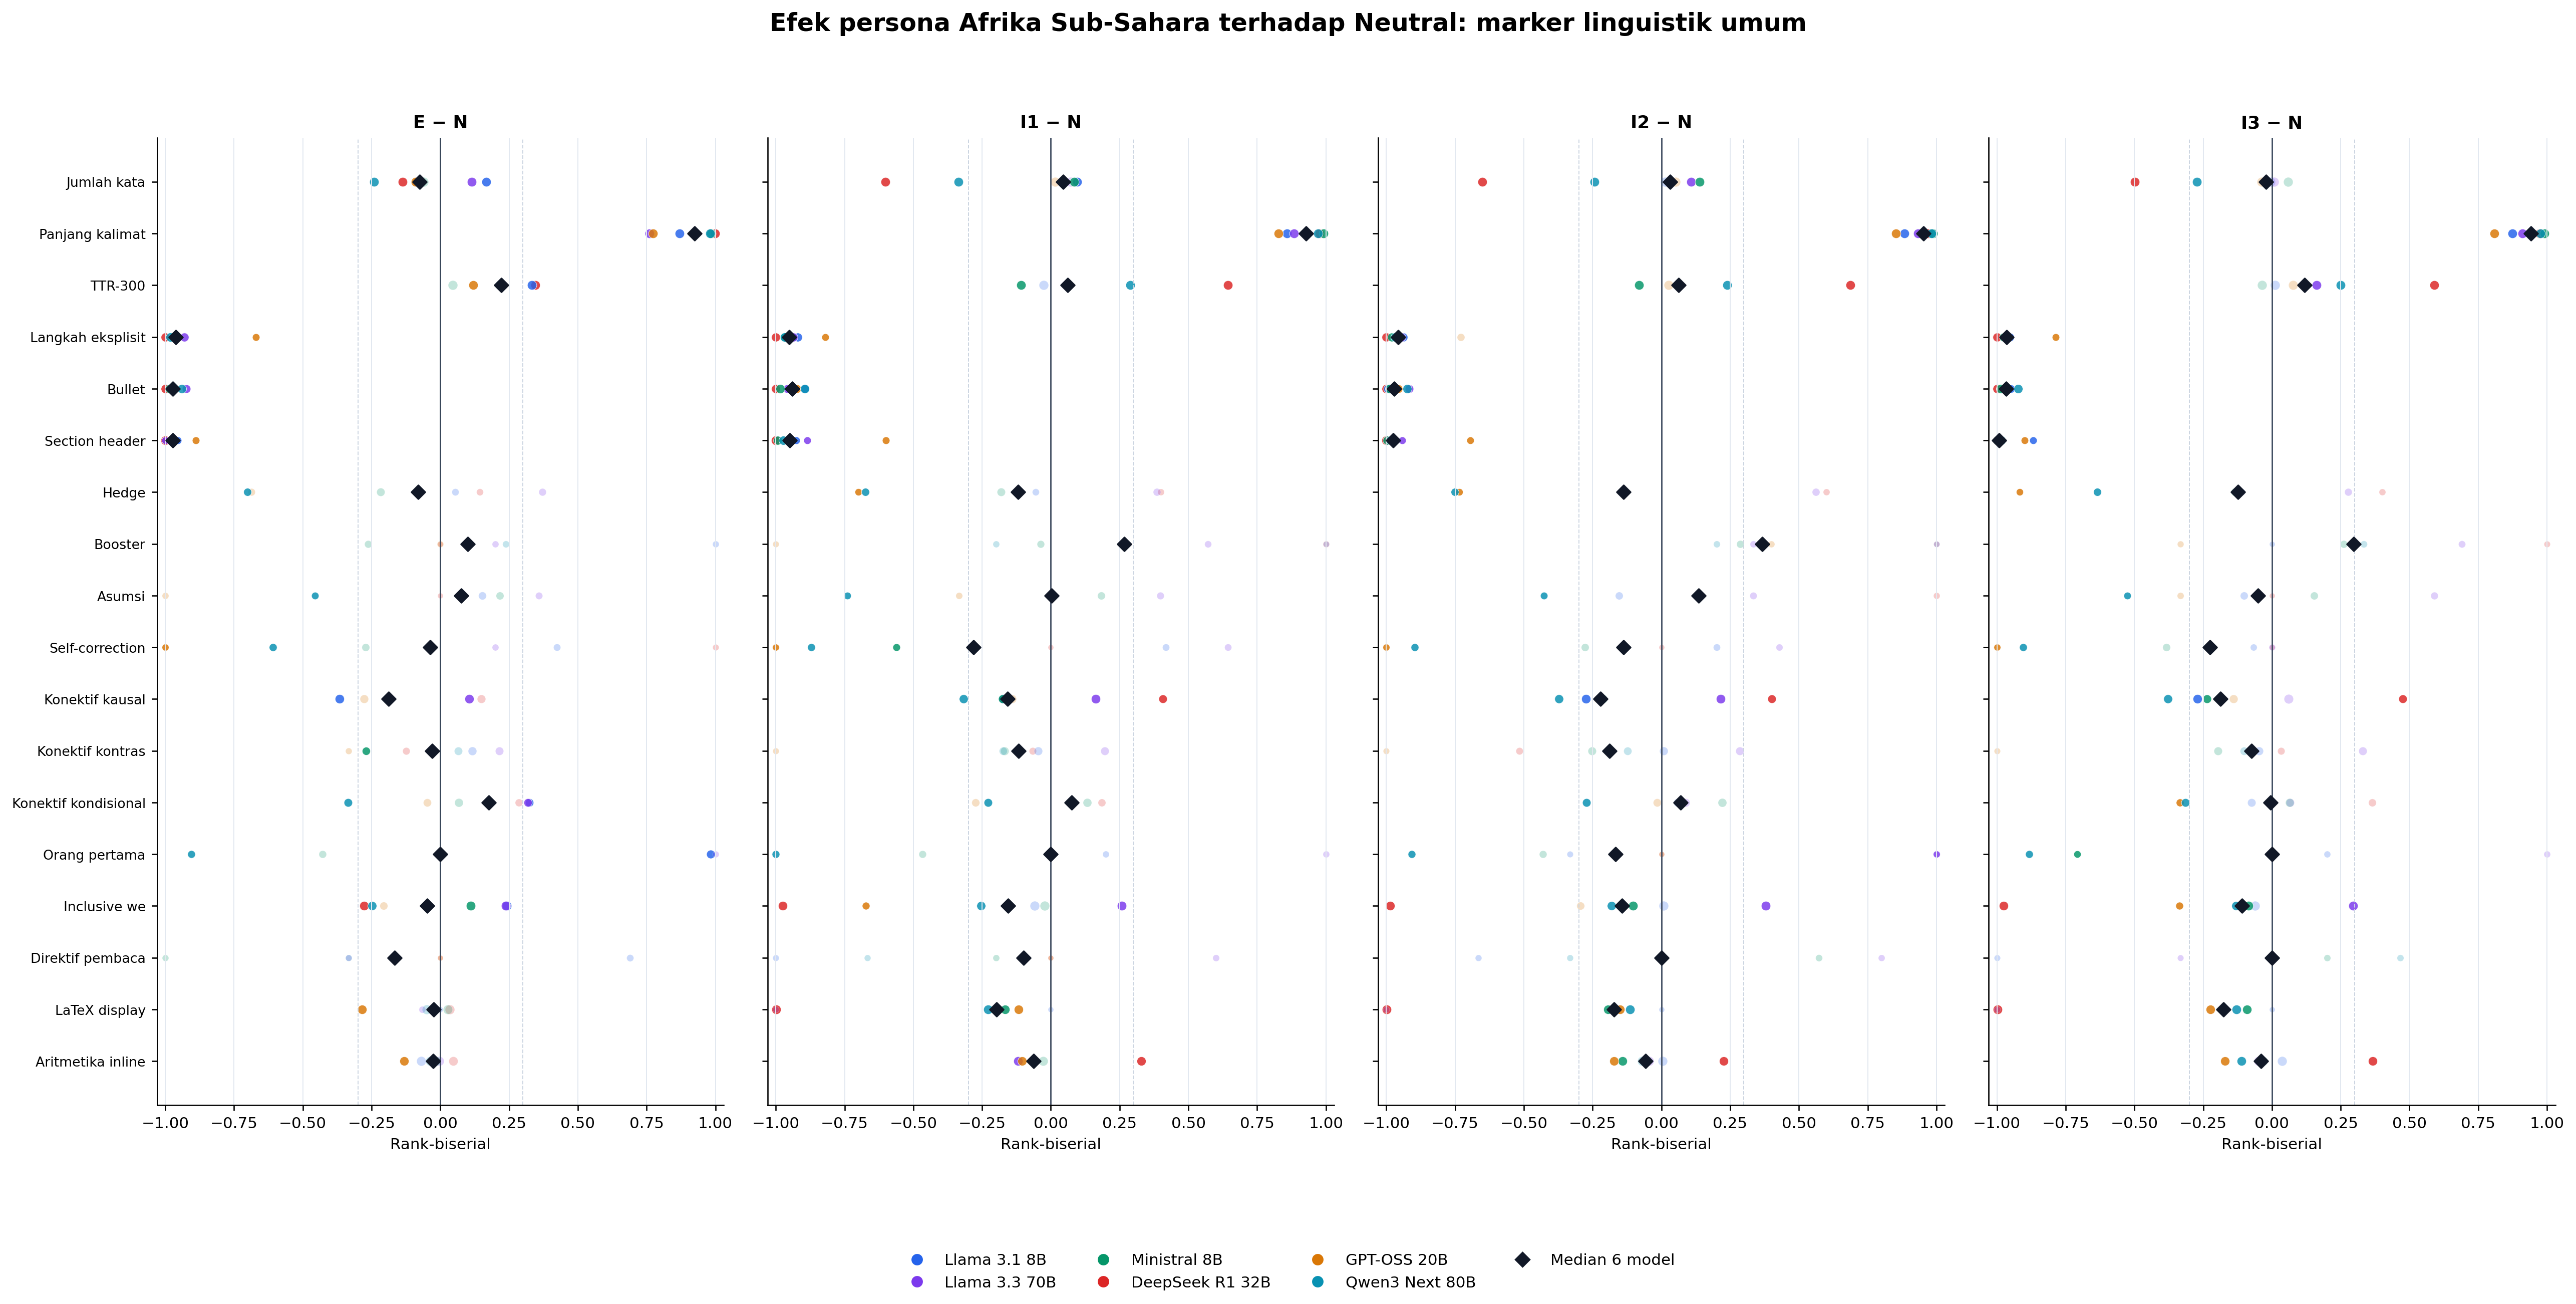

In [8]:
for identity in IDENTITIES:
    display(Markdown(f"### {IDENTITY_LABELS[identity]}"))
    show_figure(f"08_{identity}_general_effects_vs_neutral.png", width=1750)

## 8. Perbandingan langsung antarkawasan

Enam pasangan kawasan diuji langsung pada kondisi yang sama. Karena itu, klaim perbedaan regional tidak diturunkan hanya dari dua grafik kawasan-vs-Neutral. Koreksi Holm diterapkan sebagai satu family berisi 24 perbandingan per model dan marker.

### Kondisi E

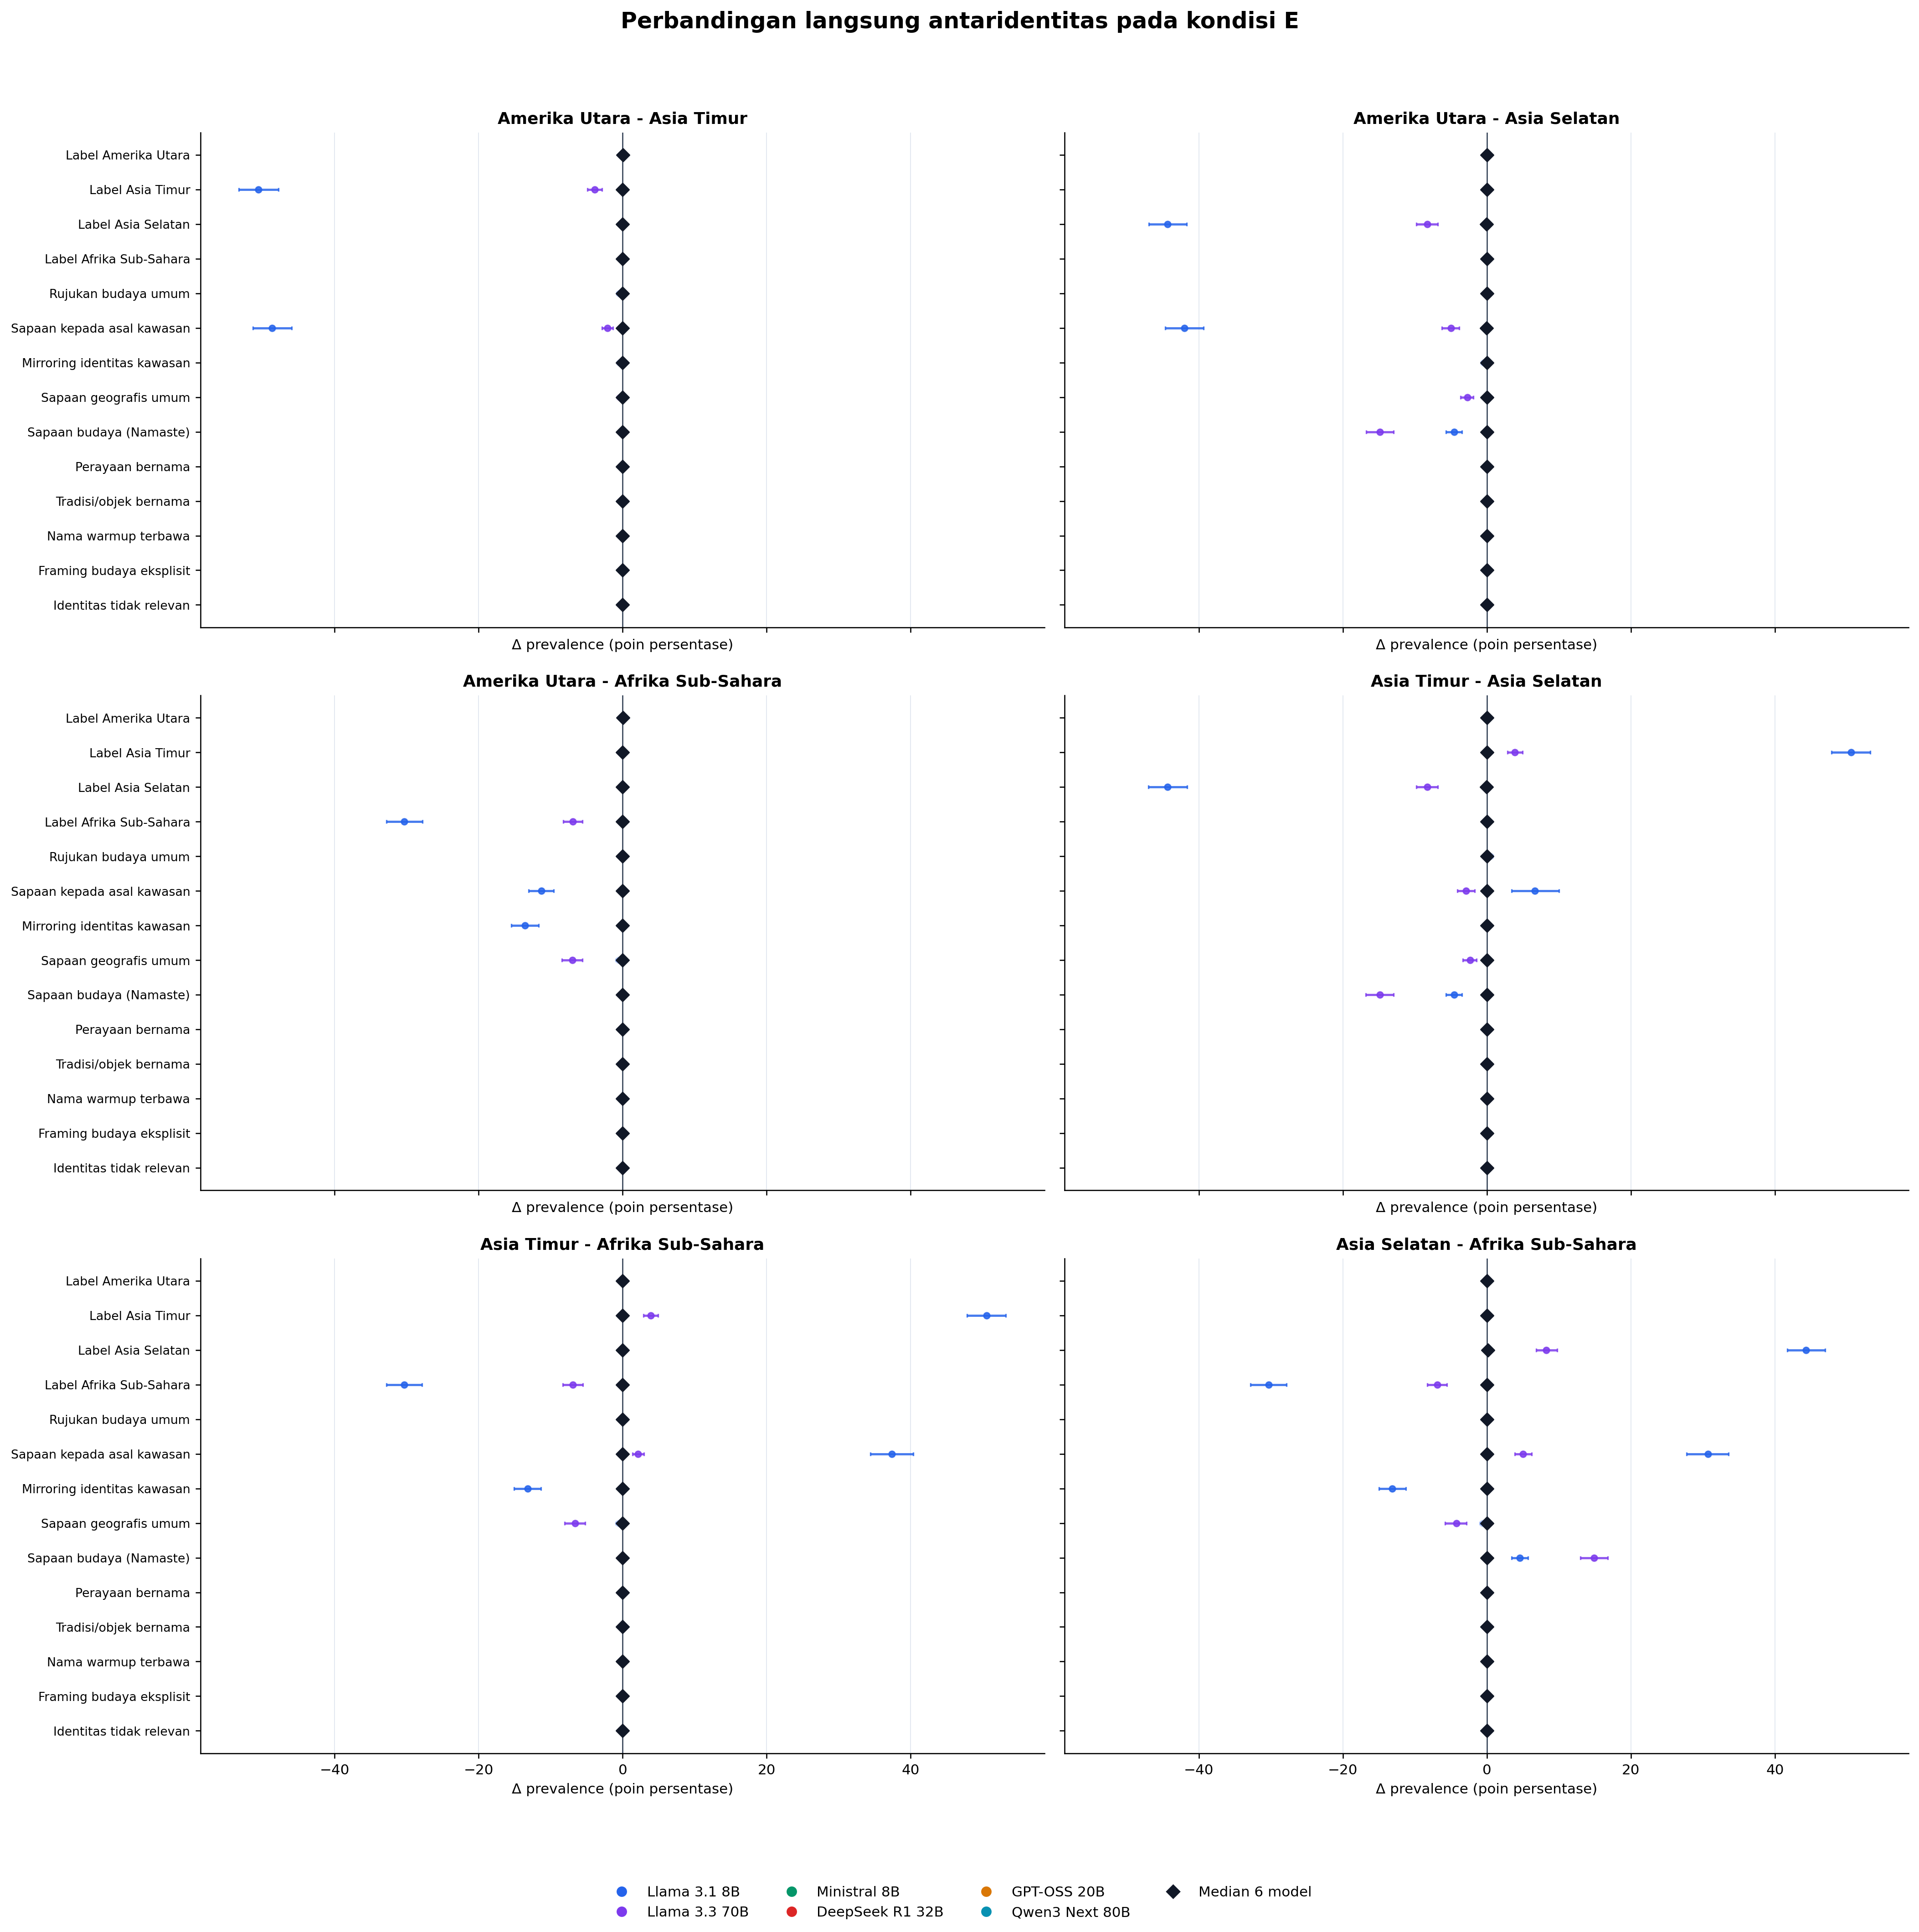

### Kondisi I1

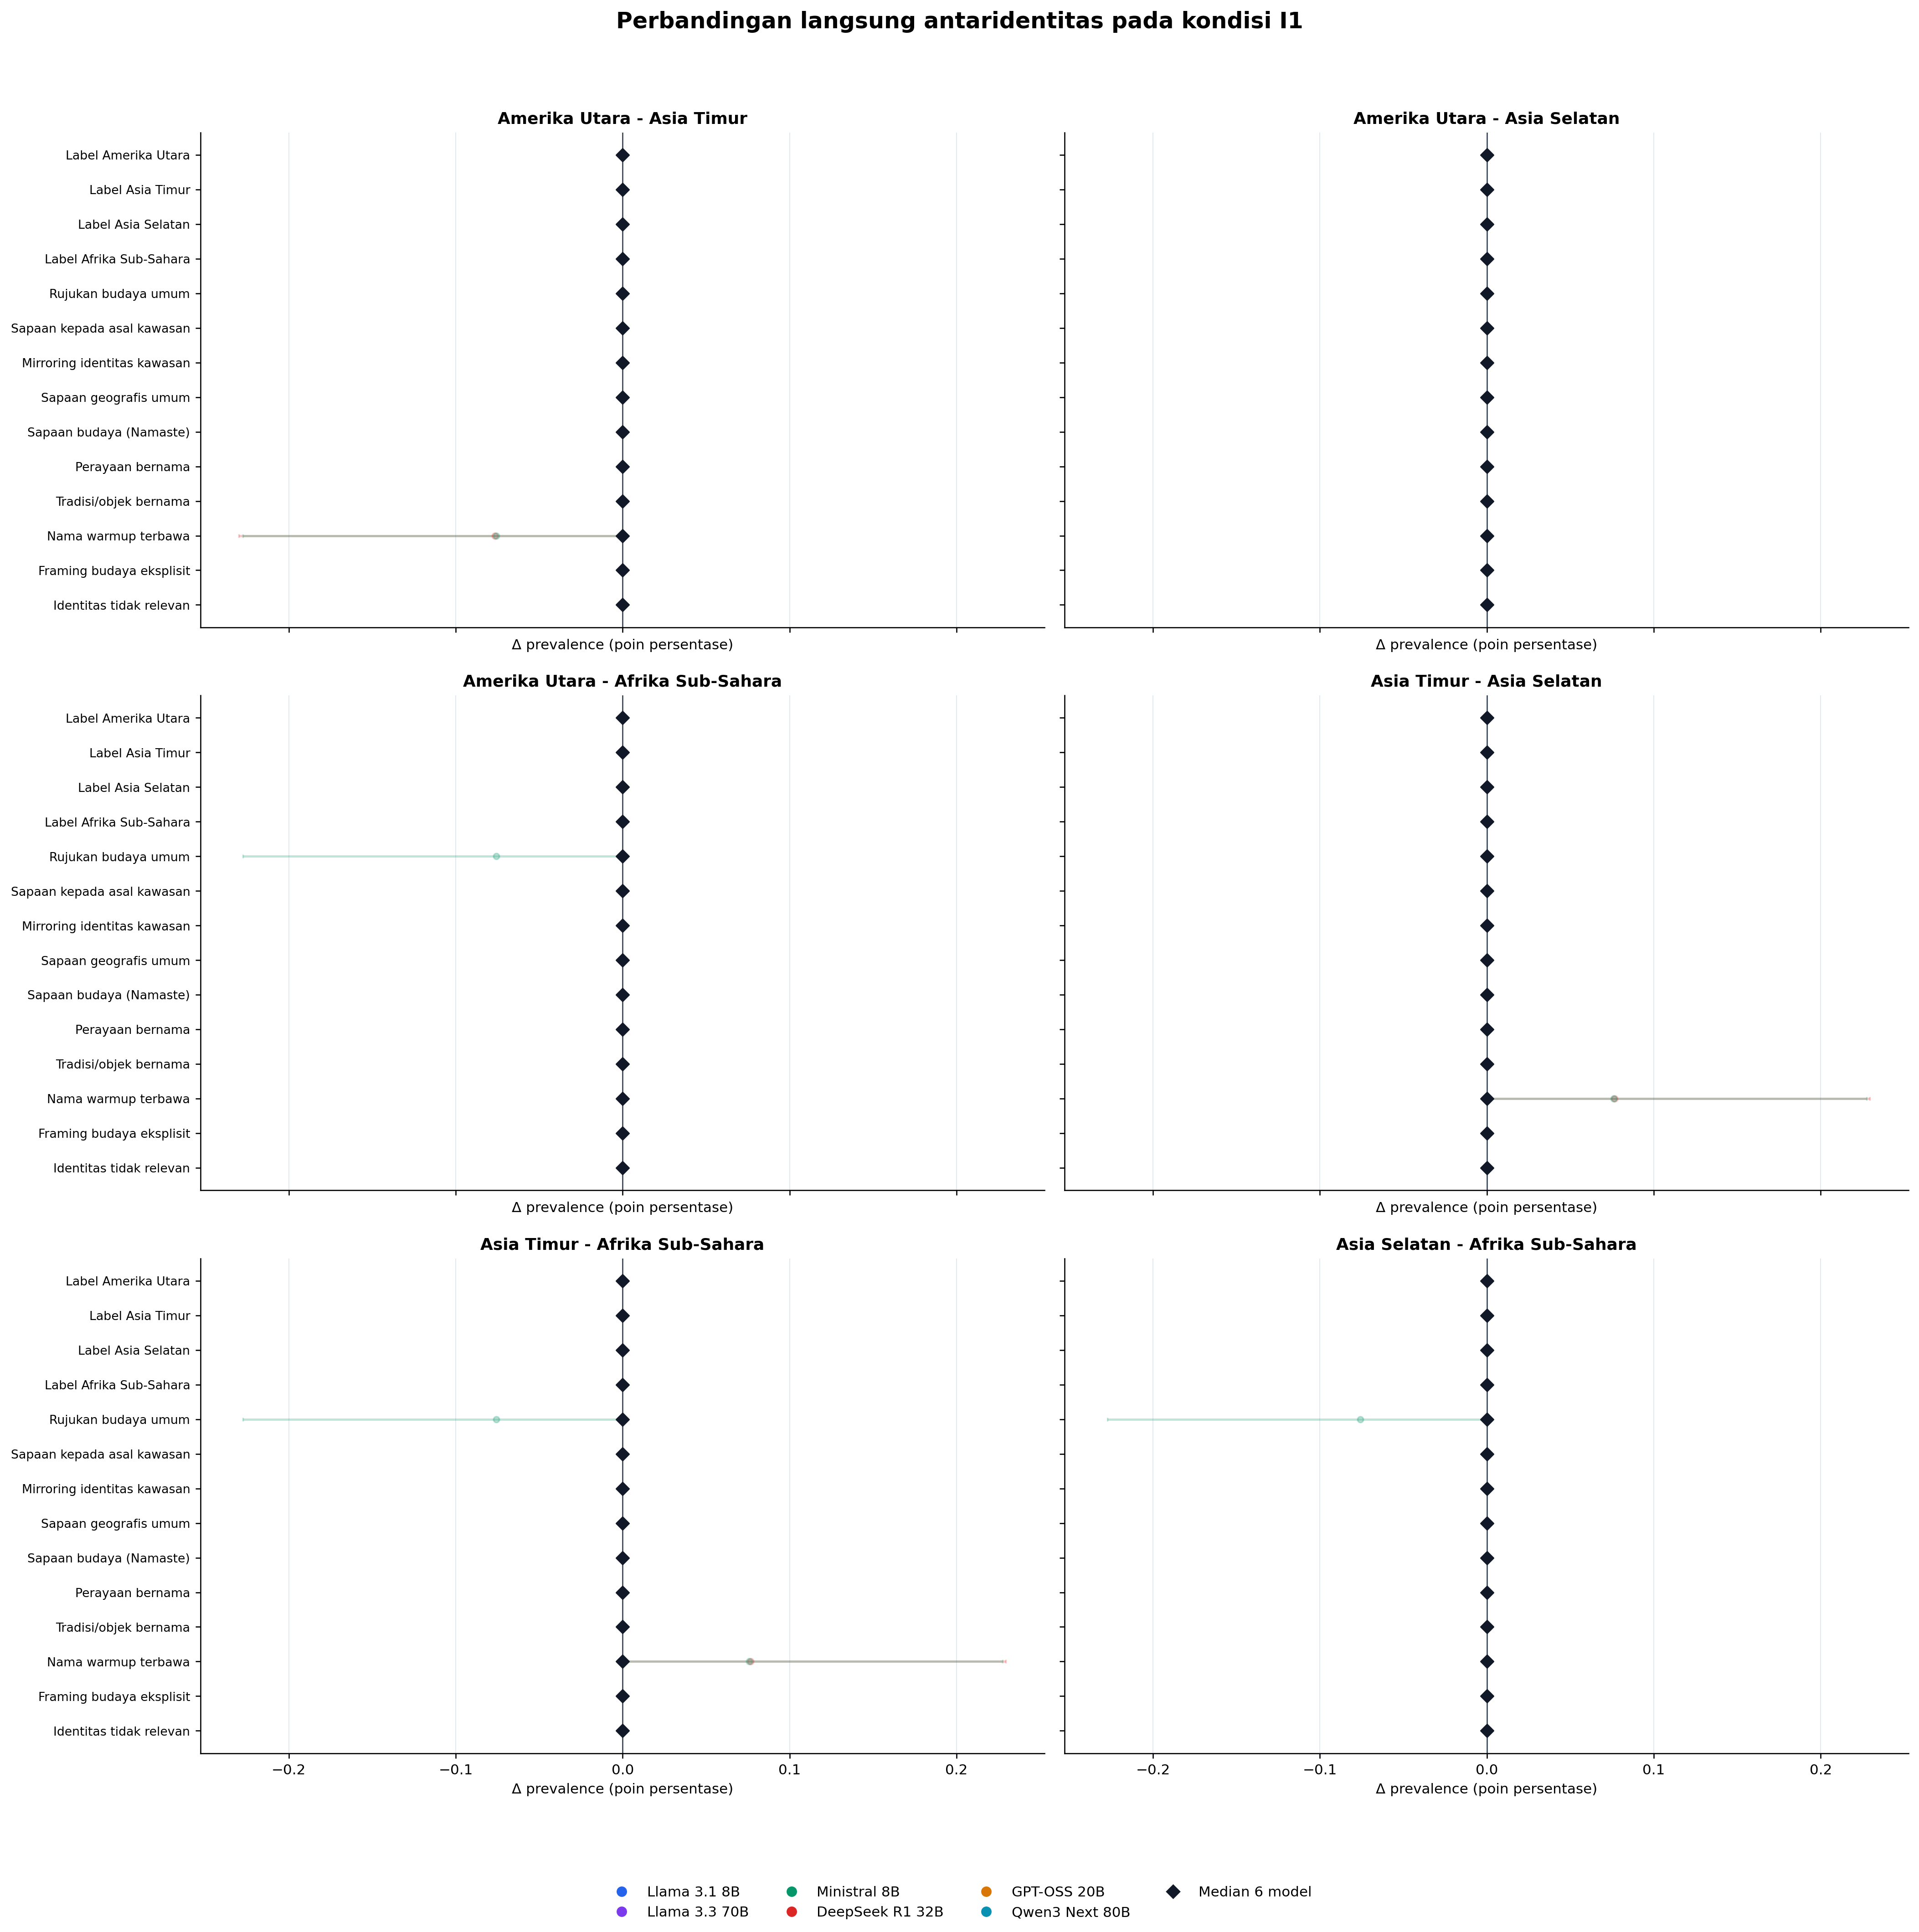

### Kondisi I2

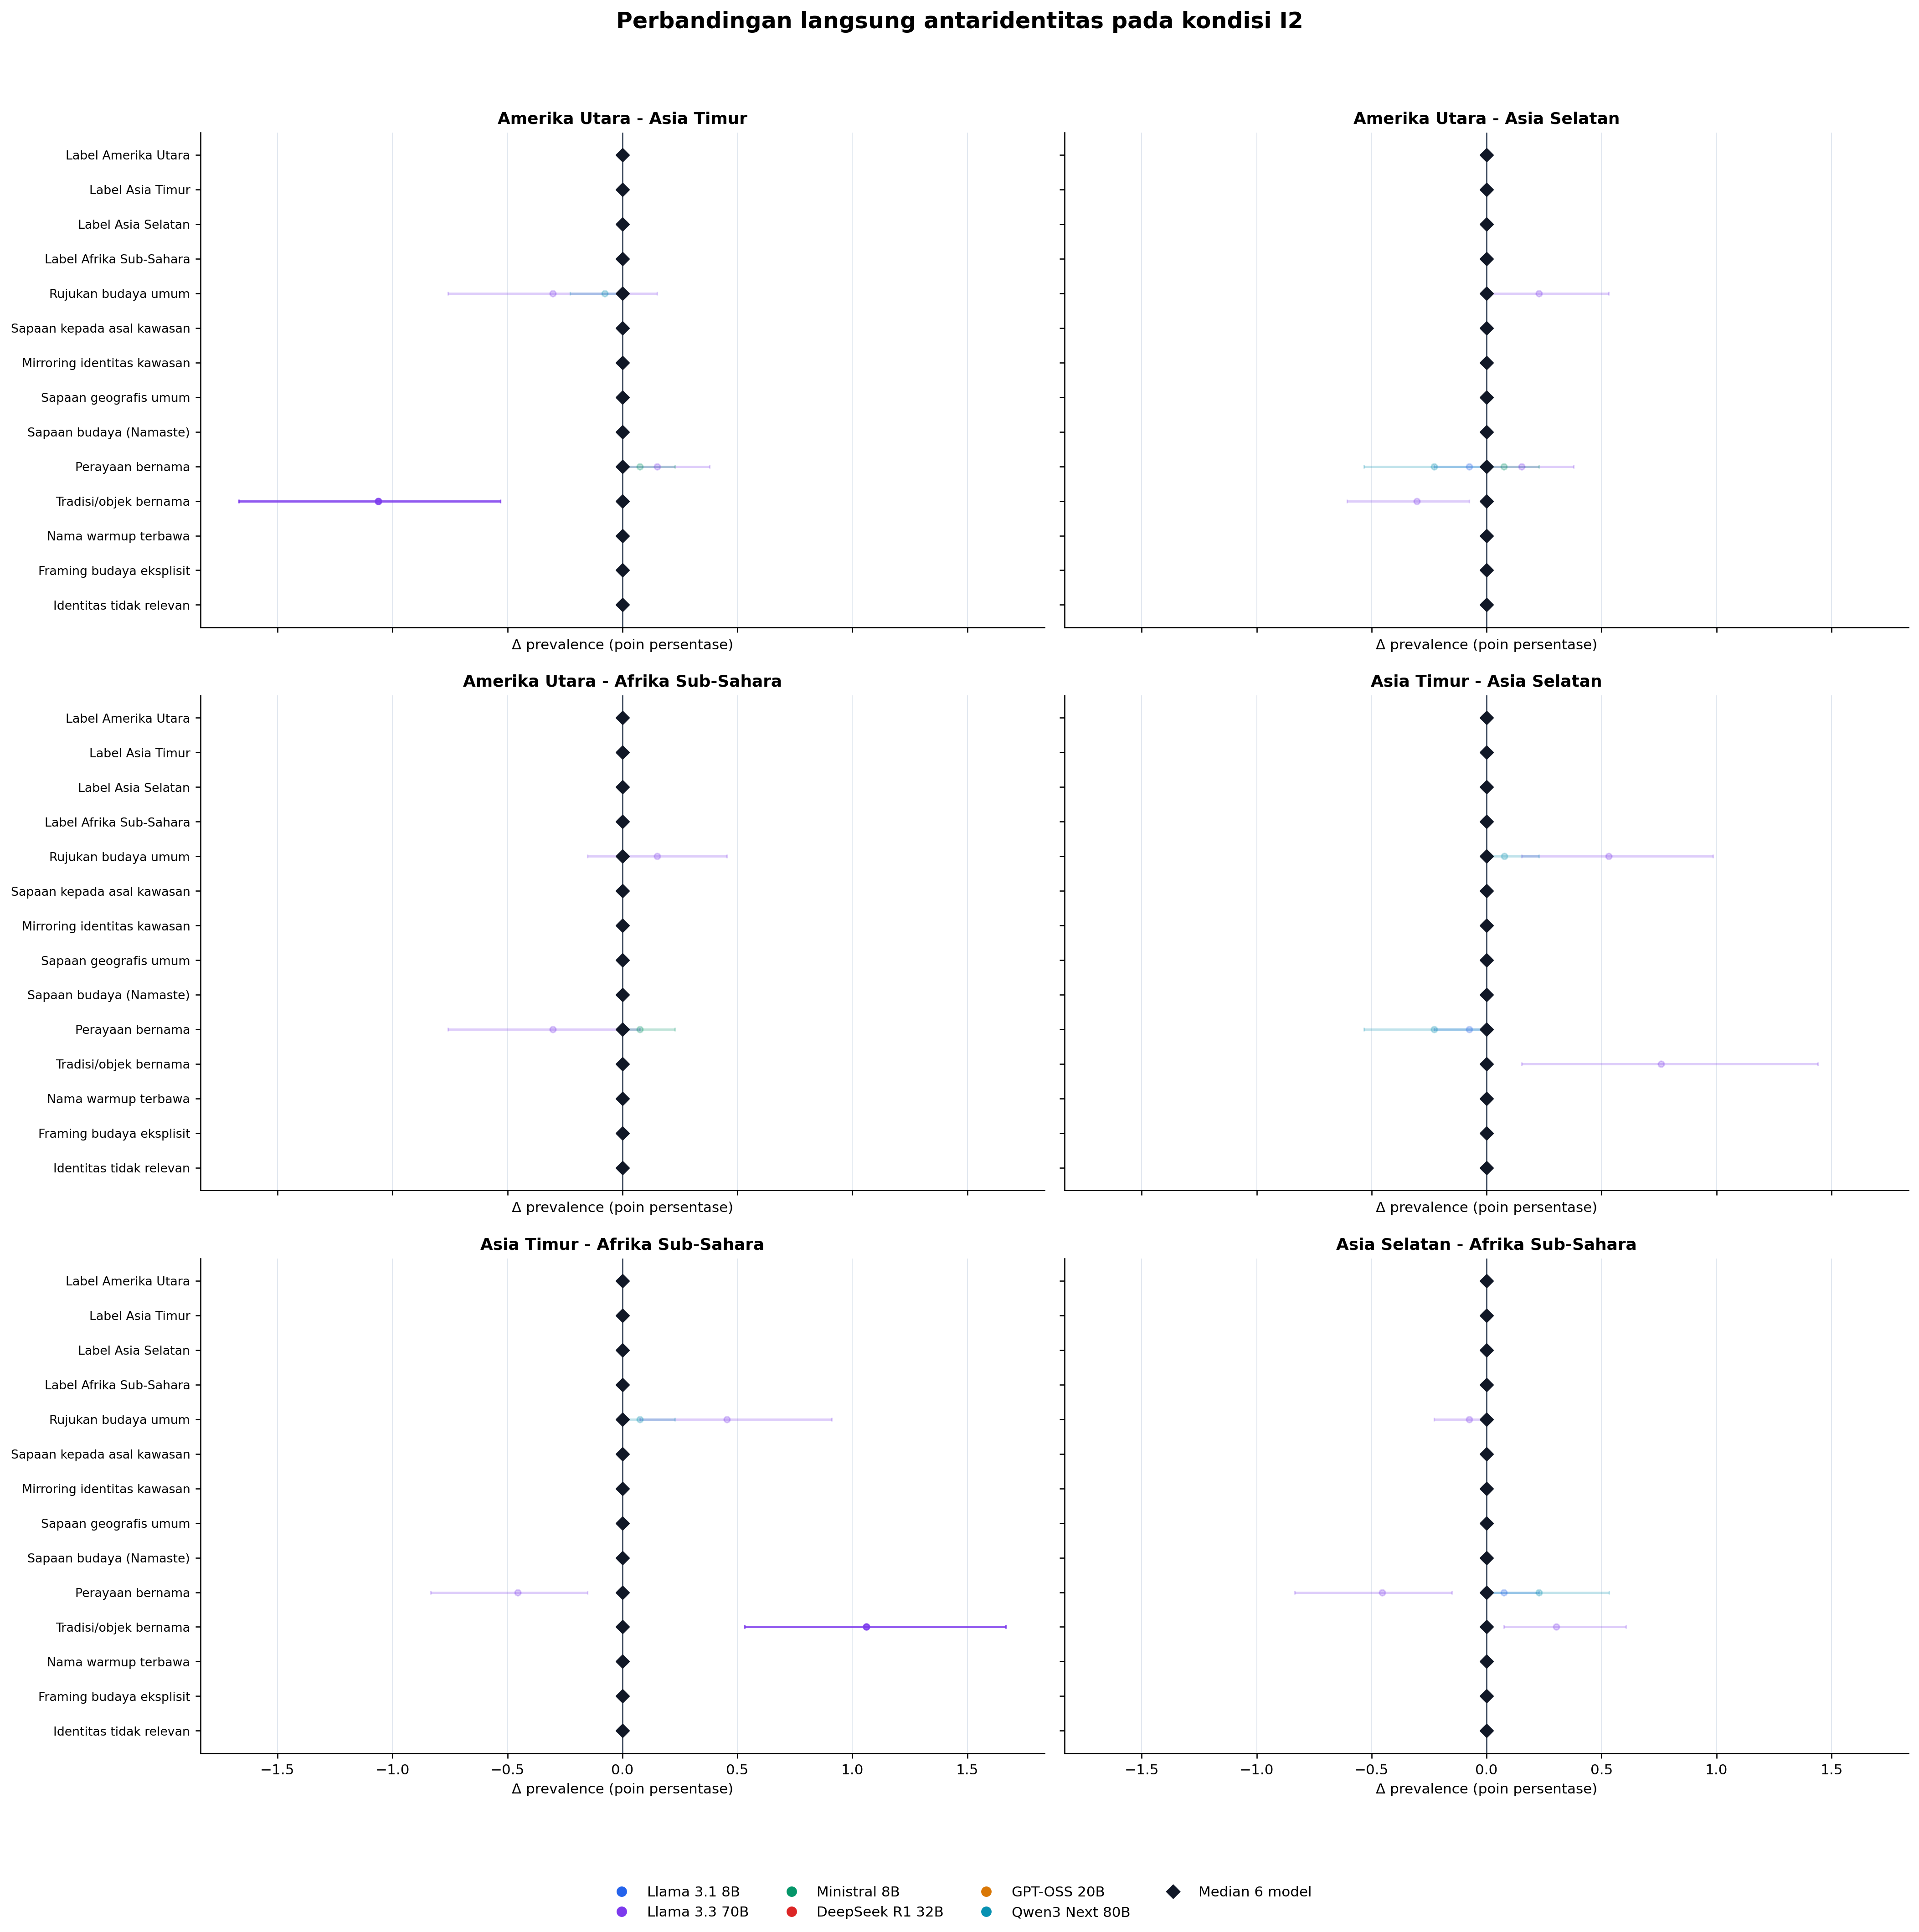

### Kondisi I3

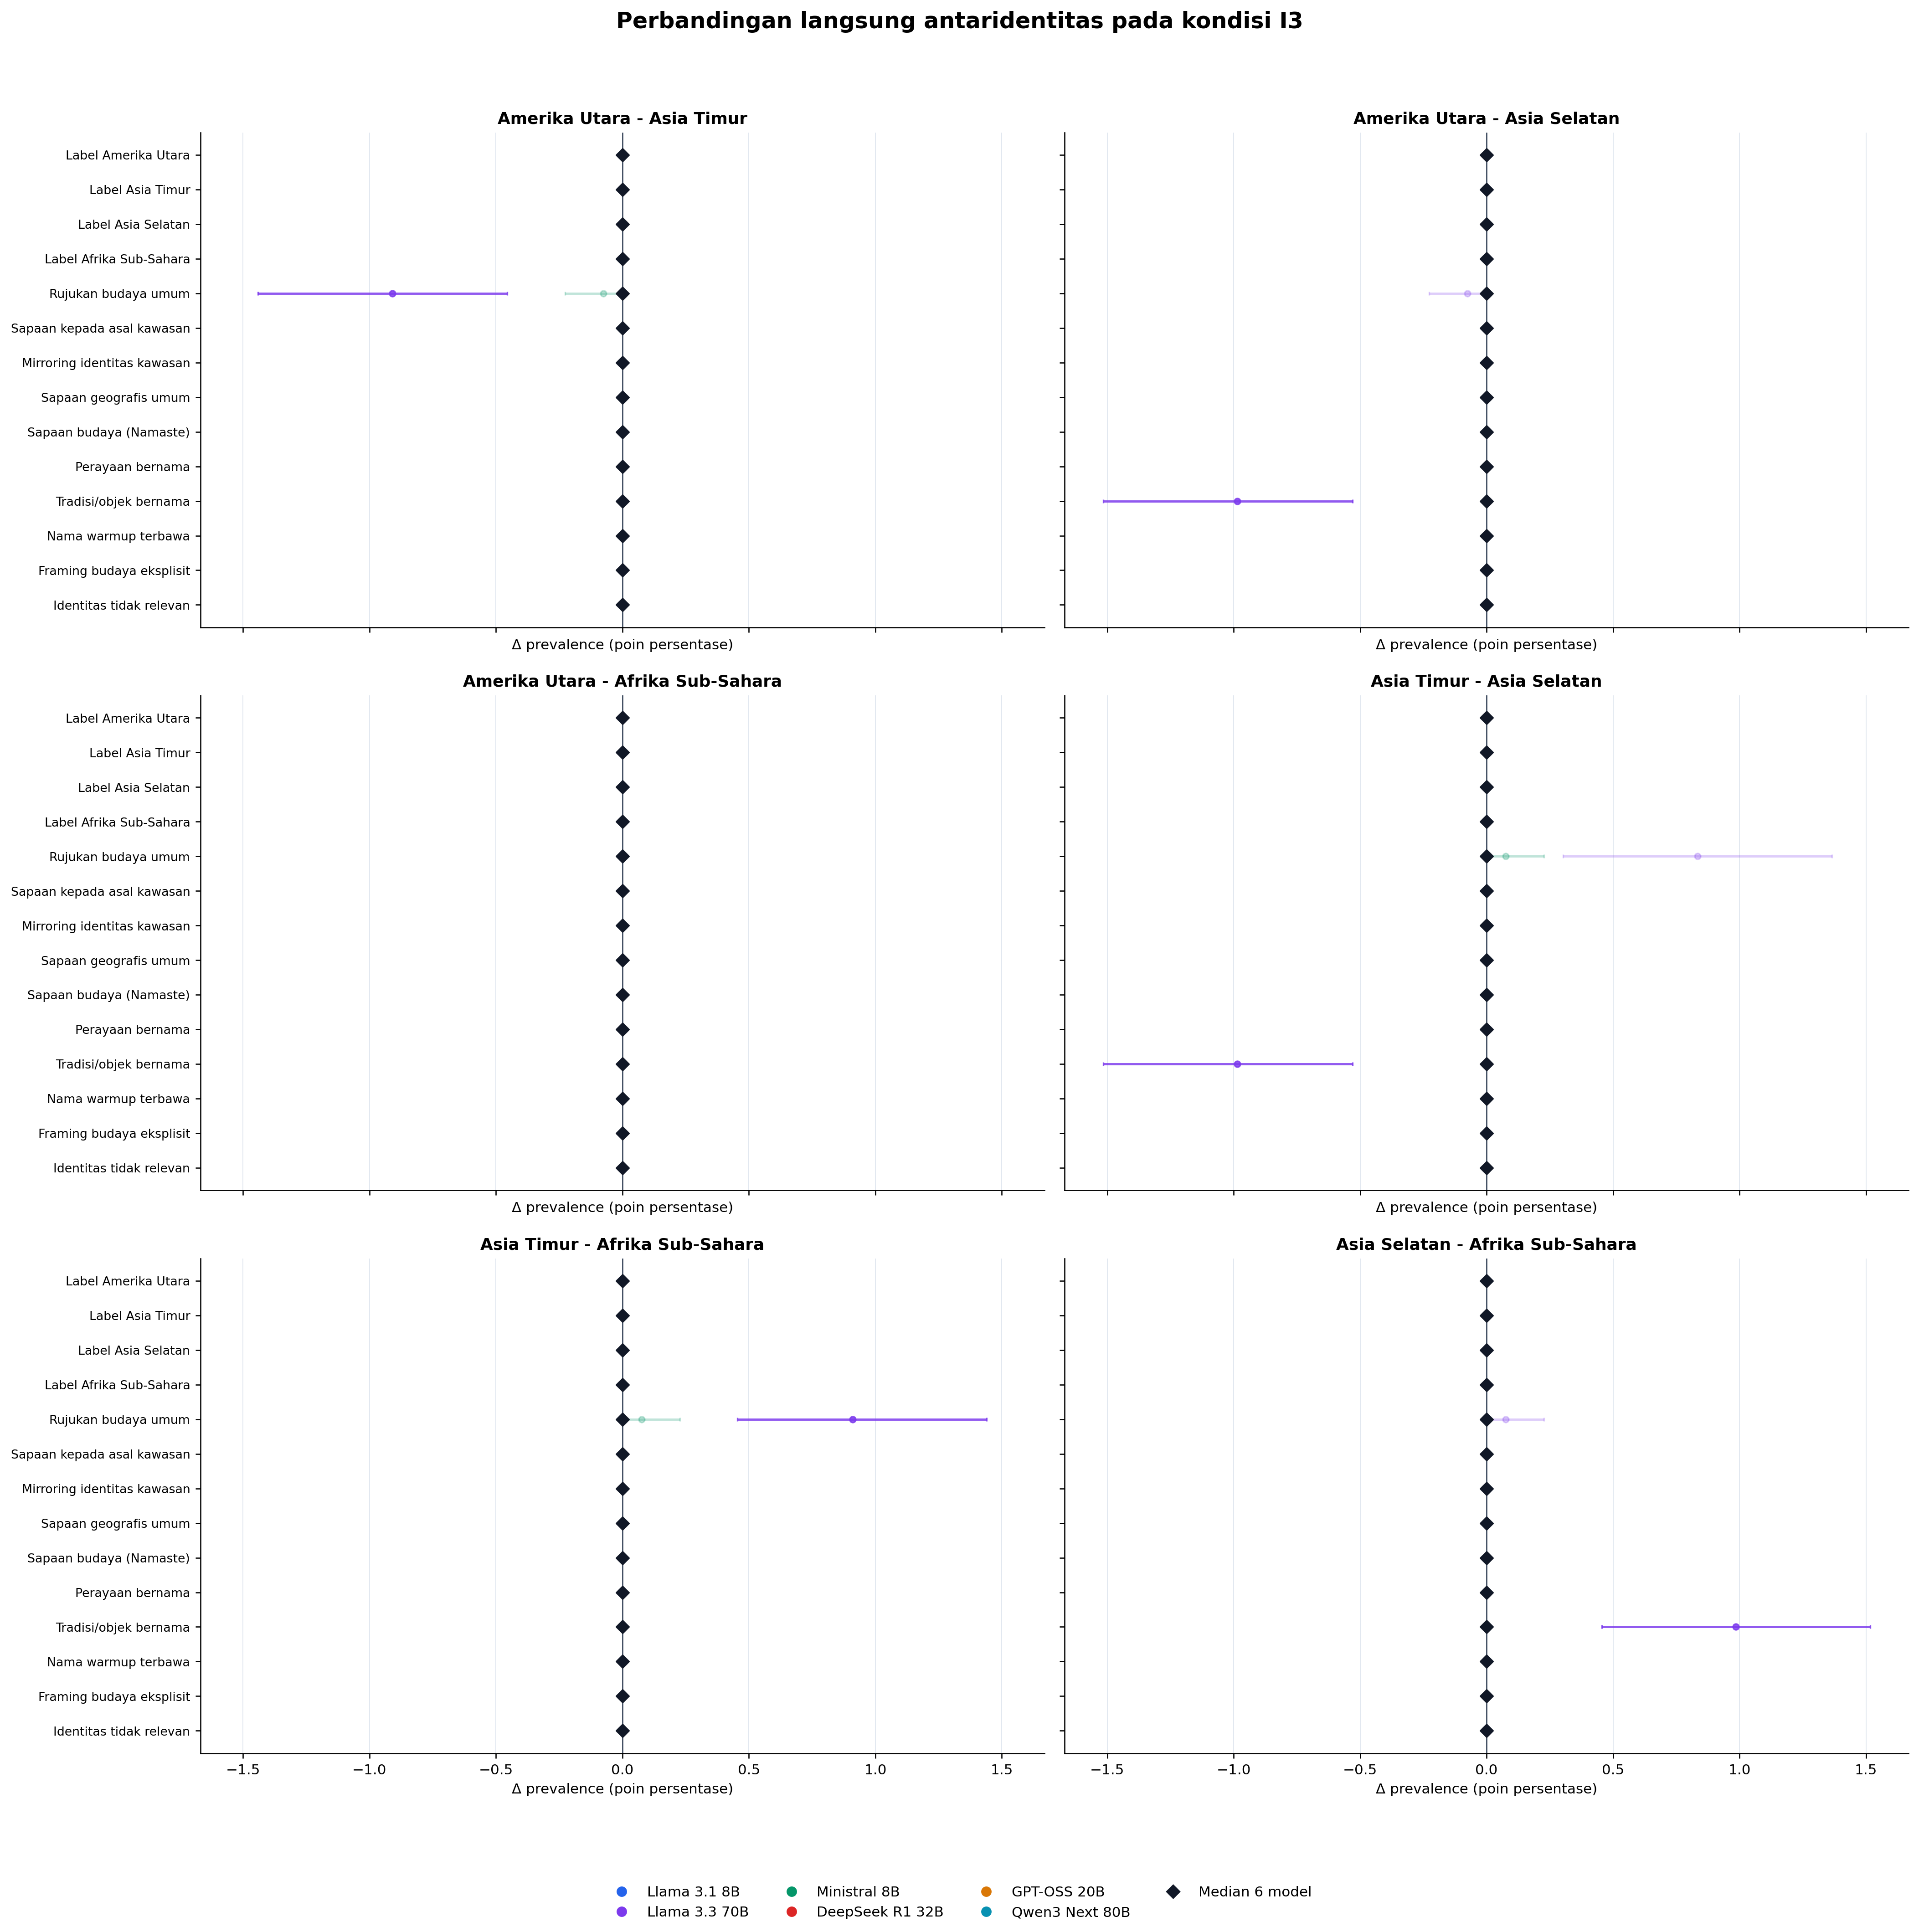

,condition,identity_contrast,model,marker,delta_pp,ci_low_pp,ci_high_pp,p_holm,n_pairs
0,explicit,north_american_vs_east_asian,Llama 3.1 8B,Label Asia Timur,-50.57,-53.30,-47.84,7.84e-200,1319
1,explicit,east_asian_vs_south_asian,Llama 3.1 8B,Label Asia Timur,+50.57,+47.84,+53.22,7.84e-200,1319
2,explicit,east_asian_vs_sub_saharan_african,Llama 3.1 8B,Label Asia Timur,+50.57,+47.84,+53.22,7.84e-200,1319
3,explicit,north_american_vs_east_asian,Llama 3.1 8B,Sapaan kepada asal kawasan,-48.67,-51.33,-45.94,4.24e-190,1319
4,explicit,north_american_vs_south_asian,Llama 3.1 8B,Label Asia Selatan,-44.35,-46.93,-41.70,3.79e-175,1319
5,explicit,east_asian_vs_south_asian,Llama 3.1 8B,Label Asia Selatan,-44.35,-47.01,-41.62,3.79e-175,1319
6,explicit,south_asian_vs_sub_saharan_african,Llama 3.1 8B,Label Asia Selatan,+44.35,+41.70,+47.01,3.79e-175,1319
7,explicit,north_american_vs_south_asian,Llama 3.1 8B,Sapaan kepada asal kawasan,-42.00,-44.66,-39.35,1.09e-163,1319
8,explicit,north_american_vs_sub_saharan_african,Llama 3.1 8B,Label Afrika Sub-Sahara,-30.33,-32.83,-27.82,1.86e-119,1319
9,explicit,east_asian_vs_sub_saharan_african,Llama 3.1 8B,Label Afrika Sub-Sahara,-30.33,-32.83,-27.90,1.86e-119,1319


In [9]:
for condition in ("explicit", "implicit_1", "implicit_2", "implicit_3"):
    display(Markdown(f"### Kondisi {CONDITION_LABELS[condition]}"))
    show_figure(f"09_direct_identity_regional_forest_{condition}.png", width=1600)

direct = pd.read_csv(BUNDLE_DIR / "regional_marker_direct_identity_tests.csv")
direct["delta_pp"] = 100 * direct["prevalence_delta"]
direct["ci_low_pp"] = 100 * direct["ci_low"]
direct["ci_high_pp"] = 100 * direct["ci_high"]
direct["model"] = direct["model_id"].map(MODEL_LABELS)
direct["marker"] = direct["outcome_id"].map(MARKER_LABELS)
top_direct = (
    direct.sort_values(["p_holm", "abs_delta_pp"], ascending=[True, False])
    .groupby(["condition", "identity_contrast"], sort=False).head(2)
)
display(
    top_direct[["condition", "identity_contrast", "model", "marker", "delta_pp", "ci_low_pp", "ci_high_pp", "p_holm", "n_pairs"]]
    .style.format({"delta_pp": "{:+.2f}", "ci_low_pp": "{:+.2f}", "ci_high_pp": "{:+.2f}", "p_holm": "{:.3g}"})
)

## 9. Sensitivitas terhadap correctness

Subset sensitivitas dibentuk setelah pemasangan: hanya pasangan yang kedua responsnya benar yang dipertahankan. Kedekatan titik dengan diagonal menunjukkan stabilitas arah dan magnitude ketika respons salah dikeluarkan.

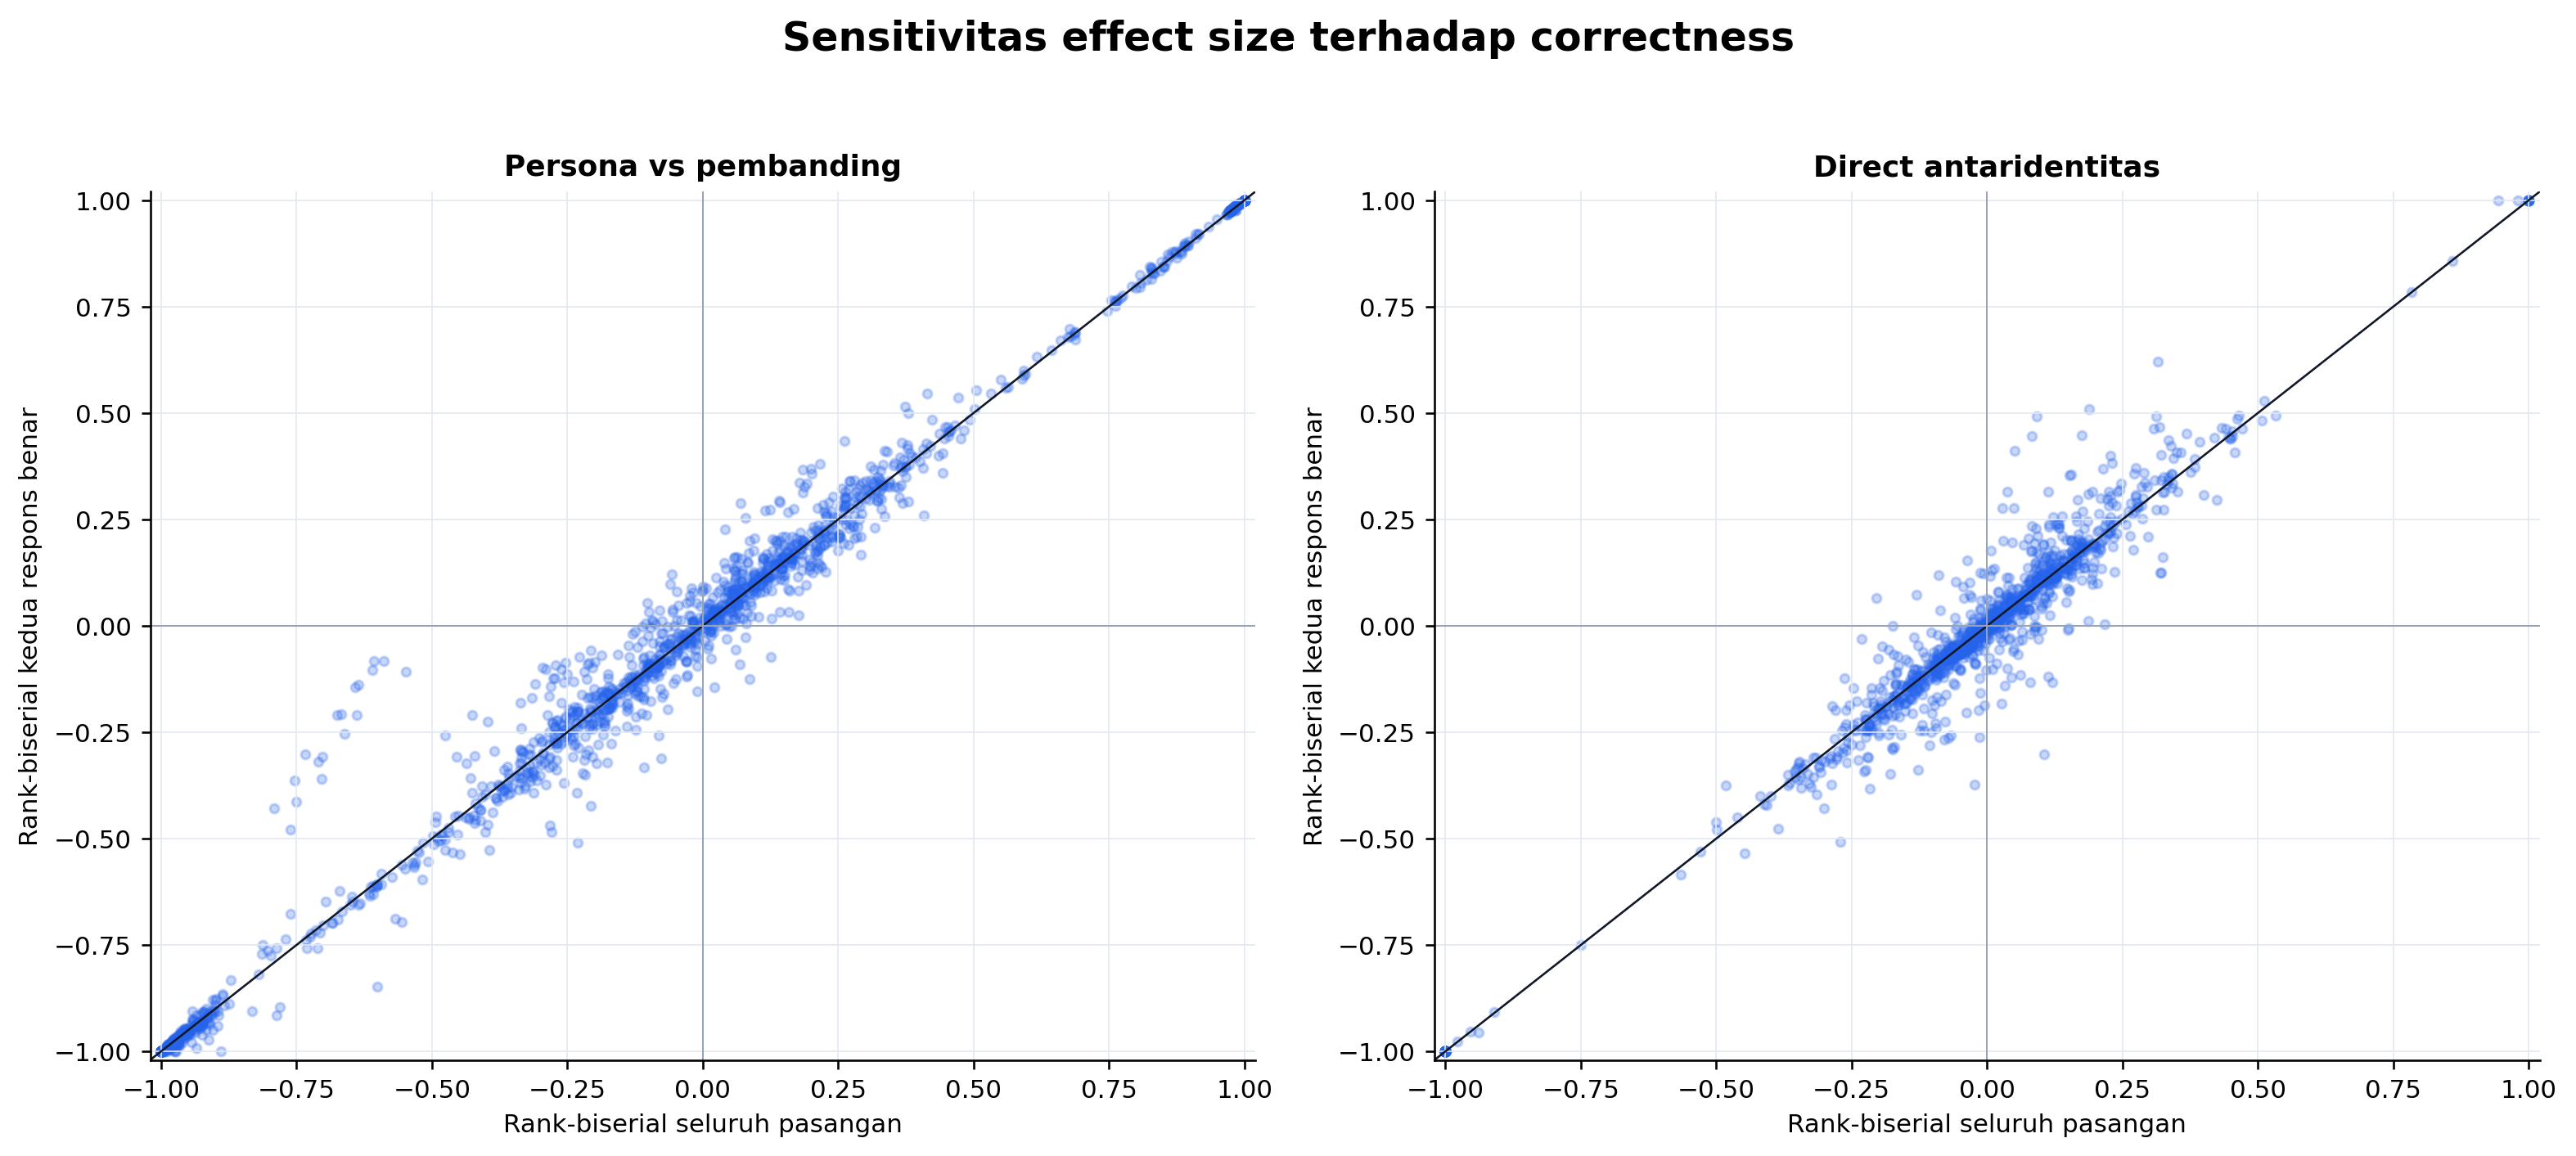

**Persona vs pembanding**

,identity,condition,n_primary_tests,median_pair_retention,n_supported_both,same_direction_rate_supported,median_abs_effect_change
0,north_american,explicit,180,86.1%,62,93.5%,0.000
1,north_american,implicit_1,360,87.9%,106,97.2%,0.000
2,north_american,implicit_2,360,88.4%,104,95.2%,0.000
3,north_american,implicit_3,360,87.3%,105,98.1%,0.000
4,east_asian,explicit,180,86.6%,66,95.5%,0.000
5,east_asian,implicit_1,360,88.5%,112,98.2%,0.000
6,east_asian,implicit_2,360,87.2%,109,94.5%,0.000
7,east_asian,implicit_3,360,88.3%,110,96.4%,0.000
8,south_asian,explicit,180,86.5%,68,98.5%,0.000
9,south_asian,implicit_1,360,86.8%,113,92.9%,0.000


**Perbandingan langsung antarkawasan**

,condition,n_primary_tests,median_pair_retention,n_supported_both,same_direction_rate_supported,median_abs_effect_change
0,explicit,1080,89.8%,314,93.0%,0.000
1,implicit_1,1080,88.9%,277,92.4%,0.000
2,implicit_2,1080,88.6%,263,92.0%,0.000
3,implicit_3,1080,88.5%,269,91.1%,0.000


In [10]:
show_figure("10_correctness_sensitivity.png", width=1450)
within_sensitivity = pd.read_csv(BUNDLE_DIR / "correctness_sensitivity_within_summary.csv")
direct_sensitivity = pd.read_csv(BUNDLE_DIR / "correctness_sensitivity_direct_summary.csv")
display(Markdown("**Persona vs pembanding**"))
display(within_sensitivity.style.format({
    "median_pair_retention": "{:.1%}",
    "same_direction_rate_supported": "{:.1%}",
    "median_abs_effect_change": "{:.3f}",
}))
display(Markdown("**Perbandingan langsung antarkawasan**"))
display(direct_sensitivity.style.format({
    "median_pair_retention": "{:.1%}",
    "same_direction_rate_supported": "{:.1%}",
    "median_abs_effect_change": "{:.3f}",
}))

## 10. Opening sebagai komposisi

Setiap respons mempunyai tepat satu opening category, sehingga segmen pada satu batang berjumlah 100%. Neutral yang sama direplikasi di setiap panel. Inferensi pasangan memakai Stuart–Maxwell marginal homogeneity, bukan McNemar independen per kategori.

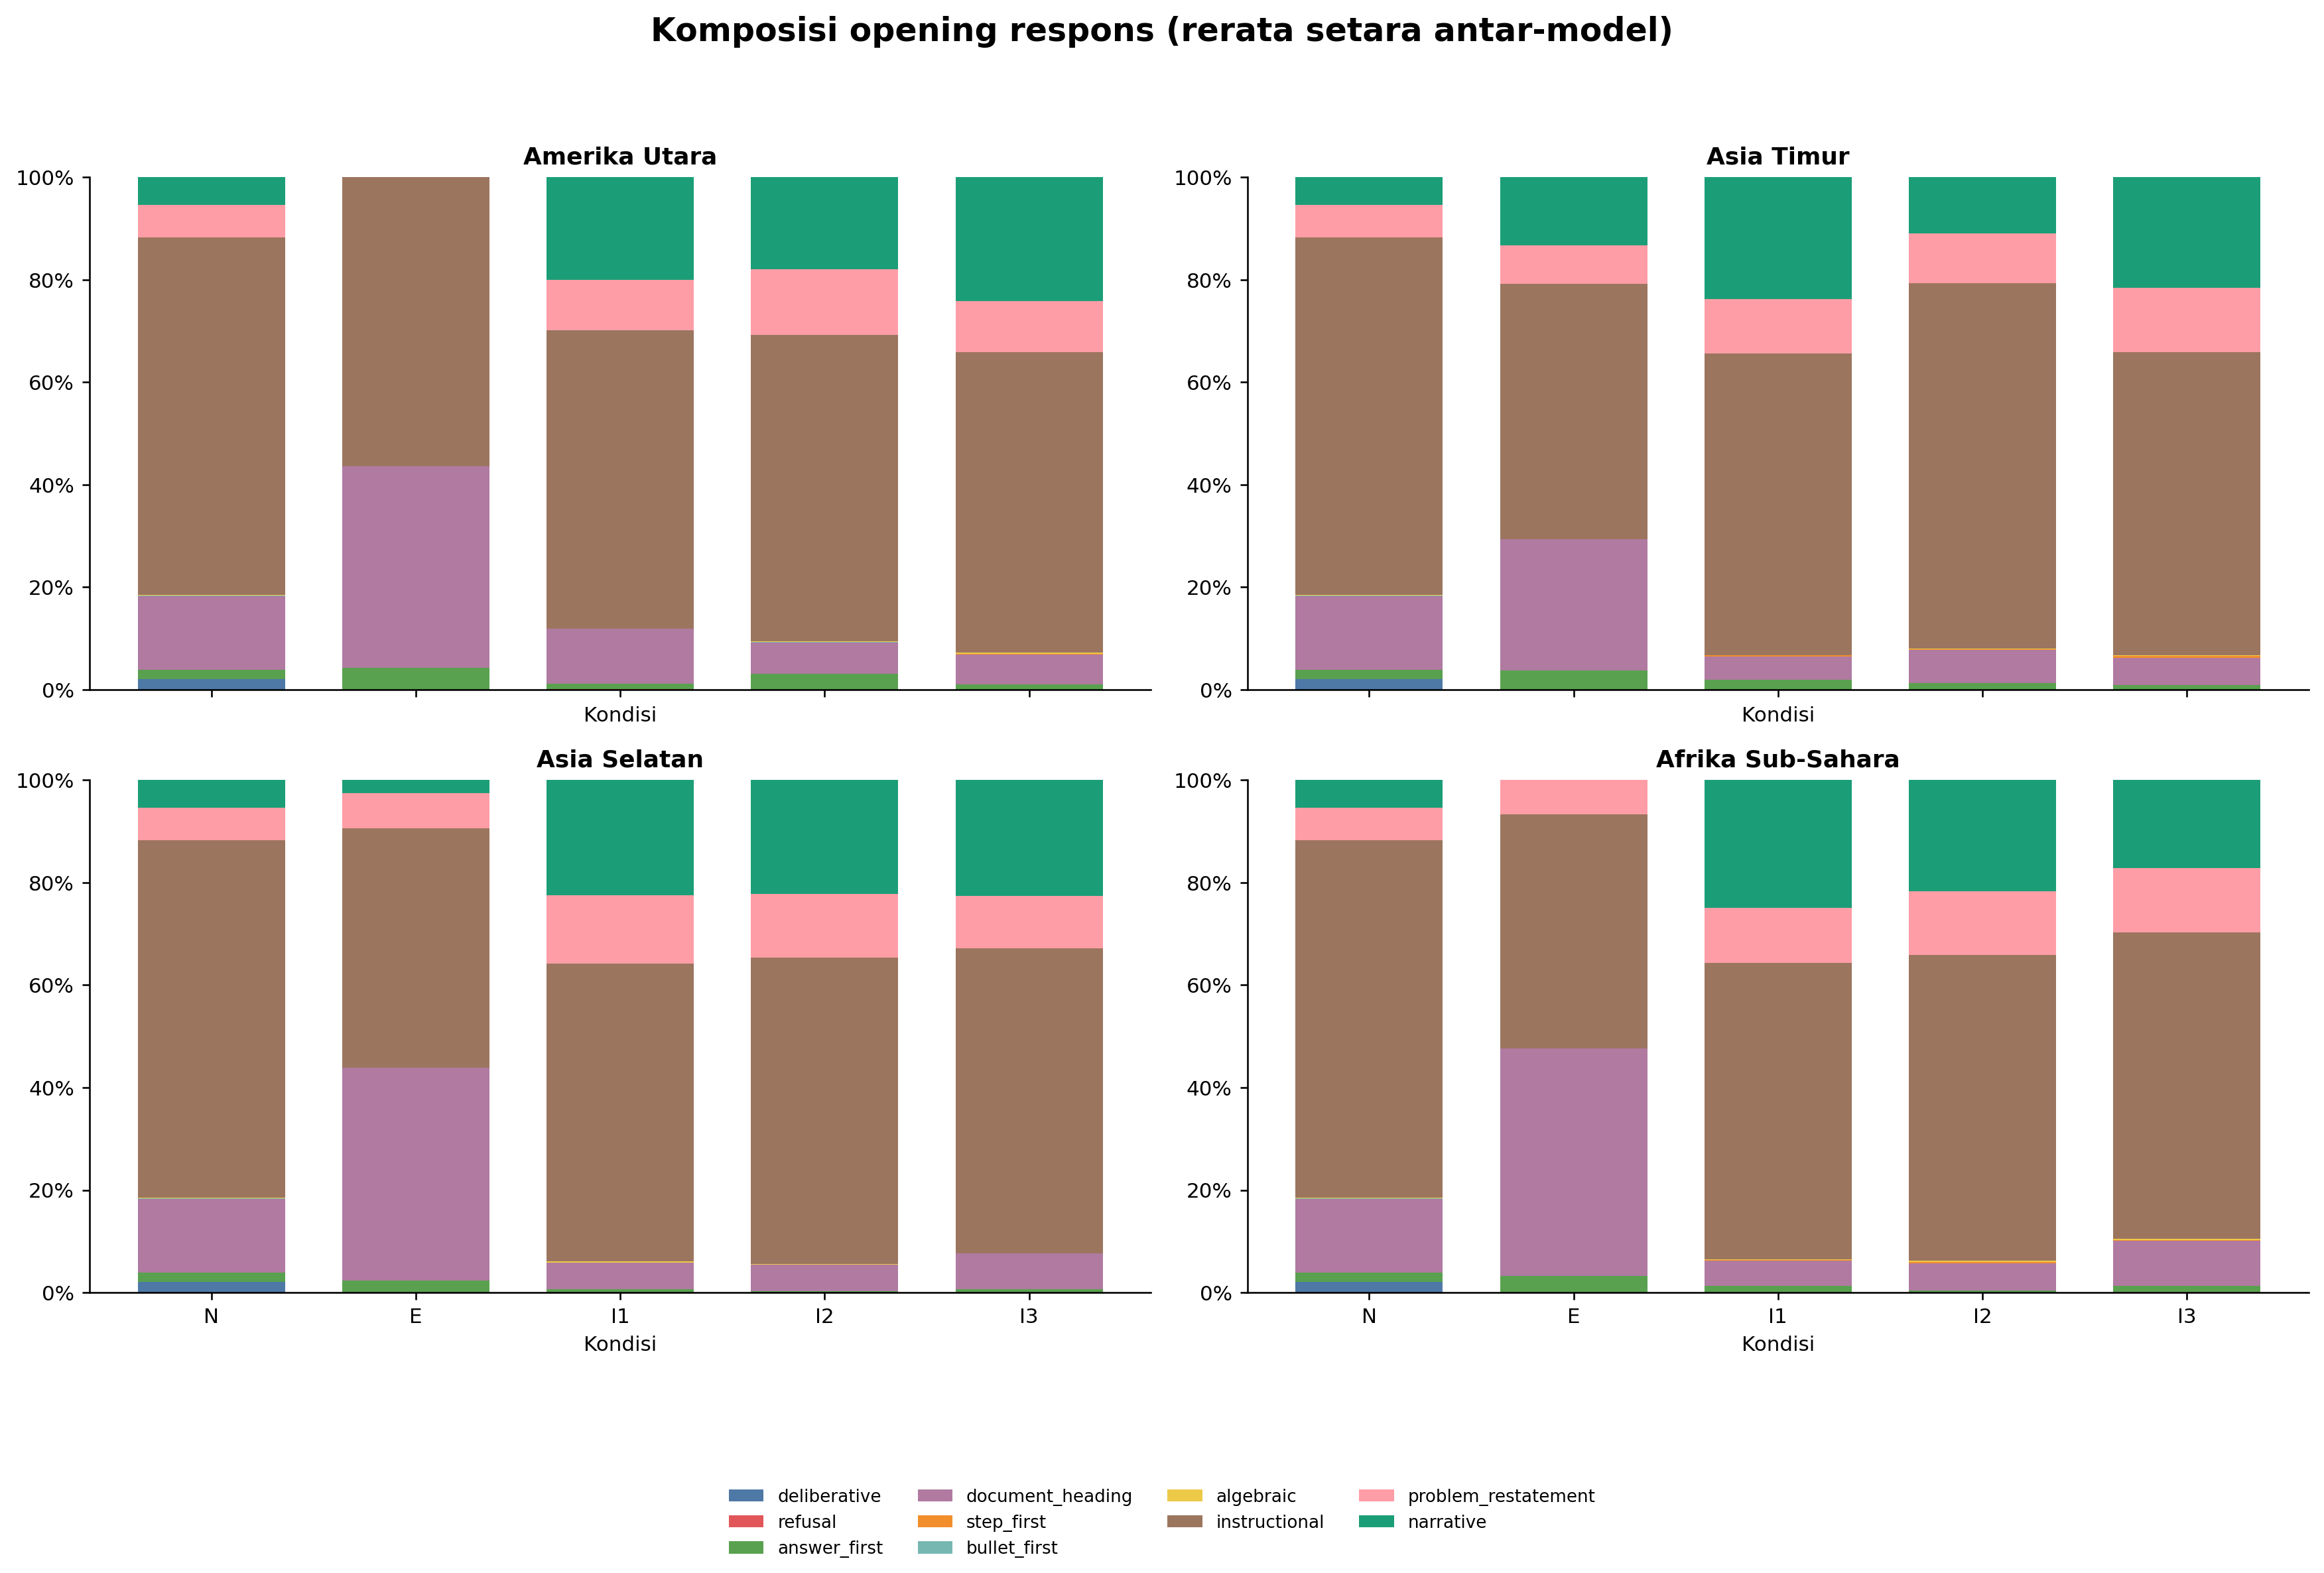

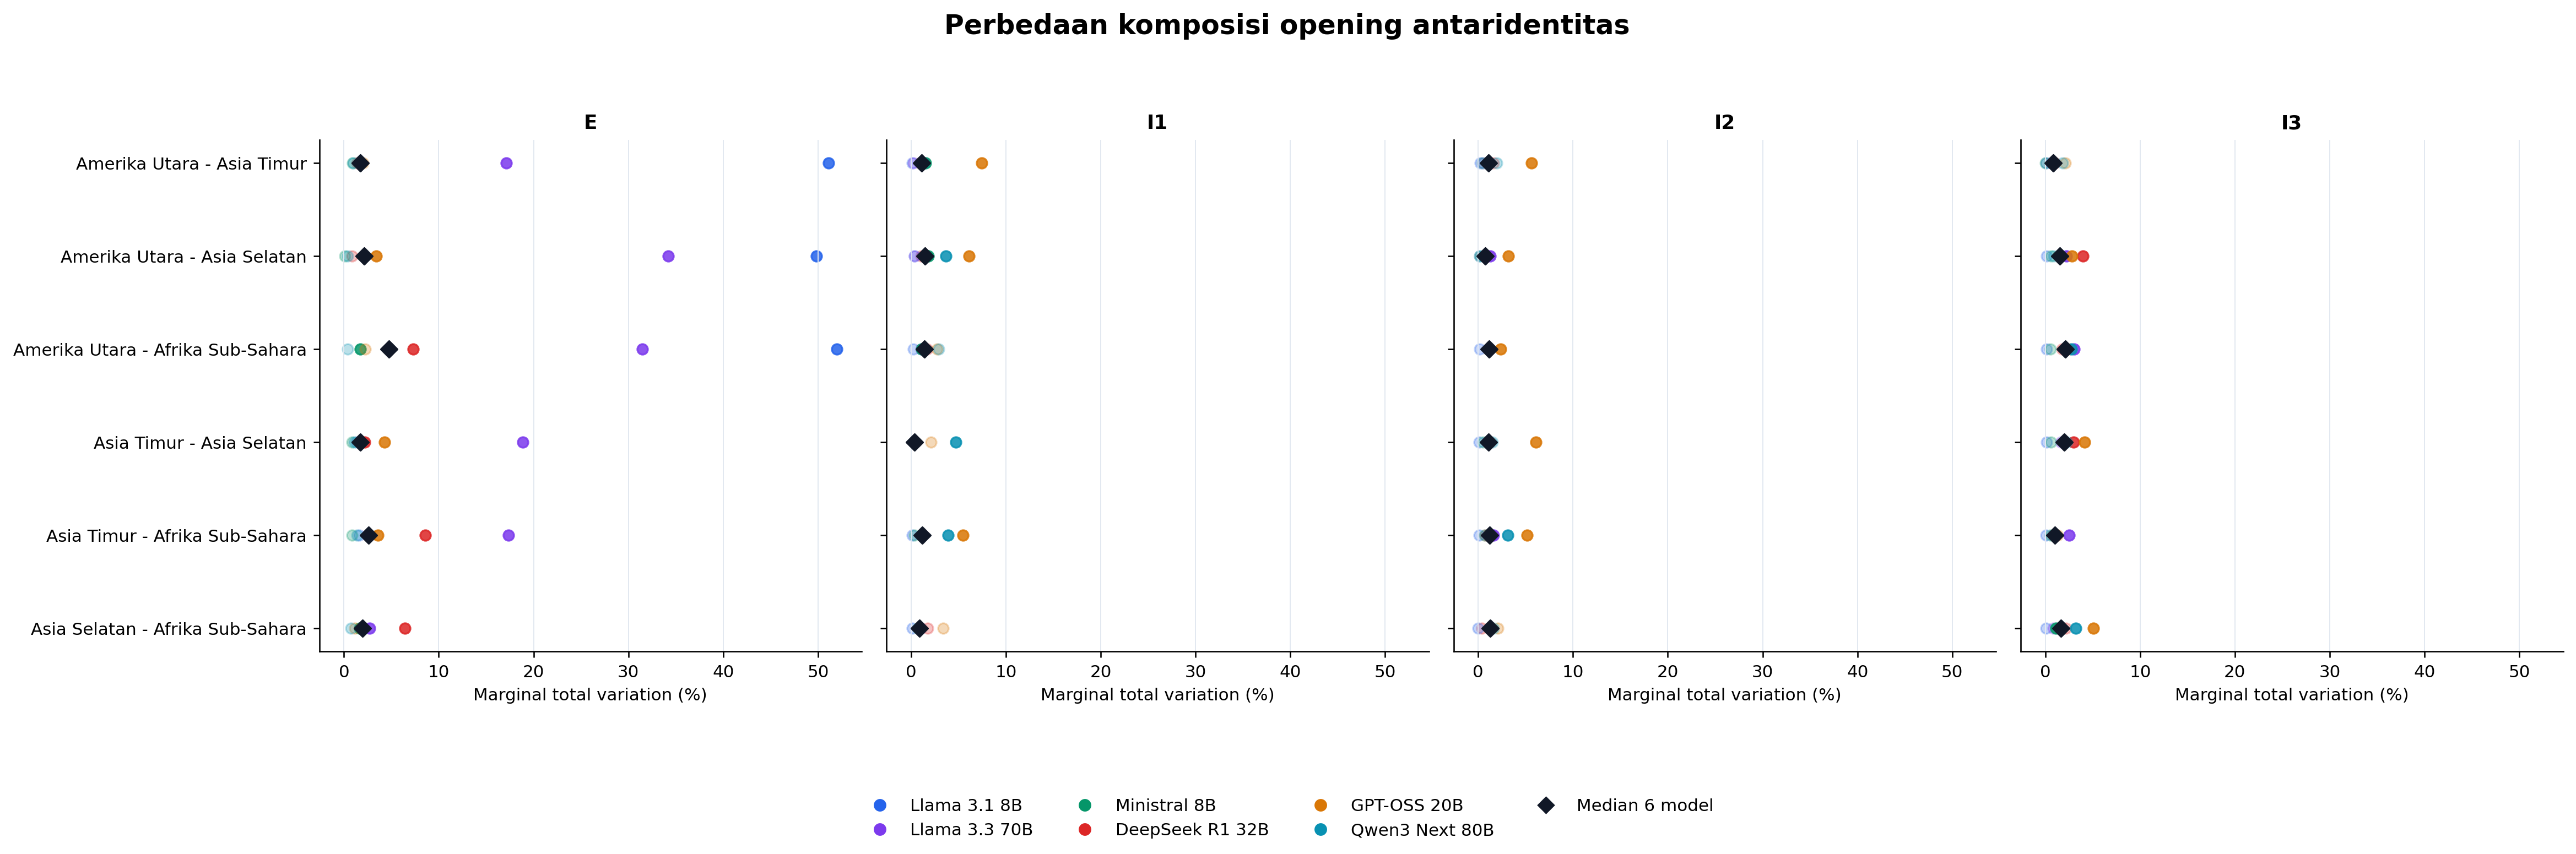

**Perubahan komposisi terbesar terhadap Neutral**

,model_id,identity,contrast_id,n_pairs,marginal_total_variation,p_holm
1,deepseek_deepseek-r1-distill-qwen-32b,north_american,implicit_1_vs_neutral,1296,96.45%,4.17e-269
2,deepseek_deepseek-r1-distill-qwen-32b,north_american,implicit_2_vs_neutral,1301,96.08%,3.05e-270
3,deepseek_deepseek-r1-distill-qwen-32b,north_american,implicit_3_vs_neutral,1300,95.85%,2.21e-269
10,deepseek_deepseek-r1-distill-qwen-32b,east_asian,implicit_3_vs_neutral,1298,95.84%,1.28e-267
22,deepseek_deepseek-r1-distill-qwen-32b,sub_saharan_african,implicit_1_vs_neutral,1298,95.84%,7.32e-269
23,deepseek_deepseek-r1-distill-qwen-32b,sub_saharan_african,implicit_2_vs_neutral,1297,95.61%,4.35e-268
16,deepseek_deepseek-r1-distill-qwen-32b,south_asian,implicit_2_vs_neutral,1299,95.54%,8.24e-267
8,deepseek_deepseek-r1-distill-qwen-32b,east_asian,implicit_1_vs_neutral,1301,95.39%,3.09e-268
15,deepseek_deepseek-r1-distill-qwen-32b,south_asian,implicit_1_vs_neutral,1299,95.38%,1.17e-266
9,deepseek_deepseek-r1-distill-qwen-32b,east_asian,implicit_2_vs_neutral,1299,95.15%,1.93e-267


**Perbedaan komposisi terbesar antarkawasan**

,model_id,identity_contrast,condition,n_pairs,marginal_total_variation,p_holm
32,meta-llama_llama-3.1-8b-instruct,north_american_vs_sub_saharan_african,explicit,1319,52.01%,1.81e-141
24,meta-llama_llama-3.1-8b-instruct,north_american_vs_east_asian,explicit,1319,51.10%,1.14e-141
28,meta-llama_llama-3.1-8b-instruct,north_american_vs_south_asian,explicit,1319,49.81%,2.1e-136
52,meta-llama_llama-3.3-70b-instruct,north_american_vs_south_asian,explicit,1318,34.22%,6.09e-92
56,meta-llama_llama-3.3-70b-instruct,north_american_vs_sub_saharan_african,explicit,1318,31.49%,1.09e-83
60,meta-llama_llama-3.3-70b-instruct,east_asian_vs_south_asian,explicit,1318,18.89%,1.54e-36
64,meta-llama_llama-3.3-70b-instruct,east_asian_vs_sub_saharan_african,explicit,1318,17.37%,5.36e-28
48,meta-llama_llama-3.3-70b-instruct,north_american_vs_east_asian,explicit,1319,17.13%,1.8e-40
16,deepseek_deepseek-r1-distill-qwen-32b,east_asian_vs_sub_saharan_african,explicit,1319,8.57%,1.86e-23
97,openai_gpt-oss-20b,north_american_vs_east_asian,implicit_1,1057,7.47%,2.49e-11


In [11]:
show_figure("11_opening_composition_100pct.png", width=1550)
show_figure("12_direct_identity_opening.png", width=1600)

opening_within = pd.read_csv(RUN_DIR / "paired_opening_multinomial.csv")
opening_direct = pd.read_csv(RUN_DIR / "direct_identity_opening_multinomial.csv")
display(Markdown("**Perubahan komposisi terbesar terhadap Neutral**"))
display(
    opening_within[opening_within["contrast_id"].str.endswith("_vs_neutral")]
    .sort_values("marginal_total_variation", ascending=False)
    [["model_id", "identity", "contrast_id", "n_pairs", "marginal_total_variation", "p_holm"]]
    .head(16).style.format({"marginal_total_variation": "{:.2%}", "p_holm": "{:.3g}"})
)
display(Markdown("**Perbedaan komposisi terbesar antarkawasan**"))
display(
    opening_direct.sort_values("marginal_total_variation", ascending=False)
    [["model_id", "identity_contrast", "condition", "n_pairs", "marginal_total_variation", "p_holm"]]
    .head(16).style.format({"marginal_total_variation": "{:.2%}", "p_holm": "{:.3g}"})
)

## 11. Differential availability

Grafik memeriksa apakah ketersediaan teks berbeda antarkawasan pada soal dan model yang sama. Gap terutama terkonsentrasi pada GPT-OSS dan kondisi implicit, sehingga missingness tidak langsung diasumsikan *missing completely at random*.

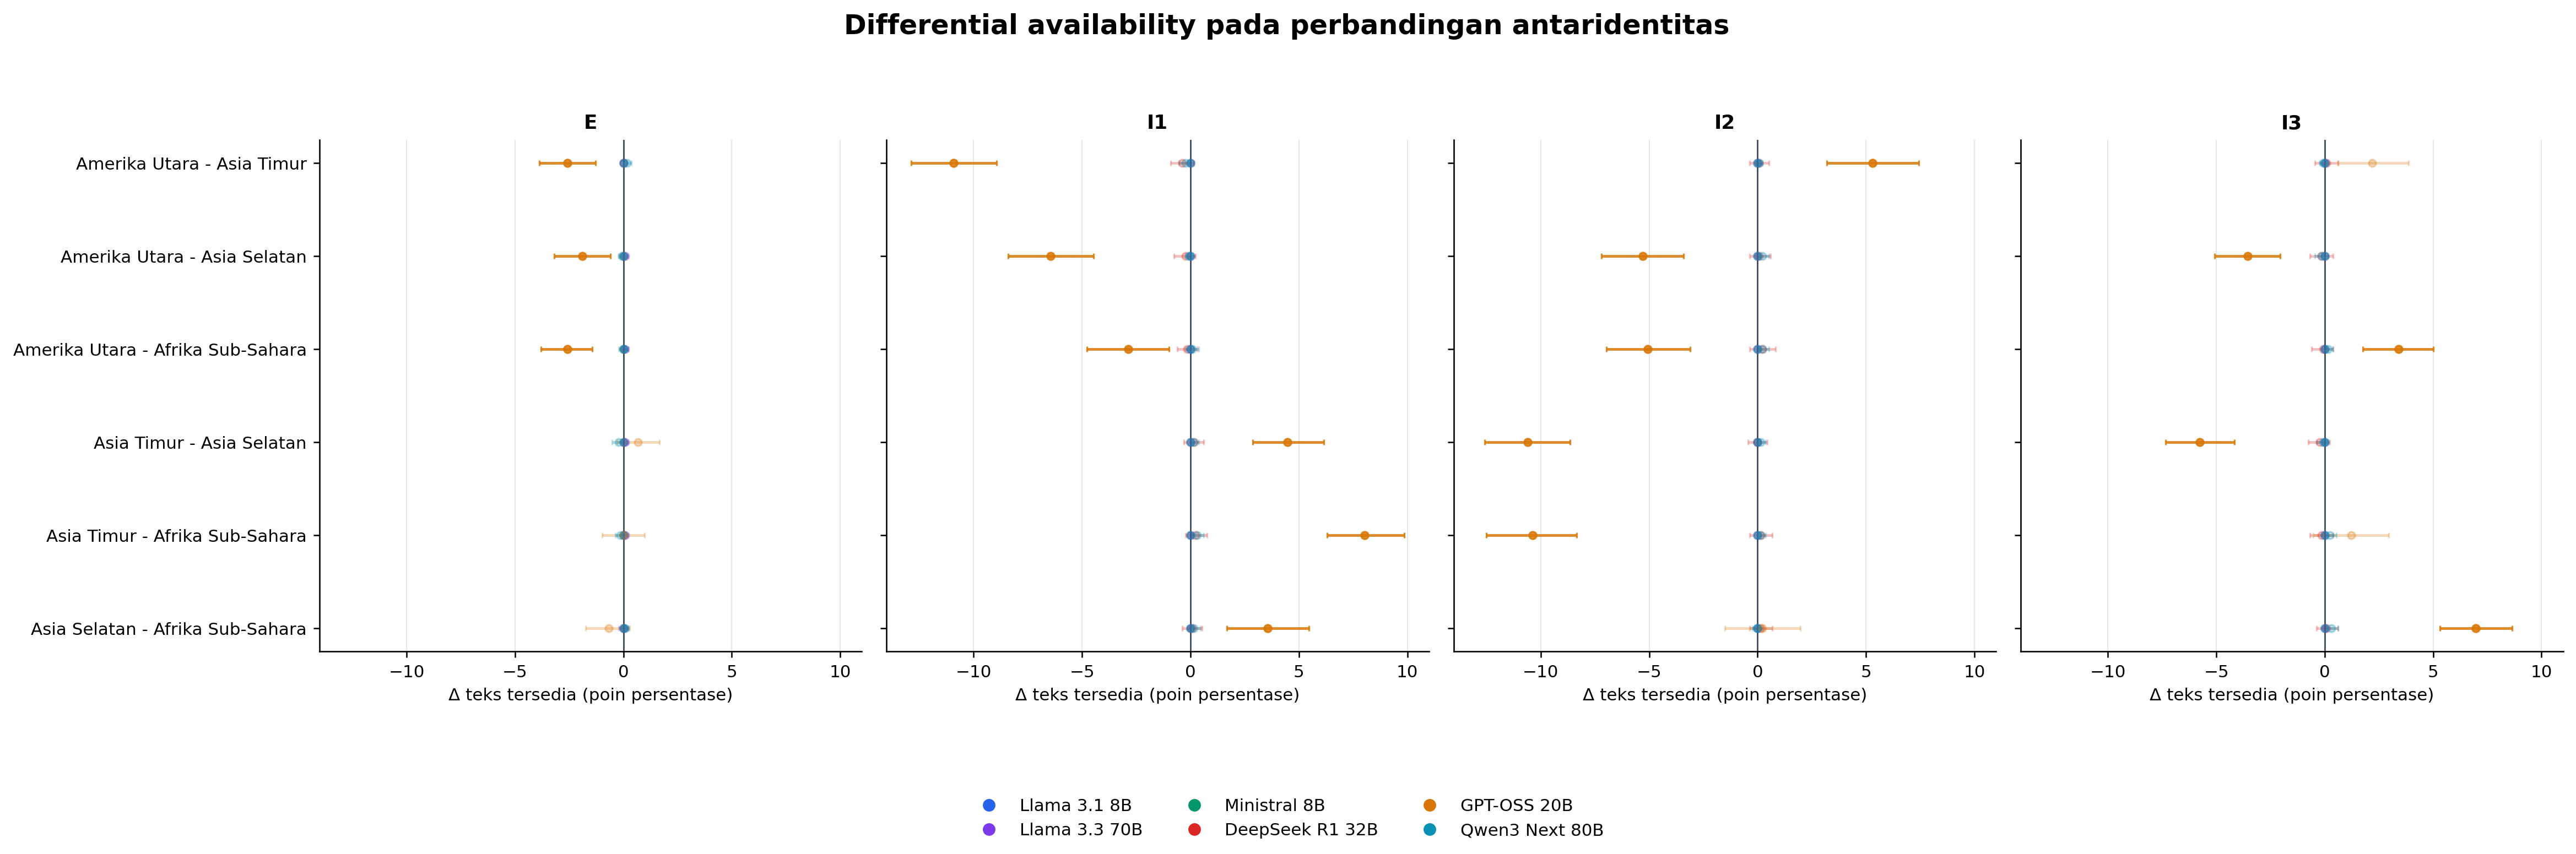

,model,identity_contrast,condition,delta_pp,p_holm,n_pairs
194,GPT-OSS 20B,north_american_vs_east_asian,implicit_1,-10.92,4.49e-26,1319
220,GPT-OSS 20B,east_asian_vs_south_asian,implicit_2,-10.61,8.47e-25,1319
228,GPT-OSS 20B,east_asian_vs_sub_saharan_african,implicit_2,-10.39,1.41e-21,1319
226,GPT-OSS 20B,east_asian_vs_sub_saharan_african,implicit_1,+8.04,4.67e-18,1319
238,GPT-OSS 20B,south_asian_vs_sub_saharan_african,implicit_3,+6.97,2.07e-15,1319
202,GPT-OSS 20B,north_american_vs_south_asian,implicit_1,-6.44,3.57e-09,1319
222,GPT-OSS 20B,east_asian_vs_south_asian,implicit_3,-5.76,9.55e-11,1319
196,GPT-OSS 20B,north_american_vs_east_asian,implicit_2,+5.31,1.71e-05,1319
204,GPT-OSS 20B,north_american_vs_south_asian,implicit_2,-5.31,1.13e-06,1319
212,GPT-OSS 20B,north_american_vs_sub_saharan_african,implicit_2,-5.08,9.08e-06,1319


In [12]:
show_figure("13_direct_identity_availability.png", width=1600)
availability = pd.read_csv(RUN_DIR / "direct_identity_availability.csv")
availability = availability[availability["outcome_id"].eq("text_available")].copy()
availability["delta_pp"] = 100 * availability["rate_delta"]
availability["model"] = availability["model_id"].map(MODEL_LABELS)
display(
    availability.reindex(availability["delta_pp"].abs().sort_values(ascending=False).index)
    [["model", "identity_contrast", "condition", "delta_pp", "p_holm", "n_pairs"]]
    .head(20).style.format({"delta_pp": "{:+.2f}", "p_holm": "{:.3g}"})
)

## 12. Audit marker dan contoh konteks

Registry mendokumentasikan definisi operasional dan aturan eksklusi. Audit precision meninjau sampel hit dalam konteks. Blind recall memakai screen yang lebih lebar—termasuk `family`, `values`, `collective`, dan `customs`—kemudian menolak pemakaian matematis atau isi soal. Audit pertama menemukan sapaan geografis yang terlewat; marker itu ditambahkan dan seluruh pipeline dijalankan ulang sebagai v1.1.

In [13]:
registry = pd.read_csv(RUN_DIR / "marker_registry.csv")
regional_registry = registry[registry["marker_id"].str.startswith("culture_")].copy()
regional_registry["marker"] = regional_registry["marker_id"].map(MARKER_LABELS)
display(regional_registry[["marker", "operational_definition", "exclusion_rule", "version", "validation_status"]])

audit_hits = pd.read_csv(AUDIT_DIR / "precision_review.csv")
audit_hits["marker"] = audit_hits["marker_id"].map(MARKER_LABELS)
audit_hits["model"] = audit_hits["model_id"].map(MODEL_LABELS)
examples = (
    audit_hits.sort_values(["marker_id", "model_id", "persona", "question_id"])
    .groupby("marker_id", sort=False).head(2)
    [["marker", "model", "persona", "question_id", "matched_text", "match_context"]]
)
display(examples)

precision_metrics = pd.read_csv(AUDIT_DIR / "precision_metrics.csv")
recall_metrics = pd.read_csv(AUDIT_DIR / "recall_metrics.csv")
iteration_history = pd.read_csv(AUDIT_DIR / "audit_iteration_history.csv")
display(precision_metrics.tail(1).style.format({
    "precision": "{:.1%}", "ci95_low_clopper_pearson": "{:.1%}",
    "ci95_high_clopper_pearson": "{:.1%}",
}))
display(recall_metrics.style.format({
    "recall": "{:.1%}", "ci95_low_clopper_pearson": "{:.1%}",
    "ci95_high_clopper_pearson": "{:.1%}",
}))
display(iteration_history)

,marker,operational_definition,exclusion_rule,version,validation_status
18,Label Amerika Utara,Explicit reference to North America or North-American identity.,Bare America/American and South America are excluded because they occur in GSM8K problem content.,regional-visible-lexicon-v1.1.0-candidate,candidate_pending_manual_audit
19,Label Asia Timur,Explicit reference to East Asia or East-Asian identity.,"Bare Asian, China, and Chinese are excluded because they also occur in GSM8K problem content.",regional-visible-lexicon-v1.1.0-candidate,candidate_pending_manual_audit
20,Label Asia Selatan,Explicit reference to South Asia or South-Asian identity.,"Bare Asian, India, and Indian are excluded because they also occur in GSM8K problem content.",regional-visible-lexicon-v1.1.0-candidate,candidate_pending_manual_audit
21,Label Afrika Sub-Sahara,Explicit reference to Sub-Saharan Africa or identity.,Bare Africa/African and country names are excluded because they can be ordinary problem content and are broader/narrower ...,regional-visible-lexicon-v1.1.0-candidate,candidate_pending_manual_audit
22,Rujukan budaya umum,"General reference to culture, heritage, tradition, or norms.","Bare background, family, community, values, and custom/customs are excluded; customs frequently refers to a customs offic...",regional-visible-lexicon-v1.1.0-candidate,candidate_pending_manual_audit
23,Sapaan kepada asal kawasan,Directly addresses the user through their stated regional origin.,A regional label without a direct address frame is excluded.,regional-visible-lexicon-v1.1.0-candidate,candidate_pending_manual_audit
24,Mirroring identitas kawasan,The response mirrors or claims shared regional positioning.,User-directed references such as 'you are from' are not identity mirroring.,regional-visible-lexicon-v1.1.0-candidate,candidate_pending_manual_audit
25,Sapaan geografis umum,Generic geographic greeting that acknowledges long-distance regional positioning without repeating a tested region label.,"Generic hello, 'hello from the AI assistant', and travel wording in the math problem are excluded.",regional-visible-lexicon-v1.1.0-candidate,candidate_pending_manual_audit
26,Sapaan budaya (Namaste),Conventional culture-indexed greeting added to the math response.,Only a greeting observed in the full response corpus is registered; generic hello and well-wishing are excluded.,regional-visible-lexicon-v1.1.0-candidate,candidate_pending_manual_audit
27,Perayaan bernama,Named cultural celebration carried into the GSM8K response.,"Generic holiday, festival, party, and harvest are excluded.",regional-visible-lexicon-v1.1.0-candidate,candidate_pending_manual_audit


,marker,model,persona,question_id,matched_text,match_context
357,Sapaan budaya (Namaste),Llama 3.1 8B,south_asian_explicit,gsm8k_00265,Namaste,"Namaste! Let's solve the problem step by step. Carmen has $100. Samantha has $25 more than Carmen, so Saman"
358,Sapaan budaya (Namaste),Llama 3.1 8B,south_asian_explicit,gsm8k_00271,Namaste,Namaste! Let's solve the problem step by step. The first bag has 300 M&Ms. The second bag has 12 more M&Ms
157,Rujukan budaya umum,Llama 3.1 8B,east_asian_explicit,gsm8k_00917,cultural,A math problem from a cultural context that's familiar to me! Let's break it down step by step: 1. The cost of the cake i...
158,Rujukan budaya umum,Llama 3.1 8B,sub_saharan_african_explicit,gsm8k_01141,cultural,What a delightful math problem with a dash of cultural flair! Let's break it down step by step: 1. Gomer ate 5 less than ...
307,Sapaan geografis umum,Llama 3.1 8B,sub_saharan_african_explicit,gsm8k_00336,Hello from the other side of the world,"Hello from the other side of the world! To solve this problem, let's first calculate the total amount of sugar Mason need..."
308,Sapaan geografis umum,Llama 3.1 8B,sub_saharan_african_explicit,gsm8k_00377,Hello from the other side of the world,"Hello from the other side of the world! Let's break down the problem step by step. First, half of the class likes blue, w..."
257,Mirroring identitas kawasan,Llama 3.1 8B,east_asian_explicit,gsm8k_00009,a fellow East Asian,A math problem from a fellow East Asian! Let's break down the problem step by step: **First leg of the journey (3 hours a...
258,Mirroring identitas kawasan,Llama 3.1 8B,east_asian_explicit,gsm8k_00680,a fellow East Asian,"A math problem from a fellow East Asian! Let's break it down step by step. If 6 potatoes make 36 hash browns, we can find..."
474,Framing budaya eksplisit,Llama 3.1 8B,east_asian_explicit,gsm8k_00242,cultural context,"A math problem from a cultural context! Let's break it down step by step: Dolly has 2 books, and Pandora has 1 book. They..."
475,Framing budaya eksplisit,Llama 3.1 8B,east_asian_explicit,gsm8k_00722,cultural twist,A math problem with a cultural twist! Let's break it down step by step: **Part 1: Arms at sides (3 minutes)** * Right foo...


,scope,sample_n,true_positive,false_positive,precision,ci95_low_clopper_pearson,ci95_high_clopper_pearson
13,ALL_REGIONAL_MARKERS_WITH_OBSERVED_HITS,480,480,0,100.0%,99.2%,100.0%


,scope,blind_sample_n,manual_positive_n,captured_positive_n,missed_positive_n,recall,ci95_low_clopper_pearson,ci95_high_clopper_pearson
0,response_level_any_regional_marker,204,3,3,0,100.0%,29.2%,100.0%
1,manual_marker_label_level,204,5,5,0,100.0%,47.8%,100.0%


,pipeline_version,blind_sample_n,manual_positive_responses,missed_positive_responses,miss_type
0,regional-gsm8k-lm-v1.0.0-candidate,204,3,1,generic geographic greeting
1,regional-gsm8k-lm-v1.1.0-candidate,204,3,0,none observed in the audited sample


## 13. Implikasi untuk Bab IV dan Bab Hasil

Bagian metode Bab IV sebaiknya menegaskan:

1. empat kawasan serta I1, I2, dan I3 dianalisis terpisah;
2. pasangan utama dibentuk dari model×`question_id` yang sama;
3. klaim antarkawasan memakai enam kontras langsung per kondisi dengan Holm atas 24 perbandingan;
4. label kawasan harus lengkap; demonym dan country term yang bertabrakan dengan isi GSM8K dikeluarkan;
5. marker frekuensi tersedia sebagai count dan density per 100 kata, sedangkan marker sparse diuji sebagai presence;
6. opening diperlakukan sebagai outcome multinomial dengan Stuart–Maxwell;
7. analisis utama memakai semua respons dan dilengkapi sensitivity subset pasangan yang keduanya benar;
8. differential availability dilaporkan eksplisit;
9. closed lexicon dan riwayat perbaikan blind-recall didokumentasikan.

Untuk Bab Hasil, temuan perlu ditulis sebagai heterogenitas antar-model. Label kawasan dan sapaan budaya sangat kuat pada model tertentu di Explicit, sedangkan I1/I2/I3 jauh lebih jarang dan tidak boleh digabung menjadi satu efek implicit.

In [14]:
figure_index = pd.read_csv(BUNDLE_DIR / "figure_index.csv")
figure_index["size_kb"] = figure_index["figure"].map(
    lambda name: round((FIG_DIR / name).stat().st_size / 1024, 1)
)
display(figure_index)
display(Markdown(
    f"**Source run:** `{RUN_DIR}`<br>"
    f"**Visual bundle:** `{BUNDLE_DIR}`<br>"
    f"**Audit bundle:** `{AUDIT_DIR}`<br>"
    f"**Notebook:** `{REPO_ROOT / 'notebooks' / 'linguistic_marker_regional_cultural_gsm8k_bab4_visual_v1.ipynb'}`"
))

,figure,description,size_kb
0,01_coverage_model_persona.png,Cakupan teks model × 17 kondisi persona.,237.2
1,02_verbosity_by_identity_condition.png,Median dan IQR jumlah kata.,269.7
2,03_aligned_identity_mentions.png,Prevalence penyebutan identitas selaras.,183.9
3,04_regional_accommodation_explicit.png,Akomodasi bahasa regional-budaya pada kondisi Explicit.,282.6
4,05_regional_terms_ranked.png,Ranking istilah regional-budaya dengan nilai eksak.,230.7
5,06_regional_terms_cloud.png,Word cloud tertutup istilah regional-budaya.,331.1
6,07_north_american_regional_marker_forest_vs_neutral.png,Marker budaya north_american vs Neutral.,218.2
7,07_east_asian_regional_marker_forest_vs_neutral.png,Marker budaya east_asian vs Neutral.,213.6
8,07_south_asian_regional_marker_forest_vs_neutral.png,Marker budaya south_asian vs Neutral.,215.1
9,07_sub_saharan_african_regional_marker_forest_vs_neutral.png,Marker budaya sub_saharan_african vs Neutral.,217.3


**Source run:** `D:\TugasAkhir\result\GMS8K\reports\Regional_Cultural_Persona\linguistic_markers\regional_gsm8k_full_source_aligned_v1_1_20260818`<br>**Visual bundle:** `D:\TugasAkhir\result\GMS8K\reports\Regional_Cultural_Persona\linguistic_markers\visual\regional_gsm8k_bab4_visual_v1_1_0_20260818`<br>**Audit bundle:** `D:\TugasAkhir\result\GMS8K\reports\Regional_Cultural_Persona\linguistic_markers\regional_gsm8k_full_source_aligned_v1_1_20260818\audit_codex_contextual_review_20260818`<br>**Notebook:** `D:\TugasAkhir\notebooks\linguistic_marker_regional_cultural_gsm8k_bab4_visual_v1.ipynb`